## 1. 라이브러리 임포트

노트북 전체(EDA, 전처리, 모델 설계, 학습, 평가)에서 사용하는 라이브러리를 불러옵니다.
- `torch`: 텐서 연산
- `torch.nn`: 신경망 층(합성곱, 완전연결 등)과 모델 정의 (모델 설계)
- `torchvision.datasets`: FashionMNIST 데이터셋 제공
- `torchvision.transforms`: 이미지를 텐서로 변환
- `torchvision.transforms.v2`: GAN 학습용 픽셀 값 변환 (전처리)
- `torch.utils.data.DataLoader`: 데이터를 일정 개수씩 묶어서 꺼내기 (전처리)
- `numpy`: 배열 기반 수치 계산 (EDA, 전처리)
- `matplotlib`: 이미지 및 그래프 시각화 (EDA, 전처리)
- `sys`: 실행 중인 Python 버전 확인
- `time`: 에폭마다 걸린 학습 시간 측정 (학습)
- `pathlib.Path`: 학습 파일을 저장할 폴더와 파일 경로 다루기 (학습 설정)

In [223]:
import sys
import time
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.transforms import v2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# 실행 환경의 버전 확인 (팀원 간 환경 차이로 오류가 생겼을 때 원인 파악용)
print(f"Python      : {sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")

Python      : 3.12.14
torch       : 2.14.1+cu130
torchvision : 0.29.1+cu130
numpy       : 2.5.4
matplotlib  : 3.11.2


## 2. FashionMNIST 데이터셋 불러오기

FashionMNIST는 10개 의류 클래스로 구성된 28×28 흑백 이미지 데이터셋입니다.
- 학습 데이터: 60,000장
- 테스트 데이터: 10,000장

- 클래스 목록:
    - T-shirt/top
    - Trouser
    - Pullover
    - Dress
    - Coat
    - Sandal
    - Shirt
    - Sneaker
    - Bag
    - Ankle boot

EDA 결과를 해석하기 쉽도록, 이 단계에서는 `ToTensor()`만 적용합니다.
`ToTensor()`는 0~255 정수 픽셀을 255로 나눠 0.0~1.0 실수로 바꿉니다.
생성 모델 학습에 필요한 정규화는 이후 전처리 단계에서 별도로 적용합니다.

데이터는 레포 규칙(`data/README.md`)에 따라 레포 최상위의 `data/raw/`에 저장합니다.
노트북이 `eda/` 폴더에 있으므로 상대 경로 `../data/raw`를 사용합니다.

In [224]:
# 데이터셋을 저장할 경로 (없으면 자동 생성)
DATA_ROOT = '../data/raw'

# PIL 이미지(uint8, 0~255) → FloatTensor(0.0~1.0), shape: (채널=1, 높이=28, 너비=28)
eda_transform = transforms.ToTensor()

# 학습 데이터셋 (train=True) - 로컬에 없으면 다운로드
train_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=eda_transform
)

# 테스트 데이터셋 (train=False)
test_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=eda_transform
)

## 3. 데이터셋 로드 결과 확인

데이터가 정상적으로 로드되었는지 간단히 확인합니다.
- 학습/테스트 데이터 개수
- 샘플 1개의 shape, 자료형, 픽셀 값 범위
- 클래스 인덱스와 클래스 이름의 매핑 (이후 EDA와 시각화에서 사용)

In [225]:
# 데이터 개수 확인
print(f"학습 데이터 개수  : {len(train_dataset):,}")
print(f"테스트 데이터 개수: {len(test_dataset):,}")

# 첫 번째 샘플로 변환 결과 확인
img, label = train_dataset[0]
print(f"\n이미지 shape : {tuple(img.shape)}")   # (1, 28, 28) 예상
print(f"이미지 dtype : {img.dtype}")            # torch.float32 예상
print(f"픽셀 값 범위 : [{img.min().item():.3f}, {img.max().item():.3f}]")  # 0~1 사이 예상
print(f"라벨         : {label} ({train_dataset.classes[label]})")

# 클래스 인덱스 → 클래스 이름 매핑
idx_to_class = {i: name for i, name in enumerate(train_dataset.classes)}
idx_to_class

학습 데이터 개수  : 60,000
테스트 데이터 개수: 10,000

이미지 shape : (1, 28, 28)
이미지 dtype : torch.float32
픽셀 값 범위 : [0.000, 1.000]
라벨         : 9 (Ankle boot)


{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

## 4. 클래스(옷 종류)별 이미지 개수 확인

옷 종류마다 이미지가 몇 장씩 있는지 직접 세어 확인합니다.

### 방법
- 학습/테스트 데이터셋에서 `targets` 속성의 값을 꺼내, 값별로 개수를 셉니다.
- 이 값이 각 이미지의 클래스 번호인지는 결과로 확인합니다.
  - 값별 개수의 합계가 이미지 수(학습 60,000 / 테스트 10,000)와 같은가?
  - 값이 클래스 번호 범위(0~9) 안에 있는가?
- 결과는 표(정확한 숫자)와 막대그래프(한눈에 비교)로 확인합니다.
  - 학습과 테스트는 전체 규모가 달라서, 그래프를 두 개로 나눠 그립니다.
  - 그래프 안의 글자는 한글이 깨지지 않도록 영어로 표시합니다.

### 확인할 점
- 클래스마다 개수가 고르게 나뉘어 있는가?

No  Class          Train  Train %    Test  Test %
-------------------------------------------------
 0  T-shirt/top    6,000    10.0%   1,000   10.0%
 1  Trouser        6,000    10.0%   1,000   10.0%
 2  Pullover       6,000    10.0%   1,000   10.0%
 3  Dress          6,000    10.0%   1,000   10.0%
 4  Coat           6,000    10.0%   1,000   10.0%
 5  Sandal         6,000    10.0%   1,000   10.0%
 6  Shirt          6,000    10.0%   1,000   10.0%
 7  Sneaker        6,000    10.0%   1,000   10.0%
 8  Bag            6,000    10.0%   1,000   10.0%
 9  Ankle boot     6,000    10.0%   1,000   10.0%
-------------------------------------------------
    Total         60,000   100.0%  10,000  100.0%


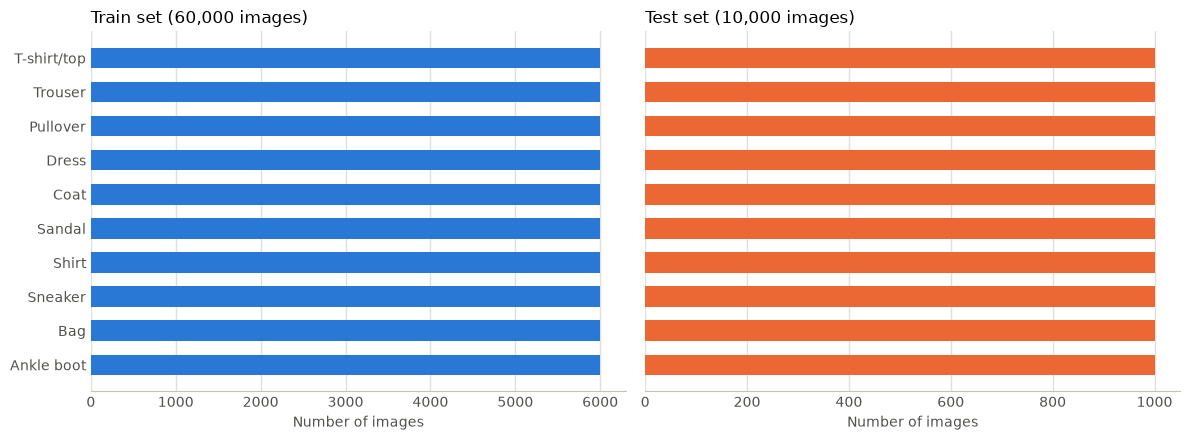

In [226]:
# 4-1. 학습/테스트 데이터셋의 targets 값 꺼내기
#  - 이미지를 한 장씩 불러오지 않고 targets 값만 한 번에 꺼냅니다.
#  - 이 값이 각 이미지의 클래스 번호인지는 아래 표의 결과(합계, 값 범위)로 확인합니다.
train_labels = train_dataset.targets.numpy()
test_labels = test_dataset.targets.numpy()

class_names = train_dataset.classes   # ['T-shirt/top', 'Trouser', ...]
num_classes = len(class_names)        # 10

# 4-2. 클래스별 개수 세기
#  - np.bincount: 0, 1, 2, ... 각 번호가 몇 번 나오는지 셉니다.
#  - minlength=num_classes: 개수가 0인 클래스가 있어도 결과 길이를 10으로 맞춥니다.
train_counts = np.bincount(train_labels, minlength=num_classes)
test_counts = np.bincount(test_labels, minlength=num_classes)

# 4-3. 표로 출력 (클래스별 개수 + 전체 대비 비율)
print(f"{'No':>2}  {'Class':<12} {'Train':>7} {'Train %':>8} {'Test':>7} {'Test %':>7}")
print("-" * 49)
for i, name in enumerate(class_names):
    train_ratio = train_counts[i] / train_counts.sum() * 100
    test_ratio = test_counts[i] / test_counts.sum() * 100
    print(f"{i:>2}  {name:<12} {train_counts[i]:>7,} {train_ratio:>7.1f}% "
          f"{test_counts[i]:>7,} {test_ratio:>6.1f}%")
print("-" * 49)
print(f"{'':>2}  {'Total':<12} {train_counts.sum():>7,} {'100.0%':>8} "
      f"{test_counts.sum():>7,} {'100.0%':>7}")

# 4-4. 막대그래프로 시각화
#  - 학습/테스트는 전체 개수 규모가 달라서(60,000 vs 10,000) 그래프를 두 개로 나눠 그립니다.
#  - 클래스 이름이 길어서 가로 막대그래프(barh)를 사용합니다.
#  - 그래프 안의 글자는 영어로 씁니다. (matplotlib 기본 글꼴은 한글이 깨져서 보이기 때문)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, counts, title, color in zip(
    axes,
    [train_counts, test_counts],
    [f"Train set ({train_counts.sum():,} images)", f"Test set ({test_counts.sum():,} images)"],
    ["#2a78d6", "#eb6834"],   # 학습: 파란색, 테스트: 주황색
):
    ax.barh(range(num_classes), counts, color=color, height=0.6)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Number of images", color="#52514e")
    ax.grid(axis="x", color="#e1e0d9", linewidth=1)   # 옅은 세로 보조선
    ax.set_axisbelow(True)                            # 보조선을 막대 뒤로 보내기
    for side in ["top", "right", "left"]:             # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", length=0)

axes[0].set_yticks(range(num_classes))
axes[0].set_yticklabels(class_names)
axes[0].invert_yaxis()   # 0번 클래스가 맨 위에 오도록 순서 뒤집기

plt.tight_layout()
plt.show()

### 결과
- 학습 데이터: 10개 클래스 모두 6,000장씩(각 10.0%)이고, 합계는 60,000장입니다.
- 테스트 데이터: 10개 클래스 모두 1,000장씩(각 10.0%)이고, 합계는 10,000장입니다.
- 막대그래프에서도 학습/테스트 모두 클래스마다 막대 길이가 같습니다.

### 해석
- `targets` 값이 각 이미지의 클래스 번호인가?
  - 값별 개수의 합계(학습 60,000 / 테스트 10,000)가 '3. 데이터셋 로드 결과 확인'의 실행 결과에서 확인한 이미지 수와 같습니다. 이미지마다 `targets` 값이 하나씩 있다는 뜻입니다.
  - 0~9번 개수를 모두 더한 값이 전체 합계와 같으므로, 0~9 밖의 값은 없습니다.
  - 두 기준을 모두 만족하므로, 이후 단계에서는 `targets` 값을 각 이미지의 클래스 번호로 사용합니다. 번호와 실제 이미지가 맞는지는 '5. 클래스별 샘플 이미지 확인'에서 이미지로 확인합니다.
- 클래스마다 개수가 고르게 나뉘어 있는가?
  - 학습/테스트 모두 모든 클래스의 개수가 같아, 클래스 간 개수 차이(불균형)가 없습니다.

## 5. 클래스별 샘플 이미지 확인

옷 종류마다 실제 이미지가 어떻게 생겼는지 눈으로 확인합니다.

### 방법
- '4. 클래스(옷 종류)별 이미지 개수 확인'에서 꺼낸 학습 데이터의 `targets` 값을 기준으로, 클래스마다 5장씩 무작위로 골라 10줄 × 5칸으로 보여줍니다.
- 랜덤 시드(`SEED = 42`)를 고정해서, 다시 실행하거나 팀원이 실행해도 같은 이미지가 나오도록 합니다.
- 데이터셋의 `data` 속성에 저장된 이미지를 흑백으로 표시합니다.
  - 모든 이미지의 밝기 기준을 같게 하기 위해 표시 범위를 0~255로 고정합니다.

### 확인할 점
- 옷 종류마다 어떻게 생겼는가?
- 서로 헷갈릴 만한 비슷한 종류가 있는가?
- 같은 종류 안에서도 모양이 얼마나 다양한가?

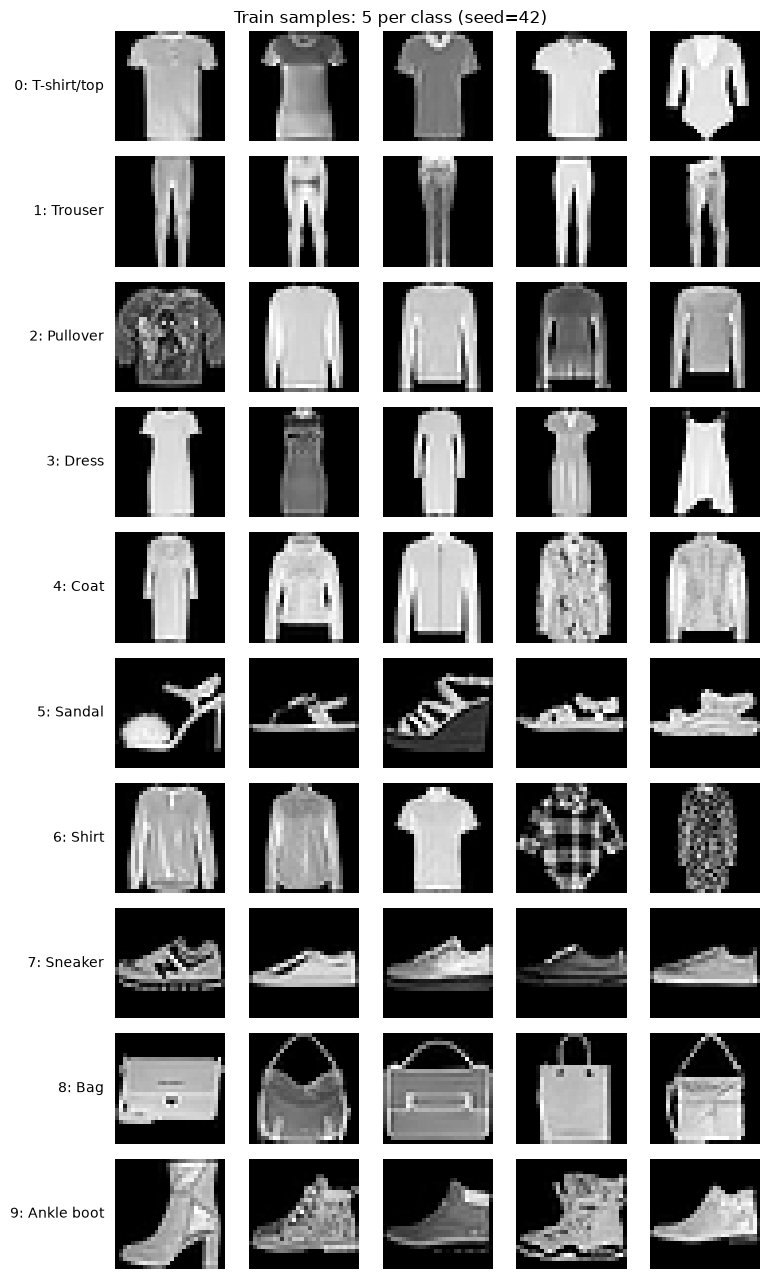

In [227]:
# 5-1. 설정값
N_SAMPLES_PER_CLASS = 5   # 클래스마다 보여줄 이미지 수
SEED = 42                 # 랜덤 시드: 실행할 때마다 같은 이미지가 뽑히도록 고정

rng = np.random.default_rng(SEED)

# 5-2. 그림판 만들기: 10줄(클래스) x 5칸(이미지)
fig, axes = plt.subplots(
    num_classes, N_SAMPLES_PER_CLASS,
    figsize=(N_SAMPLES_PER_CLASS * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    # 5-3. 이 클래스에 속하는 이미지들의 위치(인덱스) 찾기
    #  - train_labels는 '4. 클래스(옷 종류)별 이미지 개수 확인'에서 꺼낸 학습 데이터의 targets 값입니다.
    class_indices = np.where(train_labels == class_idx)[0]

    # 5-4. 그중 N장을 중복 없이 무작위로 선택
    chosen = rng.choice(class_indices, size=N_SAMPLES_PER_CLASS, replace=False)

    for col, img_idx in enumerate(chosen):
        ax = axes[class_idx, col]

        # 5-5. data 속성에 저장된 이미지를 흑백으로 표시
        #  - vmin/vmax를 0~255로 고정해서 모든 이미지의 밝기 기준을 똑같이 맞춥니다.
        img = train_dataset.data[img_idx].numpy()
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)

        # 눈금과 테두리 제거 (이미지만 보이도록)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    # 5-6. 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Train samples: {N_SAMPLES_PER_CLASS} per class (seed={SEED})", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
클래스마다 5장씩만 본 결과이므로, 아래 내용은 이 샘플에서 관찰한 것입니다.
아래에서 'n번째'는 각 줄의 왼쪽부터 센 순서입니다.

- 옷 종류마다 어떻게 생겼는가?
  - 배경은 검은색이고, 물건은 배경보다 밝은 회색~흰색으로 표시됩니다.
  - 모든 이미지에 물건이 하나씩, 가운데에 크게 놓여 있습니다.
  - 옷(T-shirt/top, Trouser, Pullover, Dress, Coat, Shirt)과 Bag은 앞에서 본 모습입니다.
  - 신발(Sandal, Sneaker, Ankle boot)은 옆에서 본 모습이고, 15장 모두 앞코가 왼쪽을 향합니다.
- 서로 헷갈릴 만한 비슷한 종류가 있는가?
  - 긴팔 상의인 Pullover(2, 3, 5번째), Coat(3, 5번째), Shirt(1, 2번째)는 전체 윤곽이 서로 비슷합니다.
  - Shirt 3번째는 반팔이라 T-shirt/top(1~4번째)과 윤곽이 비슷합니다.
  - Coat 1번째는 길이가 길어 Dress 3번째와 윤곽이 비슷합니다.
- 같은 종류 안에서도 모양이 얼마나 다양한가?
  - 무늬: Pullover 1번째, Coat 4번째, Shirt 4, 5번째는 무늬가 있고, 같은 줄의 다른 이미지는 무늬가 거의 없습니다.
  - 밝기: Trouser 3번째, Dress 2번째, Sneaker 4번째는 같은 줄의 다른 이미지보다 어둡습니다.
  - 모양:
    - T-shirt/top: 1~4번째는 반팔이고, 5번째는 긴팔에 아랫단이 뾰족합니다.
    - Dress: 반팔(1, 4번째), 긴팔(3번째), 어깨끈 형태(5번째)로 소매 모양이 다릅니다.
    - Sandal: 굽이 높은 것(1번째), 밑창이 두꺼운 것(3번째), 납작한 것(2, 4, 5번째)이 섞여 있습니다.
    - Bag: 손잡이가 보이지 않는 것(1번째)과 손잡이나 끈이 달린 것(2~5번째)이 섞여 있습니다.
    - Ankle boot: 굽이 높은 것(1번째)과 굽이 낮은 것(2~5번째)이 섞여 있습니다.

### 해석
- 각 줄의 이미지가 왼쪽에 적힌 클래스 이름에 해당하는 물건으로 보입니다. '4. 클래스(옷 종류)별 이미지 개수 확인'에서 사용한 `targets` 값이 실제 이미지의 클래스 번호와 맞는다는 것을 눈으로 확인했습니다.
- 5장만 본 결과이므로, 위의 관찰이 데이터 전체에도 해당하는지는 이 셀만으로는 알 수 없습니다.

## 6. 이상치 확인

학습/테스트 데이터에 크기나 형식이 다른 이미지, 비어 있는 이미지 같은 이상치가 있는지 확인합니다.

### 목적
- 데이터는 사람이 만들고 정리하기 때문에, 실수로 이상한 이미지가 섞여 있을 수 있습니다.
- 학습 전에 빼야 할 이미지가 있는지 확인하고, 있으면 제거 대상으로 기록합니다.

### 방법
- 크기와 형식
  - 데이터셋의 `data` 속성은 이미지 전체를 하나의 배열로 묶어 저장합니다. 하나의 배열 안에 있는 이미지는 모두 같은 크기여야 하므로, 크기가 다른 이미지가 있는지는 배열의 shape로 확인합니다.
  - 학습/테스트 배열의 shape와 자료형(dtype)을 출력합니다.
- 값 범위: 학습/테스트 전체 픽셀의 최솟값과 최댓값을 출력합니다.
- 빈 이미지
  - 이미지마다 0(검은색)이 아닌 픽셀의 수를 셉니다. 이 값을 이미지 안에서 물건이 차지하는 크기로 봅니다.
  - 이 값이 0인 이미지, 즉 완전히 검은 이미지가 몇 장인지 학습/테스트 각각 출력합니다.
- 시각화
  - 그림 1: 0이 아닌 픽셀 수의 분포를 클래스별 박스 플롯으로 그립니다.
    - 박스는 가운데 50%의 이미지가 모인 범위이고, 박스 안의 선은 중앙값입니다.
    - 박스 끝에서 박스 길이의 1.5배보다 멀리 떨어진 이미지는 점으로 따로 표시됩니다(matplotlib 기본 설정).
    - 물건의 크기는 클래스마다 다를 수 있으므로, 전체가 아닌 클래스별로 비교합니다.
    - 학습/테스트를 두 그래프로 나란히 그리고, '4. 클래스(옷 종류)별 이미지 개수 확인'과 같은 방향(가로)과 색(학습 파랑, 테스트 주황)을 사용합니다.
  - 그림 2: 클래스마다 0이 아닌 픽셀 수가 가장 적은 이미지 3장을 학습/테스트 각각 보여 줍니다.
    - 10줄 × 6칸으로, 왼쪽 3칸은 학습, 오른쪽 3칸은 테스트 이미지입니다.
    - 0이 아닌 픽셀 수가 0보다 크더라도 거의 빈 이미지일 수 있으므로, 최종 판단은 이미지를 직접 보고 합니다.
  - 그림 3: 클래스마다 0이 아닌 픽셀 수가 가장 많은 이미지 3장을 그림 2와 같은 방식으로 보여 줍니다.
    - 0이 아닌 픽셀에는 아주 흐린 픽셀(값 1, 2 등)도 포함되므로, 값이 큰 이미지에는 물건이 큰 경우와 배경에 흐린 잡음이 있는 경우가 섞여 있을 수 있습니다.
    - 다른 그림과 같은 0~255 표시 범위로 그리기 때문에, 아주 흐린 잡음은 그림에서 검은색과 구별되지 않을 수 있습니다.
  - 그래프 안의 글자는 한글이 깨지지 않도록 영어로 표시합니다.

### 확인할 점
- 학습/테스트 모두 크기와 형식이 같은가?
- 완전히 빈 이미지가 있는가?
- 클래스별로 다른 이미지와 동떨어지게 작은 이미지가 있는가? 있다면 실제로 이상한 이미지인가?
- 0이 아닌 픽셀 수가 가장 많은 이미지는 실제로 물건이 화면을 크게 차지하는 이미지인가?

학습 이미지 : shape (60000, 28, 28), dtype uint8, 값 범위 [0, 255]
테스트 이미지 : shape (10000, 28, 28), dtype uint8, 값 범위 [0, 255]

빈 이미지 수            - 학습: 0장, 테스트: 0장
0이 아닌 픽셀 수 범위   - 학습: [54, 725], 테스트: [91, 746]


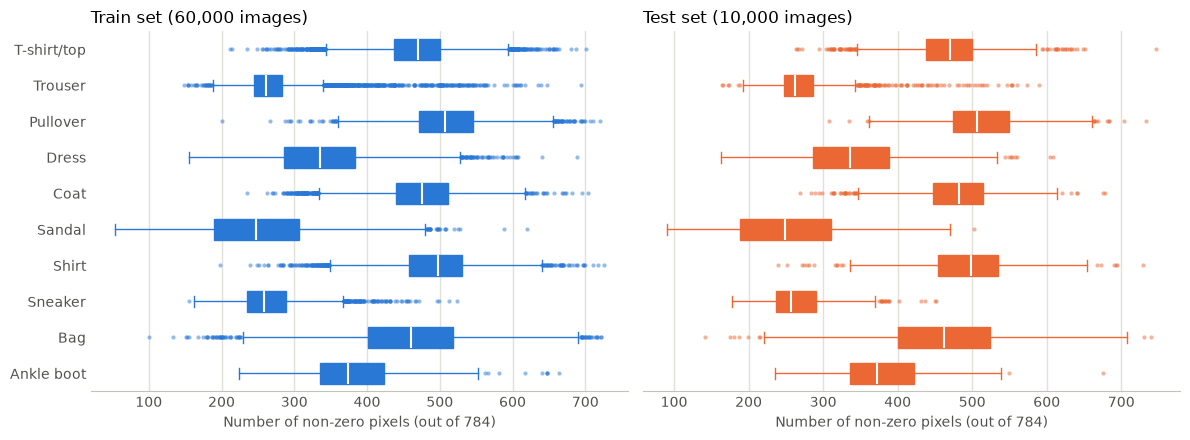

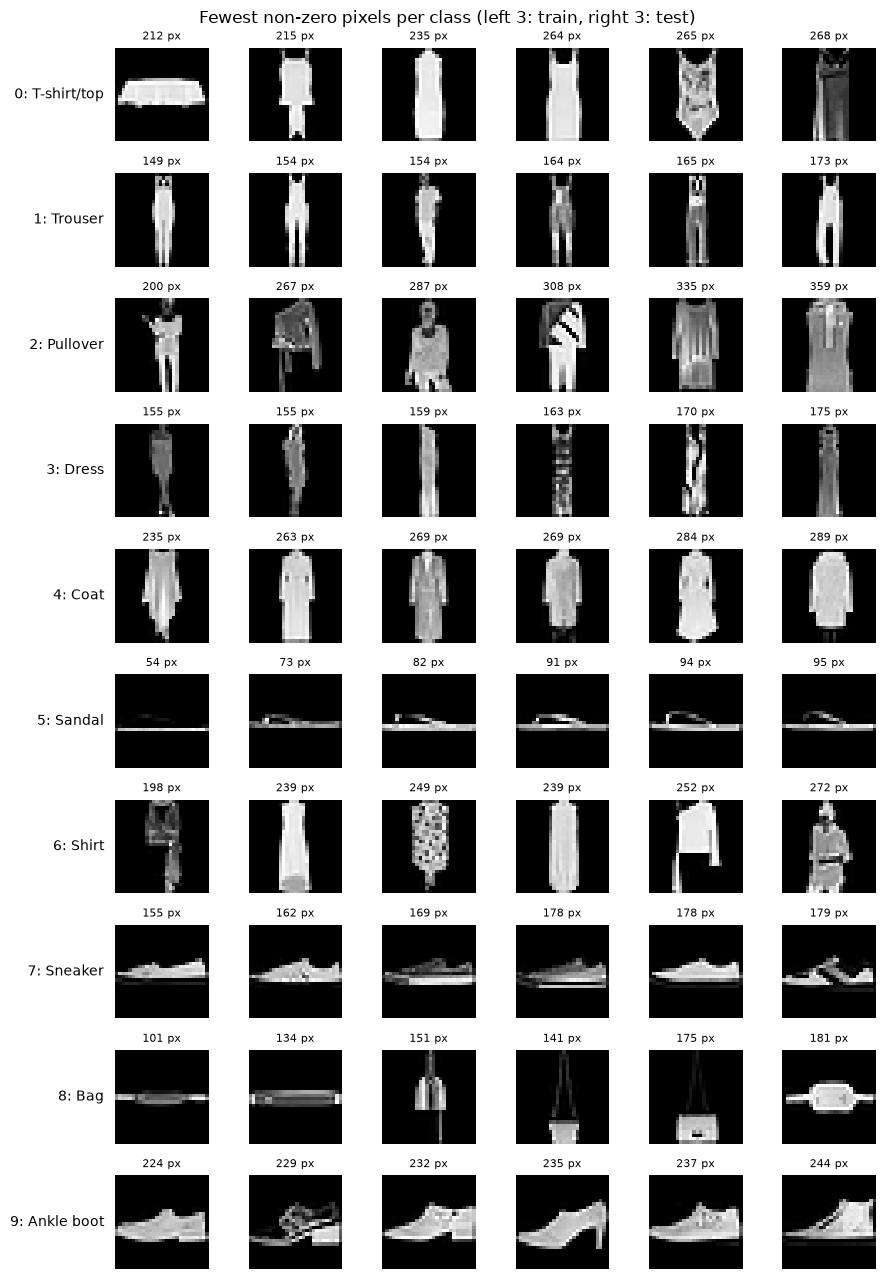

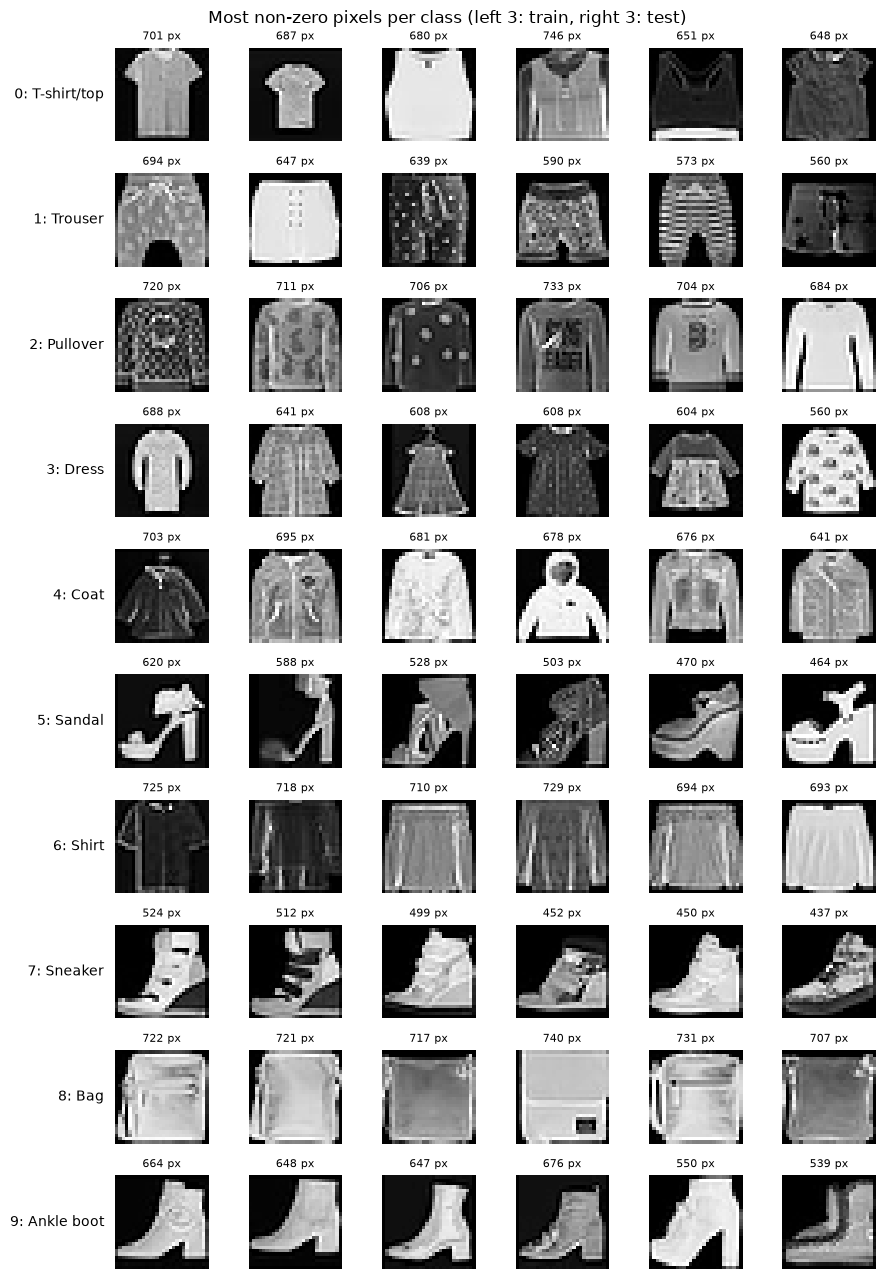

In [228]:
# 6-1. 학습/테스트 이미지 전체를 numpy 배열로 꺼내기
#  - data 속성: 데이터셋에 저장된 이미지 전체가 하나의 배열로 묶여 있습니다.
train_images = train_dataset.data.numpy()
test_images = test_dataset.data.numpy()

# 6-2. 크기·형식과 값 범위 출력
#  - shape: (이미지 수, 높이, 너비) → 하나의 배열이므로 모든 이미지의 높이·너비가 같습니다.
#  - min/max: 배열 전체에서 가장 작은 픽셀 값과 가장 큰 픽셀 값
for set_name, images in [("학습", train_images), ("테스트", test_images)]:
    print(f"{set_name} 이미지 : shape {images.shape}, dtype {images.dtype}, "
          f"값 범위 [{images.min()}, {images.max()}]")

# 6-3. 이미지마다 0(검은색)이 아닌 픽셀 수 세기
#  - images > 0        : 픽셀마다 0보다 크면 True, 아니면 False인 배열 (이미지 수, 28, 28)
#  - .sum(axis=(1, 2)) : 이미지 한 장 안에서 True의 개수를 셈 → 이미지마다 숫자 1개
train_nonzero = (train_images > 0).sum(axis=(1, 2))
test_nonzero = (test_images > 0).sum(axis=(1, 2))

# 6-4. 완전히 빈 이미지(0이 아닌 픽셀이 하나도 없는 이미지) 개수와 0이 아닌 픽셀 수의 범위
print(f"\n빈 이미지 수            - 학습: {(train_nonzero == 0).sum()}장, "
      f"테스트: {(test_nonzero == 0).sum()}장")
print(f"0이 아닌 픽셀 수 범위   - 학습: [{train_nonzero.min()}, {train_nonzero.max()}], "
      f"테스트: [{test_nonzero.min()}, {test_nonzero.max()}]")

# 6-5. 그림 1: 0이 아닌 픽셀 수의 분포를 클래스별 박스 플롯으로 그리기
#  - 학습/테스트를 두 그래프로 나란히 그립니다. (클래스 순서와 색은 '4. 클래스(옷 종류)별 이미지 개수 확인'과 같음)
#  - orientation="horizontal": 클래스 이름이 길어서 가로 방향으로 그립니다.
#  - 박스에서 멀리 떨어진 이미지는 점(flier)으로 따로 표시됩니다.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, nonzero, labels, title, color in zip(
    axes,
    [train_nonzero, test_nonzero],
    [train_labels, test_labels],
    [f"Train set ({len(train_nonzero):,} images)", f"Test set ({len(test_nonzero):,} images)"],
    ["#2a78d6", "#eb6834"],   # 학습: 파란색, 테스트: 주황색
):
    # 클래스별로 0이 아닌 픽셀 수만 모은 목록 (10개)
    per_class = [nonzero[labels == class_idx] for class_idx in range(num_classes)]

    ax.boxplot(
        per_class,
        positions=range(num_classes),
        orientation="horizontal",
        widths=0.6,
        patch_artist=True,                                     # 박스 안을 색으로 채우기
        boxprops=dict(facecolor=color, edgecolor=color),
        medianprops=dict(color="white", linewidth=1.5),        # 중앙값 선
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=color,
                        markeredgecolor="none", alpha=0.5),    # 동떨어진 이미지 점
    )
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Number of non-zero pixels (out of 784)", color="#52514e")
    ax.grid(axis="x", color="#e1e0d9", linewidth=1)   # 옅은 세로 보조선
    ax.set_axisbelow(True)                            # 보조선을 박스 뒤로 보내기
    for side in ["top", "right", "left"]:             # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", length=0)

axes[0].set_yticks(range(num_classes))
axes[0].set_yticklabels(class_names)
axes[0].invert_yaxis()   # 0번 클래스가 맨 위에 오도록 순서 뒤집기

plt.tight_layout()
plt.show()

# 6-6. 그림 2: 클래스마다 0이 아닌 픽셀 수가 가장 적은 이미지 3장 (왼쪽 3칸: 학습, 오른쪽 3칸: 테스트)
N_SMALLEST = 3   # 클래스마다 보여줄 이미지 수 (학습/테스트 각각)

fig, axes = plt.subplots(
    num_classes, N_SMALLEST * 2,
    figsize=(N_SMALLEST * 2 * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    for set_idx, (images, labels, nonzero) in enumerate([
        (train_images, train_labels, train_nonzero),
        (test_images, test_labels, test_nonzero),
    ]):
        # 이 클래스 이미지들의 위치(인덱스)를 0이 아닌 픽셀 수가 적은 순서로 정렬해서 앞에서 N개 선택
        #  - kind="stable": 픽셀 수가 같을 때 원래 순서를 유지해서, 다시 실행해도 같은 이미지가 나오도록 함
        class_indices = np.where(labels == class_idx)[0]
        order = np.argsort(nonzero[class_indices], kind="stable")
        smallest = class_indices[order[:N_SMALLEST]]

        for k, img_idx in enumerate(smallest):
            ax = axes[class_idx, set_idx * N_SMALLEST + k]
            ax.imshow(images[img_idx], cmap="gray", vmin=0, vmax=255)   # 다른 섹션과 같은 0~255 표시 범위
            ax.set_title(f"{nonzero[img_idx]} px", fontsize=8)           # 이 이미지의 0이 아닌 픽셀 수

            # 눈금과 테두리 제거 (이미지만 보이도록)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

    # 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Fewest non-zero pixels per class (left {N_SMALLEST}: train, right {N_SMALLEST}: test)", fontsize=12)
plt.tight_layout()
plt.show()

# 6-7. 그림 3: 클래스마다 0이 아닌 픽셀 수가 가장 많은 이미지 3장 (왼쪽 3칸: 학습, 오른쪽 3칸: 테스트)
#  - 0이 아닌 픽셀에는 아주 흐린 픽셀(값 1, 2 등)도 포함되므로,
#    값이 큰 이미지가 실제로 물건이 큰 이미지인지 눈으로 확인합니다.
#  - 그림 2와 같은 방식이고, 정렬 순서만 반대(많은 순서)입니다.
N_LARGEST = 3   # 클래스마다 보여줄 이미지 수 (학습/테스트 각각)

fig, axes = plt.subplots(
    num_classes, N_LARGEST * 2,
    figsize=(N_LARGEST * 2 * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    for set_idx, (images, labels, nonzero) in enumerate([
        (train_images, train_labels, train_nonzero),
        (test_images, test_labels, test_nonzero),
    ]):
        # 이 클래스 이미지들의 위치(인덱스)를 0이 아닌 픽셀 수가 많은 순서로 정렬해서 앞에서 N개 선택
        #  - -nonzero[...]   : 부호를 바꿔서 정렬하면 값이 큰 이미지가 앞으로 옵니다.
        #  - kind="stable"   : 픽셀 수가 같을 때 원래 순서를 유지해서, 다시 실행해도 같은 이미지가 나오도록 함
        class_indices = np.where(labels == class_idx)[0]
        order = np.argsort(-nonzero[class_indices], kind="stable")
        largest = class_indices[order[:N_LARGEST]]

        for k, img_idx in enumerate(largest):
            ax = axes[class_idx, set_idx * N_LARGEST + k]
            ax.imshow(images[img_idx], cmap="gray", vmin=0, vmax=255)   # 다른 섹션과 같은 0~255 표시 범위
            ax.set_title(f"{nonzero[img_idx]} px", fontsize=8)           # 이 이미지의 0이 아닌 픽셀 수

            # 눈금과 테두리 제거 (이미지만 보이도록)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

    # 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Most non-zero pixels per class (left {N_LARGEST}: train, right {N_LARGEST}: test)", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
아래에서 'n번째 칸'은 그림 2, 3의 각 줄에서 왼쪽부터 센 순서입니다. 1~3번째 칸은 학습, 4~6번째 칸은 테스트 이미지입니다.

- 학습/테스트 모두 크기와 형식이 같은가?
  - 학습 (60000, 28, 28), 테스트 (10000, 28, 28)이고, 둘 다 자료형은 uint8, 값 범위는 [0, 255]입니다.
- 완전히 빈 이미지가 있는가?
  - 빈 이미지는 학습 0장, 테스트 0장입니다.
  - 0이 아닌 픽셀 수는 학습 54~725, 테스트 91~746입니다.
- 클래스별로 다른 이미지와 동떨어지게 작은 이미지가 있는가? 있다면 실제로 이상한 이미지인가?
  - 그림 1에서 박스의 위치가 클래스마다 다릅니다. Trouser, Sandal, Sneaker는 0이 아닌 픽셀 수가 적은 쪽에, T-shirt/top, Pullover, Coat, Shirt, Bag은 많은 쪽에 박스가 있습니다.
  - 학습과 테스트의 박스 위치는 클래스마다 비슷합니다.
  - 박스에서 떨어진 점은 대부분의 클래스에서 여러 개 찍혀 있습니다.
  - 그림 2(가장 적은 이미지)에서 눈에 띄는 이미지는 아래와 같습니다.
    - T-shirt/top 1번째 칸: 가운데에 납작한 가로 띠만 있어 티셔츠 모양으로 보이지 않습니다.
    - Sandal 1번째 칸(54 px): 얇은 가로줄과 아주 흐린 끈만 보여, 거의 빈 이미지에 가깝습니다.
    - Pullover 1, 3, 4번째 칸, Shirt 6번째 칸: 옷만이 아니라 머리나 다리가 함께 보여, 사람이 입고 있는 모습처럼 보입니다.
    - Ankle boot 4번째 칸: 발목을 덮는 부분이 없는 굽 높은 구두처럼 보입니다.
    - Shirt 5번째 칸: 어떤 옷인지 알아보기 어렵습니다.
    - T-shirt/top 3, 4, 6번째 칸, Pullover 5, 6번째 칸, Shirt 2, 4번째 칸: 길이가 긴 모양이라 Dress와 비슷해 보입니다.
- 0이 아닌 픽셀 수가 가장 많은 이미지는 실제로 물건이 화면을 크게 차지하는 이미지인가?
  - 그림 3의 이미지는 대부분 물건이 화면을 크게 채우고 있고, 잡음으로만 이루어진 이미지는 보이지 않았습니다.
  - 다만 T-shirt/top 2번째 칸(687 px)은 티셔츠 자체는 작게 찍혀 있고, 주변 배경이 완전한 검은색이 아니라 어두운 회색입니다. 이 이미지는 물건이 커서가 아니라 배경 때문에 픽셀 수가 크게 나왔습니다.
  - Sneaker 1, 2번째 칸은 발목까지 올라오는 높은 운동화라 Ankle boot와 비슷해 보입니다.

### 해석
- 학습/테스트 이미지는 모두 28×28, uint8, 0~255 범위로, 크기와 형식에는 이상이 없습니다.
- 완전히 빈 이미지는 없지만, 거의 빈 이미지(Sandal 1번째 칸, 54 px)는 있습니다.
- 0이 아닌 픽셀 수는 클래스마다 크게 다르므로, 이상치는 전체가 아니라 클래스별로 비교해야 합니다.
- 이 기준(0이 아닌 픽셀 수)으로는 학습과 테스트 데이터가 비슷하게 분포합니다.
- 박스 플롯에서 떨어진 점은 많았지만, 그중 가장 끝에 있는 이미지(그림 2, 3)도 대부분은 물건이 작거나 크게 찍힌 이미지로 보였습니다. 점으로 찍혔다고 해서 모두 이상한 이미지는 아닙니다.
- 아래 이미지는 이상치 후보로 기록만 하고, 데이터에서 빼지 않고 그대로 사용합니다. 빈 이미지나 잡음으로만 이루어진 이미지처럼 뚜렷한 이상치는 발견되지 않았기 때문입니다.
  - 거의 빈 이미지: Sandal 1번째 칸 (그림 2)
  - 사람이 입고 있는 모습으로 보이는 이미지: Pullover 1, 3, 4번째 칸, Shirt 6번째 칸 (그림 2)
  - 클래스 이름과 다른 물건처럼 보이는 이미지: T-shirt/top 1번째 칸, Ankle boot 4번째 칸 (그림 2)
  - 배경이 완전히 검지 않은 이미지: T-shirt/top 2번째 칸 (그림 3)
- Dress와 비슷해 보이는 상의, Ankle boot와 비슷해 보이는 Sneaker처럼 클래스 사이의 경계가 애매한 이미지도 있습니다. 이것은 잘못된 데이터라기보다, 클래스끼리 비슷하게 생긴 이미지가 섞여 있다는 관찰입니다.

### 한계
- 그림 2, 3에서는 클래스마다 0이 아닌 픽셀 수가 가장 적은/많은 이미지를 학습/테스트 각각 3장씩만 봤습니다. 그래서 위와 같은 이미지나 잡음이 섞인 이미지가 더 있을 가능성은 남아 있습니다.
- 그림을 0~255 표시 범위로 그렸기 때문에, 배경이 검은색으로 보여도 눈으로 구분하기 어려울 만큼 어두운 픽셀이 섞여 있을 수 있습니다. 그런 이미지가 더 있는지는 이번 방법으로는 확인하지 못했습니다.
- 0이 아닌 픽셀 수는 물건이 클 때뿐 아니라 배경이 완전히 검지 않을 때도 커집니다(T-shirt/top 2번째 칸). 그래서 이 값만으로 물건의 크기를 정확히 알 수는 없습니다.
- 이상한 이미지인지는 눈으로 판단한 것이라, 사람마다 다르게 볼 수 있습니다.

## 7. 클래스별 평균 이미지 확인

클래스마다 학습 이미지 전체를 평균 낸 이미지를 만들어, 각 클래스의 대표 모양을 확인합니다.

### 목적
- '5. 클래스별 샘플 이미지 확인'의 관찰은 클래스마다 5장만 본 결과라서, 데이터 전체에도 해당하는지 알 수 없었습니다.
- 클래스의 모든 이미지를 평균 내면 그 클래스의 전체적인 모양을 이미지 한 장으로 볼 수 있습니다. 이것으로 샘플 5장에서 본 관찰을 데이터 전체 기준으로 다시 확인합니다.

### 방법
- '4. 클래스(옷 종류)별 이미지 개수 확인'에서 꺼낸 학습 데이터의 `targets` 값으로 클래스별 이미지를 모읍니다.
- 같은 픽셀 위치끼리 값을 더해 이미지 수로 나눠, 클래스마다 평균 이미지 1장을 만듭니다.
  - 여러 이미지에서 공통으로 밝은 위치는 평균에서도 밝게 남고, 이미지마다 다른 위치는 중간 밝기로 흐려집니다.
- '5. 클래스별 샘플 이미지 확인'과 같은 기준으로 비교할 수 있도록 데이터셋의 `data` 속성에 저장된 이미지를 사용하고, 표시 범위를 0~255로 고정합니다.
- 10개 클래스의 평균 이미지를 2줄 × 5칸으로 나란히 그립니다.

### 확인할 점
- 클래스마다 평균 이미지가 또렷한 모양으로 나오는가, 흐리게 퍼지는가?
- '5. 클래스별 샘플 이미지 확인'에서 윤곽이 비슷하다고 본 클래스는 평균 이미지에서도 비슷한가?
  - Pullover, Coat, Shirt
  - Shirt와 T-shirt/top
  - Coat와 Dress
- '5. 클래스별 샘플 이미지 확인'에서 본 신발의 방향(앞코가 왼쪽)이 평균 이미지에서도 유지되는가?

학습 이미지 배열 shape : (60000, 28, 28)
학습 이미지 배열 dtype : uint8
평균 이미지 배열 shape : (10, 28, 28)


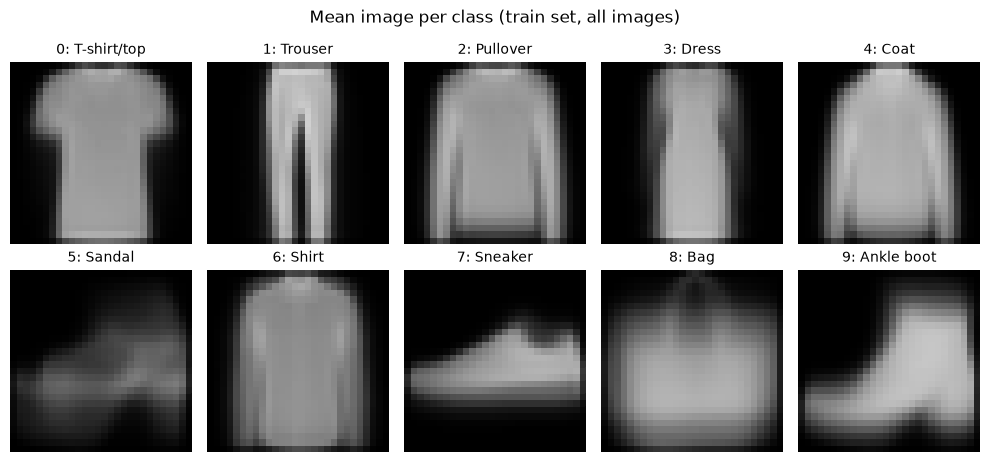

In [229]:
# 7-1. 학습 이미지 전체를 numpy 배열로 꺼내기
#  - data 속성: 데이터셋에 저장된 이미지 ('5. 클래스별 샘플 이미지 확인'에서 사용한 것과 같음)
#  - 배열의 크기(shape)와 자료형(dtype)은 아래 출력으로 확인합니다.
train_images = train_dataset.data.numpy()
print(f"학습 이미지 배열 shape : {train_images.shape}")   # (이미지 수, 높이, 너비)
print(f"학습 이미지 배열 dtype : {train_images.dtype}")

# 7-2. 클래스별 평균 이미지 계산
#  - train_labels == class_idx : 해당 클래스의 이미지 위치만 True로 표시
#  - train_images[...]         : 해당 클래스의 이미지만 골라내기
#  - .mean(axis=0)             : 골라낸 이미지들을 겹쳐서, 같은 픽셀 위치끼리 평균 → 이미지 1장
#  - np.stack                  : 클래스별 평균 이미지 10장을 하나의 배열로 묶기
mean_images = np.stack([
    train_images[train_labels == class_idx].mean(axis=0)
    for class_idx in range(num_classes)
])
print(f"평균 이미지 배열 shape : {mean_images.shape}")   # (클래스 수, 높이, 너비)

# 7-3. 평균 이미지 10장을 2줄 x 5칸으로 그리기
#  - '5. 클래스별 샘플 이미지 확인'과 같은 기준으로 비교하기 위해 표시 범위를 0~255로 고정합니다.
fig, axes = plt.subplots(2, 5, figsize=(10, 4.8))

for class_idx, ax in enumerate(axes.flat):   # axes.flat: 2x5 칸을 왼쪽 위부터 차례대로 하나씩 꺼냄
    ax.imshow(mean_images[class_idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{class_idx}: {class_names[class_idx]}", fontsize=10)

    # 눈금과 테두리 제거 (이미지만 보이도록)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Mean image per class (train set, all images)", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
- 출력된 배열 크기
  - 학습 이미지 배열은 (60000, 28, 28), 자료형은 uint8입니다. 학습 이미지 60,000장이 모두 28×28 크기이고, 0~255 정수 형식으로 저장되어 있습니다.
  - 평균 이미지 배열은 (10, 28, 28)로, 클래스마다 28×28 평균 이미지가 1장씩 만들어졌습니다.
- 클래스마다 평균 이미지가 또렷한 모양으로 나오는가, 흐리게 퍼지는가?
  - T-shirt/top, Trouser, Pullover, Dress, Coat, Sneaker, Ankle boot는 평균 이미지만 보고도 어떤 물건인지 알아볼 수 있을 만큼 윤곽이 분명합니다.
    - 특히 Trouser는 두 다리 사이의 빈 공간까지 뚜렷하게 보입니다.
  - 나머지 세 클래스는 상대적으로 흐립니다.
    - Sandal: 10개 중 가장 어둡고, 윤곽이 넓게 퍼져 있습니다.
    - Bag: 아래쪽 사각형 몸통은 보이지만 위쪽은 흐리게 퍼져 있어, 손잡이 모양이 뚜렷하지 않습니다.
    - Shirt: 긴팔 상의 모양은 보이지만, Pullover, Coat보다 조금 어둡고 소매 경계가 덜 또렷합니다.
- '5. 클래스별 샘플 이미지 확인'에서 윤곽이 비슷하다고 본 클래스는 평균 이미지에서도 비슷한가?
  - Pullover, Coat, Shirt: 셋 모두 몸통 양옆으로 긴 소매가 아래까지 내려오는, 서로 비슷한 윤곽입니다.
  - Shirt와 T-shirt/top: T-shirt/top은 반팔, Shirt는 긴팔 윤곽으로 나와 서로 다르게 보입니다.
  - Coat와 Dress: Coat는 긴 소매가 있는 넓은 윤곽, Dress는 소매 부분이 흐리게만 보이는 좁고 긴 윤곽으로 서로 다르게 보입니다.
- '5. 클래스별 샘플 이미지 확인'에서 본 신발의 방향(앞코가 왼쪽)이 평균 이미지에서도 유지되는가?
  - Sneaker와 Ankle boot는 앞부분이 왼쪽, 발목·뒤꿈치 쪽이 오른쪽에 있는 모양으로 나옵니다.
  - Sandal은 흐려서 확실하지 않지만, 밝은 부분이 오른쪽으로 높게 올라가 있어 다른 신발과 같은 방향으로 보입니다.

### 해석
- 학습/테스트 이미지 전체의 크기와 형식 점검은 '6. 이상치 확인'에서 다룹니다. 이 섹션의 배열 크기 출력은 평균 이미지 계산에 사용한 배열을 확인하는 용도입니다.
- Pullover, Coat, Shirt는 데이터 전체 기준으로도 윤곽이 비슷합니다. 샘플 5장에서 본 관찰이 평균 이미지에서도 같게 나왔습니다.
- Shirt와 T-shirt/top, Coat와 Dress는 평균 이미지에서는 서로 다르게 보입니다. '5. 클래스별 샘플 이미지 확인'에서 비슷하다고 본 사례(Shirt 3번째, Coat 1번째)는 각 클래스의 평균 모양과는 다릅니다.
- 평균 이미지가 흐리다는 것은, 같은 위치에서 밝은 이미지와 어두운 이미지가 섞여 있다는 뜻입니다. Sandal과 Bag이 흐리게 나온 것은 '5. 클래스별 샘플 이미지 확인'에서 Sandal(굽 높이, 밑창)과 Bag(손잡이 유무)의 모양이 제각각이었던 관찰과 같은 방향입니다.
- 신발이 앞코가 왼쪽을 향하는 방향으로 놓여 있다는 점은 Sneaker와 Ankle boot에서 데이터 전체 기준으로도 확인됩니다. Sandal은 평균 이미지가 흐려서 이 결과만으로는 확실하지 않습니다.

## 8. 학습/테스트 밝기 비교

학습/테스트 이미지의 밝기가 비슷한지 클래스별로 비교합니다.

### 목적
- 생성 모델은 학습 데이터만 보고 배우지만, 생성 성능은 테스트 데이터를 기준으로 확인합니다.
- 학습과 테스트 이미지의 밝기가 다르면, 모델이 학습 데이터를 잘 따라 만들어도 테스트와 비교할 때 차이가 생겨 평가 결과가 실제 성능과 다르게 나올 수 있습니다.
- '6. 이상치 확인'에서는 물건의 크기(0이 아닌 픽셀 수)만 학습/테스트를 비교했고, 밝기는 비교하지 않았습니다.
- 이 결과로 테스트 데이터를 평가 기준으로 그대로 써도 되는지 판단합니다.

### 방법
- 이미지마다 물건 부분의 평균 밝기를 계산합니다.
  - 물건 부분은 '6. 이상치 확인'과 같이 0(검은색)이 아닌 픽셀로 봅니다.
  - 검은 배경까지 포함해 평균을 내면 물건이 작은 이미지가 어둡게 나와 크기와 밝기가 섞이므로, 물건 부분만 평균을 냅니다.
  - 배경 픽셀은 0이라 합에 영향을 주지 않으므로, 이미지 전체 픽셀 값의 합을 0이 아닌 픽셀 수로 나누면 물건 부분의 평균 밝기가 됩니다.
- 표: 클래스별로 학습/테스트의 밝기 중앙값과 그 차이(테스트 − 학습)를 출력합니다.
  - 평균 대신 중앙값을 쓰는 이유: 동떨어진 값의 영향을 덜 받습니다.
- 그림: 클래스마다 밝기 분포를 학습/테스트 겹쳐 그립니다(2줄 × 5칸, 칸마다 한 클래스).
  - 가로축은 밝기(0~255)를 8 단위 구간으로 나눈 것이고, 세로축은 그 클래스 이미지 중 해당 밝기 구간에 속하는 이미지의 비율(%)입니다.
  - 학습은 클래스당 6,000장, 테스트는 클래스당 1,000장으로 개수가 달라서, 개수 대신 비율로 맞춰 비교합니다.
  - 학습은 색칠한 면(파랑), 테스트는 선(주황)으로 그립니다. 두 모양이 겹칠수록 학습과 테스트의 밝기 분포가 비슷하다는 뜻입니다.
  - 10칸 모두 같은 밝기 구간과 가로축 범위를 사용합니다.
- 통계 검정은 하지 않고, 숫자와 그림으로 비교합니다.

### 확인할 점
- 학습과 테스트의 밝기 분포가 클래스마다 비슷한가?
- 같은 클래스 안에서 밝기가 얼마나 다양한가?

No  Class          Train    Test    Diff
----------------------------------------
 0  T-shirt/top    148.3   149.7    +1.4
 1  Trouser        170.0   168.9    -1.1
 2  Pullover       159.5   154.0    -5.5
 3  Dress          162.9   163.8    +0.9
 4  Coat           175.1   174.2    -0.9
 5  Sandal         104.5   103.7    -0.8
 6  Shirt          138.6   137.6    -1.0
 7  Sneaker        127.1   127.2    +0.1
 8  Bag            159.1   159.4    +0.3
 9  Ankle boot     162.2   162.4    +0.2
----------------------------------------
    All            150.7   149.7    -1.0


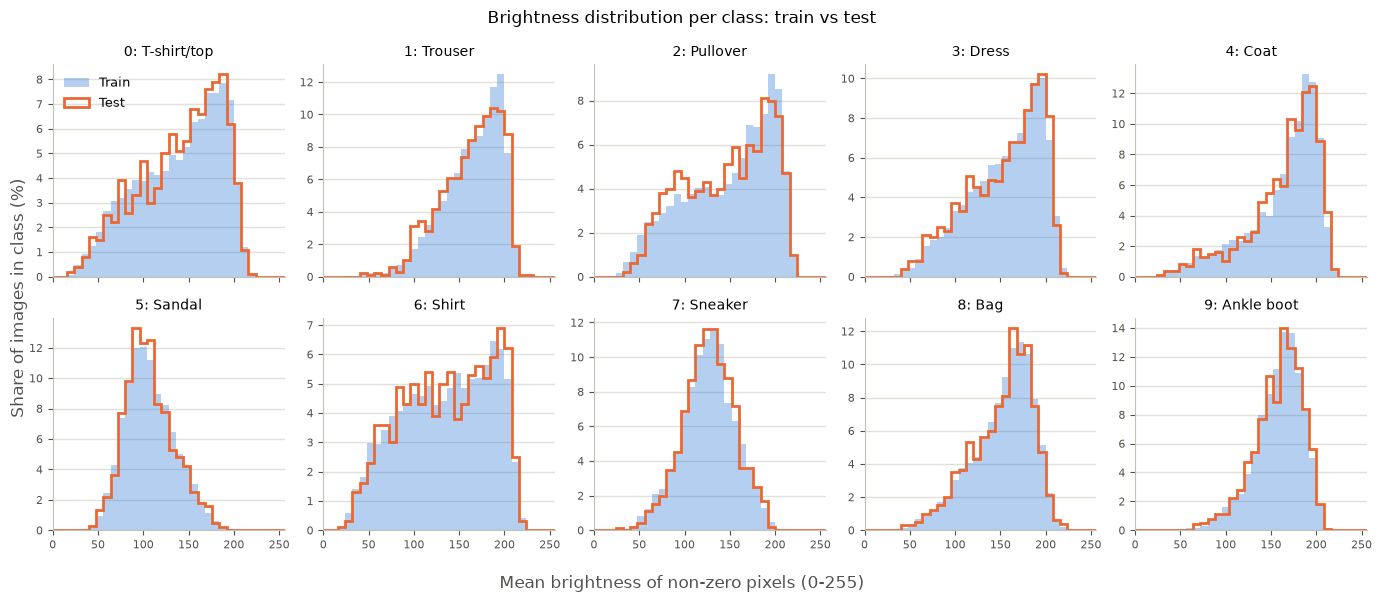

In [230]:
# 8-1. 이미지마다 물건 부분(0이 아닌 픽셀)의 평균 밝기 계산
#  - train_images, test_images     : '6. 이상치 확인'에서 만든 이미지 배열 (이미지 수, 28, 28)
#  - train_nonzero, test_nonzero   : '6. 이상치 확인'에서 센 이미지마다의 0이 아닌 픽셀 수
#  - images.sum(axis=(1, 2))       : 이미지 한 장의 픽셀 값을 모두 더함 (배경은 0이라 더해도 그대로)
#  - ÷ 0이 아닌 픽셀 수            : 물건 부분 픽셀 값의 평균 = 물건 부분의 평균 밝기 (0~255)
#  - '6. 이상치 확인'에서 빈 이미지가 0장이었으므로 0으로 나누는 경우는 없습니다.
train_brightness = train_images.sum(axis=(1, 2)) / train_nonzero
test_brightness = test_images.sum(axis=(1, 2)) / test_nonzero

# 8-2. 표로 출력: 클래스별 밝기 중앙값 (학습, 테스트, 차이 = 테스트 - 학습)
#  - 중앙값을 표에 보이는 자릿수(소수 첫째 자리)로 먼저 반올림한 뒤 차이를 계산합니다.
#    → 표에 보이는 두 값을 직접 빼면 Diff와 같은 값이 나옵니다.
print(f"{'No':>2}  {'Class':<12} {'Train':>7} {'Test':>7} {'Diff':>7}")
print("-" * 40)
for i, name in enumerate(class_names):
    train_median = round(float(np.median(train_brightness[train_labels == i])), 1)
    test_median = round(float(np.median(test_brightness[test_labels == i])), 1)
    print(f"{i:>2}  {name:<12} {train_median:>7.1f} {test_median:>7.1f} {test_median - train_median:>+7.1f}")
print("-" * 40)
train_all = round(float(np.median(train_brightness)), 1)
test_all = round(float(np.median(test_brightness)), 1)
print(f"{'':>2}  {'All':<12} {train_all:>7.1f} {test_all:>7.1f} {test_all - train_all:>+7.1f}")

# 8-3. 그림: 클래스마다 밝기 분포를 학습/테스트 겹쳐 그리기 (2줄 x 5칸, 칸마다 한 클래스)
#  - 가로축: 밝기(0~255)를 8 단위 구간으로 나눔 → 10칸 모두 같은 구간 사용
#  - 세로축: 그 클래스 이미지 중 해당 밝기 구간에 속하는 이미지의 비율(%)
#    (학습은 클래스당 6,000장, 테스트는 1,000장으로 개수가 달라서 비율로 맞춤)
#  - 학습: 색칠한 면(파랑), 테스트: 선(주황) → 두 모양이 겹칠수록 분포가 비슷함
BINS = np.arange(0, 256 + 8, 8)   # 구간 경계: 0, 8, 16, ..., 256 → 구간 32개

fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True)

for class_idx, ax in enumerate(axes.flat):   # axes.flat: 2x5 칸을 왼쪽 위부터 차례대로 하나씩 꺼냄
    train_vals = train_brightness[train_labels == class_idx]
    test_vals = test_brightness[test_labels == class_idx]

    # weights: 이미지 한 장마다 (100 / 이미지 수)를 더함 → 막대 높이가 개수가 아니라 비율(%)이 됨
    ax.hist(train_vals, bins=BINS, weights=np.full(len(train_vals), 100 / len(train_vals)),
            histtype="stepfilled", color="#2a78d6", alpha=0.35, label="Train")   # 학습: 색칠한 면
    ax.hist(test_vals, bins=BINS, weights=np.full(len(test_vals), 100 / len(test_vals)),
            histtype="step", color="#eb6834", linewidth=2, label="Test")         # 테스트: 선

    ax.set_title(f"{class_idx}: {class_names[class_idx]}", fontsize=10)
    ax.set_xlim(0, 256)                               # 밝기 전체 범위 (마지막 구간 248~256까지 보이도록)
    ax.grid(axis="y", color="#e1e0d9", linewidth=1)   # 옅은 가로 보조선
    ax.set_axisbelow(True)                            # 보조선을 그래프 뒤로 보내기
    for side in ["top", "right"]:                     # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8)

axes.flat[0].legend(frameon=False, fontsize=9)   # 범례는 첫 번째 칸에만 한 번 표시
fig.supxlabel("Mean brightness of non-zero pixels (0-255)", color="#52514e")
fig.supylabel("Share of images in class (%)", color="#52514e")
fig.suptitle("Brightness distribution per class: train vs test", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
- 학습과 테스트의 밝기 분포가 클래스마다 비슷한가?
  - 표에서 클래스별 밝기 중앙값의 차이(테스트 − 학습)는 Pullover(−5.5)를 빼면 모두 −1.1 ~ +1.4 사이입니다.
  - 전체 중앙값은 학습 150.7, 테스트 149.7로 1.0 차이입니다.
  - 그림에서도 10개 클래스 모두 학습(면)과 테스트(선)의 모양이 대부분 겹칩니다.
  - 차이가 가장 큰 Pullover도 두 모양의 전체적인 형태는 비슷하고, 테스트 쪽이 어두운 구간(약 80~110)에 조금 더 많습니다.
  - 테스트 선이 학습보다 들쭉날쭉한 것은, 테스트 이미지 수(클래스당 1,000장)가 학습(클래스당 6,000장)보다 적기 때문으로 보입니다.
- 같은 클래스 안에서 밝기가 얼마나 다양한가?
  - 클래스마다 밝기 중앙값이 다릅니다. 학습 기준으로 Sandal(104.5)이 가장 어둡고, Coat(175.1)가 가장 밝습니다.
  - Shirt, T-shirt/top, Pullover는 가장 높은 막대가 약 7~9%로 낮고 넓게 퍼져 있어, 같은 클래스 안에서 밝기가 다양합니다.
  - Coat, Sandal, Ankle boot는 가장 높은 막대가 약 13~14%로, 밝기가 상대적으로 한 곳에 모여 있습니다.
  - 대부분의 클래스에서 어두운 쪽으로 길게 이어진 꼬리가 있어, 같은 클래스 안에 어두운 이미지가 섞여 있습니다. '5. 클래스별 샘플 이미지 확인'에서 같은 줄의 다른 이미지보다 어두운 이미지가 있었던 관찰과 같은 방향입니다.

### 해석
- 물건 부분의 밝기 기준으로, 학습과 테스트는 클래스마다 비슷하게 분포합니다.
- '6. 이상치 확인'의 크기(0이 아닌 픽셀 수) 비교 결과와 함께 보면, 테스트 데이터를 생성 결과 평가의 기준으로 그대로 사용해도 된다고 판단합니다.
- Pullover의 중앙값 차이(−5.5)는 다른 클래스보다 크지만, 밝기 범위(0~255)의 약 2% 정도이고 분포 모양도 비슷합니다. 다만 평가 단계에서 Pullover 결과를 볼 때는 이 차이를 함께 고려합니다.
- Shirt, T-shirt/top, Pullover처럼 클래스 안에서 밝기가 다양한 클래스는, 생성 결과의 밝기도 한쪽으로 몰리지 않고 다양하게 나오는지 볼 필요가 있습니다.

### 한계
- 통계 검정 없이 숫자와 그림으로 비교했기 때문에, 차이가 의미 있는 수준인지는 수치로 판단하지 않았습니다.
- 0이 아닌 픽셀을 모두 물건으로 봤기 때문에, 아주 흐린 픽셀이 섞인 이미지는 물건의 밝기가 실제보다 조금 낮게 계산될 수 있습니다.
- 이미지마다 밝기를 평균 하나로 줄여서 봤기 때문에, 무늬처럼 이미지 안에서 밝기가 어떻게 배치되는지는 반영되지 않습니다.

## 9. EDA 정리

지금까지의 EDA에서 확인한 내용과, 이를 바탕으로 정한 사항을 정리합니다.

### 확인한 내용
- 데이터 구성 ('3. 데이터셋 로드 결과 확인', '6. 이상치 확인')
  - 학습 데이터 60,000장, 테스트 데이터 10,000장입니다.
  - 학습/테스트 이미지 모두 28×28 크기의 흑백 이미지이고, uint8(0~255) 형식으로 저장되어 있습니다.
- 라벨 ('4. 클래스(옷 종류)별 이미지 개수 확인', '5. 클래스별 샘플 이미지 확인')
  - `targets` 값은 이미지마다 하나씩 있고 0~9 범위 안에 있으며, 샘플 이미지로 확인한 범위에서 실제 이미지의 클래스와 맞습니다.
  - 학습은 클래스마다 6,000장, 테스트는 클래스마다 1,000장으로, 모든 클래스의 개수가 같습니다.
- 생김새 ('5. 클래스별 샘플 이미지 확인', '7. 클래스별 평균 이미지 확인')
  - 대부분의 이미지는 검은 배경 위에 물건 하나가 가운데에 크게 놓여 있습니다. 옷과 Bag은 앞에서 본 모습, 신발은 옆에서 본 모습입니다.
  - Pullover, Coat, Shirt는 평균 이미지에서도 윤곽이 서로 비슷합니다.
  - Sneaker와 Ankle boot는 샘플과 평균 이미지 모두에서 앞코가 왼쪽을 향합니다.
  - Sandal, Bag, Shirt는 평균 이미지가 상대적으로 흐립니다. Sandal과 Bag은 샘플에서도 모양이 제각각이었습니다.
  - Shirt·T-shirt/top·Dress, Sneaker·Ankle boot처럼 클래스 사이의 경계가 애매한 이미지가 섞여 있습니다.
- 이상치 ('6. 이상치 확인')
  - 완전히 빈 이미지는 학습/테스트 모두 없습니다.
  - 0이 아닌 픽셀 수가 가장 적은/많은 이미지 중에는 거의 빈 이미지, 사람이 입고 있는 모습, 클래스 이름과 다른 물건처럼 보이는 이미지, 배경이 완전히 검지 않은 이미지가 일부 있습니다.
  - 잡음으로만 이루어진 이미지는 보이지 않았습니다.
  - 0이 아닌 픽셀 수 기준으로, 학습과 테스트의 분포는 클래스마다 비슷합니다.
- 밝기 ('8. 학습/테스트 밝기 비교')
  - 물건 부분의 평균 밝기 중앙값은 학습 150.7, 테스트 149.7입니다. 클래스별 차이는 Pullover(−5.5)를 빼면 모두 −1.1 ~ +1.4 사이이고, 분포 모양도 대부분 겹칩니다.
  - Shirt, T-shirt/top, Pullover는 같은 클래스 안에서 밝기가 넓게 퍼져 있습니다.

### 결정 사항
- 크기 조정은 하지 않습니다. 모든 이미지가 이미 28×28로 같습니다.
- 클래스 불균형 처리는 하지 않습니다. 모든 클래스의 개수가 같습니다.
- `targets` 값을 각 이미지의 클래스 번호로 사용합니다.
- 이상치 후보는 기록만 하고 데이터에서 빼지 않습니다. 빈 이미지나 잡음으로만 이루어진 이미지처럼 뚜렷한 이상치가 없었습니다.
- 테스트 데이터를 생성 결과 평가의 기준으로 그대로 사용합니다. 크기(0이 아닌 픽셀 수)와 밝기 모두 학습 데이터와 분포가 비슷합니다.

### 이후 단계에서 볼 점
- 생성 결과를 평가할 때
  - Pullover, Coat, Shirt처럼 서로 비슷한 클래스가 구분되게 생성되는지 확인합니다.
  - Sandal, Bag처럼 클래스 안의 모양이 다양한 클래스에서, 한 가지 모양만 반복해서 생성하지 않는지 확인합니다.
  - Shirt, T-shirt/top, Pullover처럼 클래스 안의 밝기가 다양한 클래스에서, 생성 결과의 밝기가 한쪽으로 몰리지 않는지 확인합니다.
  - Pullover는 학습/테스트의 밝기 중앙값 차이(−5.5)가 다른 클래스보다 크다는 점을 함께 고려합니다.
- 데이터 증강을 사용하는 경우
  - 신발의 앞코가 왼쪽을 향하고 있으므로, 좌우 반전은 데이터에 거의 없는 방향의 신발을 만들 수 있습니다.
  - 물건이 화면을 크게 차지하는 이미지가 많아, 자르기나 이동은 물건의 일부를 잘라낼 수 있습니다.

### 한계
- 이상치는 클래스마다 0이 아닌 픽셀 수가 가장 적은/많은 이미지를 학습/테스트 각각 3장씩만 눈으로 확인했습니다.
- 모양은 정상이지만 라벨이 틀린 이미지는 이번에 사용한 방법으로는 찾기 어렵습니다.
- 중복 이미지는 확인하지 않았습니다.
- 학습/테스트 비교(크기, 밝기)는 통계 검정 없이 숫자와 그림으로 판단했습니다.
- 샘플 이미지, 평균 이미지, 이상치에 대한 관찰은 눈으로 판단한 것이라 사람마다 다르게 볼 수 있습니다.

## 10. 전처리 방향

지금부터는 미션의 cGAN 학습을 위한 전처리를 진행합니다. EDA 결과를 바탕으로, 이 데이터에서 할 전처리와 하지 않을 전처리를 먼저 정리합니다.

### 하는 것
- 픽셀 값 변환: 0~255 정수를 -1~1 실수로 바꿉니다. ('11. 전처리: 픽셀 값 변환')
- 배치 구성: 학습 데이터를 일정 개수씩 섞어서 꺼내는 DataLoader를 만듭니다. ('12. 전처리: DataLoader 구성')

### 하지 않는 것
| 항목 | 하지 않는 이유 | 근거 |
| --- | --- | --- |
| 크기 조정 | 학습/테스트 이미지가 모두 이미 28×28로 같습니다. | '6. 이상치 확인' |
| 클래스 불균형 처리 | 모든 클래스의 이미지 수가 같습니다(학습 6,000장, 테스트 1,000장). | '4. 클래스(옷 종류)별 이미지 개수 확인' |
| 이상치 제거 | 빈 이미지나 잡음으로만 이루어진 이미지처럼 뚜렷한 이상치가 없어, 후보는 기록만 하기로 했습니다. | '6. 이상치 확인' |
| 좌우 반전 증강 | Sneaker와 Ankle boot의 앞코가 왼쪽을 향하고 있어, 뒤집으면 데이터에 거의 없는 방향의 신발이 생깁니다. | '9. EDA 정리' |
| 자르기·이동 증강 | 물건이 화면을 크게 차지하는 이미지가 많아, 물건의 일부가 잘릴 수 있습니다. | '9. EDA 정리' |
| 검증용 데이터 분리 | GAN은 정답을 맞히는 모델이 아니므로 검증용 데이터를 따로 떼지 않고, 평가는 테스트 데이터로 합니다. | '8. 학습/테스트 밝기 비교' |

- 회전과 밝기 조절 증강은 EDA에서 따로 확인하지 않았습니다. 우선 증강 없이 학습하고, 필요하면 이후에 실험합니다.
- 참고로 DCGAN 논문(Radford et al., 2015)도 학습 이미지를 Tanh 함수의 출력 범위인 [-1, 1]로 맞추는 것 외에는 전처리를 하지 않았습니다.

## 11. 전처리: 픽셀 값 변환

픽셀 값을 0~255 정수에서 -1~1 실수로 바꾼 학습/테스트 데이터셋을 만듭니다.

### 목적
- 왜 -1~1로 바꾸는가?
  - cGAN은 Generator가 가짜 이미지를 만들고, Discriminator가 진짜 이미지와 가짜 이미지를 구별하면서 함께 학습합니다.
  - Generator의 마지막 층에는 보통 Tanh 함수를 사용합니다. Tanh는 출력 값을 항상 -1~1 사이로 만들기 때문에, Generator가 만든 가짜 이미지는 -1~1 범위로 설계합니다.
  - 진짜 이미지가 다른 범위(예: 0~255나 0~1)라면, Discriminator는 옷 모양을 보지 않고 값의 범위만으로 진짜와 가짜를 쉽게 구별할 수 있습니다. 그러면 Generator가 옷 모양을 제대로 배우지 못합니다.
  - 그래서 진짜 이미지도 가짜 이미지와 같은 -1~1 범위로 맞춥니다.
- 왜 이 공식인가?
  - 0~255를 255로 나누면 0~1이 되고, 여기서 0.5를 빼고 0.5로 나누면 -1~1이 됩니다. 즉 (x / 255 − 0.5) / 0.5입니다.
  - 검은 배경(0)은 -1, 중간 밝기(127.5)는 0, 가장 밝은 값(255)은 1이 됩니다.
  - 여기서 0.5는 데이터의 실제 평균이나 표준편차가 아니라, 0~1 범위를 -1~1로 옮기기 위해 정한 값입니다.
- 왜 테스트 데이터도 바꾸는가?
  - 이후 생성 이미지를 테스트 이미지와 비교해 평가할 때, 두 이미지의 값 범위가 같아야 하기 때문입니다.

### 방법
- torchvision의 `transforms.v2`로 세 단계를 차례로 적용합니다.
  - `v2.ToImage()`: 이미지를 텐서로 바꿉니다. 값은 0~255 정수 그대로이고, 모양은 (1, 28, 28)입니다.
  - `v2.ToDtype(torch.float32, scale=True)`: 실수로 바꾸면서 255로 나눠 0~1로 만듭니다.
  - `v2.Normalize(mean=[0.5], std=[0.5])`: (x − 0.5) / 0.5를 계산해 -1~1로 만듭니다.
- `transforms.v2`를 쓰는 이유: torchvision 공식 문서가 새 코드에는 v2 사용을 권장하고, v2에서는 `ToTensor` 대신 `ToImage`와 `ToDtype`을 쓰도록 안내합니다.
- EDA에서 사용한 데이터셋(`ToTensor()`만 적용, 0~1)은 그대로 두고, 위 변환을 적용한 학습/테스트 데이터셋을 새로 만듭니다. 같은 `data/raw/` 폴더를 사용합니다.
- 변환이 맞게 되었는지 세 가지로 확인합니다.
  - 학습 데이터 한 장을 꺼내 모양, 자료형, 값 범위를 출력합니다.
  - 학습/테스트 앞 1,000장에서, 변환을 거친 값과 원본(0~255)에 공식을 직접 계산한 값이 같은지 비교합니다.
  - 학습/테스트 전체 원본의 최솟값·최댓값에 공식을 적용해, 변환 후 값의 범위를 확인합니다.

### 확인할 점
- 변환 후 이미지의 모양은 (1, 28, 28), 자료형은 float32인가?
- 변환 결과가 공식 (x / 255 − 0.5) / 0.5로 직접 계산한 값과 같은가?
- 학습/테스트 모두 변환 후 값이 -1~1 범위인가?

In [231]:
# 11-1. GAN 학습용 변환 정의 (0~255 정수 → -1~1 실수)
#  - v2.ToImage()                          : 이미지를 텐서로 바꿈 (값은 0~255 정수 그대로, 모양 (1, 28, 28))
#  - v2.ToDtype(torch.float32, scale=True) : 실수로 바꾸면서 255로 나눔 → 0.0~1.0
#  - v2.Normalize(mean=[0.5], std=[0.5])   : (x - 0.5) / 0.5 계산 → -1.0~1.0
gan_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.5], std=[0.5]),
])

# 11-2. 변환을 적용한 학습/테스트 데이터셋 만들기
#  - EDA에서 쓴 train_dataset, test_dataset(ToTensor만 적용, 0~1)은 그대로 두고 새로 만듭니다.
#  - DATA_ROOT는 '2. FashionMNIST 데이터셋 불러오기'에서 정한 경로(../data/raw)입니다.
train_dataset_gan = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=gan_transform,
)
test_dataset_gan = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=gan_transform,
)

# 11-3. 학습 데이터 한 장을 꺼내 모양, 자료형, 값 범위 확인
img, label = train_dataset_gan[0]
print(f"이미지 shape : {tuple(img.shape)}")   # (1, 28, 28) 예상
print(f"이미지 dtype : {img.dtype}")            # torch.float32 예상
print(f"픽셀 값 범위 : [{img.min().item():.3f}, {img.max().item():.3f}]")
print(f"라벨         : {label} ({class_names[label]})")

# 11-4. 변환 결과가 공식 (x / 255 - 0.5) / 0.5 로 직접 계산한 값과 같은지 비교
#  - data 속성: 변환 전 원본 이미지 (0~255 정수, 모양 (이미지 수, 28, 28))
#  - 7만 장 전체를 변환하면 오래 걸리므로, 학습/테스트 각각 앞 1,000장만 비교합니다.
#  - 최대 차이가 0에 매우 가까우면(실수 계산 오차 수준) 같은 값으로 봅니다.
N_CHECK = 1000
print()
for set_name, dataset in [("학습", train_dataset_gan), ("테스트", test_dataset_gan)]:
    transformed = torch.stack([dataset[i][0] for i in range(N_CHECK)])   # 변환을 거친 값 (1000, 1, 28, 28)
    by_formula = (dataset.data[:N_CHECK].float() / 255 - 0.5) / 0.5      # 공식으로 직접 계산한 값 (1000, 28, 28)
    max_diff = (transformed.squeeze(1) - by_formula).abs().max().item()
    print(f"{set_name} 앞 {N_CHECK:,}장 : 변환 결과와 공식의 최대 차이 = {max_diff:.2e}")

# 11-5. 전체 데이터의 변환 후 값 범위 확인
#  - 공식은 값이 클수록 결과도 커지므로, 원본의 최솟값·최댓값에 공식을 적용하면 변환 후의 최솟값·최댓값이 됩니다.
print()
for set_name, dataset in [("학습", train_dataset_gan), ("테스트", test_dataset_gan)]:
    raw_min, raw_max = dataset.data.min().item(), dataset.data.max().item()
    new_min, new_max = (raw_min / 255 - 0.5) / 0.5, (raw_max / 255 - 0.5) / 0.5
    print(f"{set_name} 전체 : 원본 범위 [{raw_min}, {raw_max}] → 변환 후 범위 [{new_min:.1f}, {new_max:.1f}]")

이미지 shape : (1, 28, 28)
이미지 dtype : torch.float32
픽셀 값 범위 : [-1.000, 1.000]
라벨         : 9 (Ankle boot)

학습 앞 1,000장 : 변환 결과와 공식의 최대 차이 = 1.19e-07
테스트 앞 1,000장 : 변환 결과와 공식의 최대 차이 = 1.19e-07

학습 전체 : 원본 범위 [0, 255] → 변환 후 범위 [-1.0, 1.0]
테스트 전체 : 원본 범위 [0, 255] → 변환 후 범위 [-1.0, 1.0]


### 결과
- 변환 후 이미지의 모양은 (1, 28, 28), 자료형은 float32인가?
  - 학습 데이터 첫 번째 이미지(라벨 9, Ankle boot)의 모양은 (1, 28, 28), 자료형은 torch.float32이고, 값 범위는 [-1.000, 1.000]입니다.
- 변환 결과가 공식 (x / 255 − 0.5) / 0.5로 직접 계산한 값과 같은가?
  - 학습/테스트 앞 1,000장 모두, 변환 결과와 공식으로 계산한 값의 최대 차이가 1.19e-07(약 0.0000001)입니다.
- 학습/테스트 모두 변환 후 값이 -1~1 범위인가?
  - 학습/테스트 모두 원본 범위가 [0, 255]이고, 여기에 공식을 적용한 변환 후 범위는 [-1.0, 1.0]입니다.

### 해석
- 최대 차이 1.19e-07은 컴퓨터의 실수(float32) 계산에서 생기는 아주 작은 오차 수준이므로, `gan_transform`은 공식 (x / 255 − 0.5) / 0.5대로 동작한다고 볼 수 있습니다.
- 변환이 공식대로 동작하고, 공식을 적용한 학습/테스트 전체의 범위가 [-1.0, 1.0]이므로, `gan_transform`을 거친 학습/테스트 이미지는 모두 -1~1 범위가 됩니다.
- 검은 배경(0)은 -1, 가장 밝은 값(255)은 1로 바뀌어, Generator 마지막 층의 Tanh 출력과 같은 범위가 됩니다.

## 12. 전처리: DataLoader 구성

'11. 전처리: 픽셀 값 변환'에서 만든 데이터셋을 학습에 넘겨주기 위해, 이미지를 일정 개수씩 묶어서 꺼내는 DataLoader를 만듭니다.

### 목적
- 지금까지 만든 데이터셋은 이미지를 한 장씩만 꺼낼 수 있습니다. 학습에는 아래 세 가지가 필요합니다.
  - 여러 장을 묶어서 넣기(배치): 6만 장을 한 번에 넣으면 메모리가 부족하고, 한 장씩 넣으면 느리며 모델이 한 장에 따라 크게 흔들립니다. 그래서 일정 개수씩 묶어서 넣고, 묶음 단위로 모델을 조금씩 고칩니다.
  - 매번 순서 섞기: 에폭(전체 데이터를 한 바퀴 학습하는 단위)마다 순서를 새로 섞어, 묶음마다 여러 클래스가 섞여 들어가도록 합니다.
  - 전체 데이터를 여러 바퀴 반복하기
- DataLoader는 이 세 가지를 자동으로 처리합니다.
- 한 묶음을 꺼내 보면, 모델이 실제로 받게 될 입력의 모양을 확인할 수 있습니다. 이 모양은 이후 Generator와 Discriminator를 설계하는 기준이 됩니다.

### 방법
| 설정 | 값 | 이유 |
| --- | --- | --- |
| 묶음 크기(`batch_size`) | 128 | DCGAN 논문(Radford et al., 2015)에서 사용한 값으로 시작하고, 학습 단계에서 바꿀 수 있습니다. |
| 섞기(`shuffle`) | 학습: 섞음 / 테스트: 섞지 않음 | 학습은 에폭마다 순서를 바꾸고, 테스트는 평가에만 쓰므로 순서가 상관없습니다. |
| 마지막 작은 묶음 버리기(`drop_last`) | 학습: 버림 / 테스트: 버리지 않음 | 60,000장은 128로 나누어떨어지지 않아 마지막 묶음만 작아집니다. 학습에서는 모든 묶음의 크기를 같게 유지하기 위해 버리고, 테스트는 평가에 모든 이미지를 쓰기 위해 버리지 않습니다. 학습은 에폭마다 섞기 때문에 버려지는 이미지도 에폭마다 달라집니다. |
| 읽기 프로세스 수(`num_workers`) | 0 | Windows의 노트북 환경에서는 0이 아니면 오류가 나거나 시작이 느려질 수 있습니다. 데이터가 작아서 0으로도 충분합니다. |
| 시드(`generator`) | 42 | 셀을 다시 실행해도 같은 순서로 섞이도록 합니다. |

- 아래 내용을 출력해 확인합니다.
  - 학습/테스트의 묶음 수와, 학습에서 버려지는 이미지 수
  - 학습 묶음 하나의 이미지·라벨 모양, 자료형, 값 범위
  - 그 묶음 안에 클래스별로 몇 장씩 들어 있는지
  - DataLoader를 새로 시작해서(새 에폭) 꺼낸 첫 묶음의 라벨 순서가 처음과 다른지

### 확인할 점
- 학습 묶음 수와 버려지는 이미지 수는 몇 개인가?
- 이미지 묶음의 모양은 (128, 1, 28, 28), 라벨 묶음의 모양은 (128,)인가?
- 이미지 값은 -1~1, 라벨 값은 0~9 범위인가?
- 한 묶음 안에 여러 클래스가 섞여 있는가?
- 새 에폭을 시작하면 순서가 새로 섞이는가?

In [232]:
# 12-1. DataLoader 설정값
BATCH_SIZE = 128   # 한 번에 모델에 넣을 이미지 수 (학습 단계에서 바꿀 수 있음)
LOADER_SEED = 42   # 섞는 순서를 고정하기 위한 시드

# 12-2. 학습/테스트 DataLoader 만들기
#  - shuffle=True   : 매 에폭(전체 데이터 한 바퀴)마다 순서를 새로 섞음
#  - drop_last=True : 마지막에 128장이 안 되는 묶음은 버림 (모든 묶음의 크기를 같게 유지)
#  - num_workers=0  : 데이터를 따로 읽는 프로세스 없이 현재 프로세스에서 읽음
#  - generator      : 시드를 고정한 난수 생성기 → 셀을 다시 실행해도 같은 순서로 섞임
loader_generator = torch.Generator().manual_seed(LOADER_SEED)

train_loader = DataLoader(
    train_dataset_gan,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    generator=loader_generator,
)

#  - 테스트 데이터는 평가에만 쓰므로 섞지 않고, 마지막 묶음도 버리지 않습니다.
test_loader = DataLoader(
    test_dataset_gan,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

# 12-3. 묶음 수와 버려지는 이미지 수 확인
#  - len(loader): 한 에폭에 꺼내는 묶음의 수
n_train_used = len(train_loader) * BATCH_SIZE
n_test_last = len(test_dataset_gan) - (len(test_loader) - 1) * BATCH_SIZE
print(f"학습 묶음 수   : {len(train_loader)}개 (사용 {n_train_used:,}장, 버려지는 이미지 {len(train_dataset_gan) - n_train_used}장)")
print(f"테스트 묶음 수 : {len(test_loader)}개 (마지막 묶음 {n_test_last}장)")

# 12-4. 학습 묶음 하나를 꺼내 이미지와 라벨의 모양, 자료형, 값 범위 확인
#  - iter(train_loader): DataLoader에서 묶음을 차례로 꺼내기 시작 (새 에폭 시작)
#  - next(...)         : 그중 첫 번째 묶음을 꺼냄 → (이미지 묶음, 라벨 묶음)
batch_images, batch_labels = next(iter(train_loader))
print(f"\n이미지 묶음 shape : {tuple(batch_images.shape)}")   # (128, 1, 28, 28) 예상
print(f"이미지 묶음 dtype : {batch_images.dtype}")
print(f"픽셀 값 범위      : [{batch_images.min().item():.3f}, {batch_images.max().item():.3f}]")
print(f"라벨 묶음 shape   : {tuple(batch_labels.shape)}")     # (128,) 예상
print(f"라벨 묶음 dtype   : {batch_labels.dtype}")
print(f"라벨 값 범위      : [{batch_labels.min().item()}, {batch_labels.max().item()}]")

# 12-5. 이 묶음 안의 클래스별 이미지 수 (여러 클래스가 섞여 있는지 확인)
#  - torch.bincount: 0, 1, 2, ... 각 번호가 몇 번 나오는지 셈 ('4. 클래스(옷 종류)별 이미지 개수 확인'의 np.bincount와 같은 역할)
batch_counts = torch.bincount(batch_labels, minlength=num_classes)
print("\n묶음 안의 클래스별 이미지 수:")
for i, name in enumerate(class_names):
    print(f"  {i}: {name:<12} {batch_counts[i].item():>3}장")

# 12-6. 새 에폭을 시작하면 순서가 새로 섞이는지 확인
#  - iter(train_loader)를 다시 시작하면(= 새 에폭) 다른 순서로 섞여야 합니다.
#  - 12-4에서 꺼낸 첫 묶음과, 새로 시작해서 꺼낸 첫 묶음의 앞 10개 라벨을 비교합니다.
next_labels = next(iter(train_loader))[1]
print(f"\n첫 번째 에폭의 첫 묶음 앞 10개 라벨 : {batch_labels[:10].tolist()}")
print(f"두 번째 에폭의 첫 묶음 앞 10개 라벨 : {next_labels[:10].tolist()}")

학습 묶음 수   : 468개 (사용 59,904장, 버려지는 이미지 96장)
테스트 묶음 수 : 79개 (마지막 묶음 16장)

이미지 묶음 shape : (128, 1, 28, 28)
이미지 묶음 dtype : torch.float32
픽셀 값 범위      : [-1.000, 1.000]
라벨 묶음 shape   : (128,)
라벨 묶음 dtype   : torch.int64
라벨 값 범위      : [0, 9]

묶음 안의 클래스별 이미지 수:
  0: T-shirt/top   16장
  1: Trouser       15장
  2: Pullover      18장
  3: Dress         14장
  4: Coat          11장
  5: Sandal         5장
  6: Shirt         12장
  7: Sneaker       14장
  8: Bag           14장
  9: Ankle boot     9장

첫 번째 에폭의 첫 묶음 앞 10개 라벨 : [8, 9, 2, 4, 2, 0, 4, 7, 1, 3]
두 번째 에폭의 첫 묶음 앞 10개 라벨 : [0, 8, 3, 0, 1, 1, 3, 2, 4, 9]


### 결과
- 학습 묶음 수와 버려지는 이미지 수는 몇 개인가?
  - 학습은 묶음 468개로 59,904장을 사용하고, 96장이 버려집니다.
  - 테스트는 묶음 79개이고, 마지막 묶음은 16장입니다.
- 이미지 묶음의 모양은 (128, 1, 28, 28), 라벨 묶음의 모양은 (128,)인가?
  - 이미지 묶음은 (128, 1, 28, 28), 라벨 묶음은 (128,)입니다.
- 이미지 값은 -1~1, 라벨 값은 0~9 범위인가?
  - 이미지는 torch.float32이고 값 범위는 [-1.000, 1.000]입니다.
  - 라벨은 torch.int64이고 값 범위는 [0, 9]입니다.
- 한 묶음 안에 여러 클래스가 섞여 있는가?
  - 꺼낸 묶음 128장 안에 10개 클래스가 모두 들어 있습니다. 클래스별로는 Sandal 5장부터 Pullover 18장까지입니다.
- 새 에폭을 시작하면 순서가 새로 섞이는가?
  - 첫 번째 에폭의 첫 묶음 앞 10개 라벨은 [8, 9, 2, 4, 2, 0, 4, 7, 1, 3], 두 번째 에폭은 [0, 8, 3, 0, 1, 1, 3, 2, 4, 9]로 서로 다릅니다.

### 해석
- DataLoader가 설정한 대로 동작합니다. 학습 데이터는 128장씩 묶여, 에폭마다 새로 섞인 순서로 나옵니다.
- 학습에서 버려지는 96장은 전체 60,000장의 약 0.16%이고, 에폭마다 순서가 새로 섞이므로 버려지는 이미지도 에폭마다 달라집니다.
- 묶음에는 여러 클래스가 섞여 들어가지만, 무작위로 섞기만 하므로 묶음마다 클래스별 개수는 같지 않습니다(이번 묶음은 5~18장).
- 모델은 이미지 (128, 1, 28, 28) 실수 묶음과 라벨 (128,) 정수 묶음을 받게 됩니다. 이 모양과 자료형이 이후 Generator와 Discriminator를 설계할 때의 기준이 됩니다.

## 13. 전처리: 되돌려서 눈으로 확인

-1~1로 바뀐 이미지를 다시 0~1로 되돌려 그려서, 전처리 후에도 옷 모양이 그대로인지 눈으로 확인합니다.

### 목적
- '11. 전처리: 픽셀 값 변환'과 '12. 전처리: DataLoader 구성'에서는 숫자(모양, 값 범위, 공식과의 차이)로 전처리를 확인했습니다. 마지막으로 이미지를 직접 보고 확인합니다.
- 원본 이미지와 같은 기준(0~1)으로 비교하기 위해, 그리기 전에 -1~1을 0~1로 되돌립니다.
- 여기서 만드는 되돌리기 함수는 이후 Generator가 만든 이미지(-1~1)를 그릴 때도 그대로 사용합니다.

### 방법
- 되돌리기: (x + 1) / 2를 계산합니다.
  - -1은 0, 0은 0.5, 1은 1이 됩니다.
  - '11. 전처리: 픽셀 값 변환'의 공식 (x / 255 − 0.5) / 0.5를 거꾸로 계산한 것으로, 결과는 원본 픽셀 값을 255로 나눈 값(0~1)과 같아야 합니다.
- 원본과 비교: 학습 데이터에서 클래스마다 첫 번째 이미지를 1장씩 골라, 원본(0~255를 255로 나눈 값)과 되돌린 이미지를 위아래로 나란히 그립니다. 두 값의 최대 차이도 출력합니다.
- 묶음 확인: '12. 전처리: DataLoader 구성'에서 꺼낸 첫 번째 학습 묶음 중 앞 32장을 되돌려 4줄 × 8칸으로 그리고, 각 이미지 위에 라벨의 클래스 이름을 표시합니다.
- 모든 그림의 표시 범위는 0~1로 고정하고, 그래프 안의 글자는 한글이 깨지지 않도록 영어로 표시합니다.

### 확인할 점
- 되돌린 이미지가 원본과 같은가?
- DataLoader 묶음의 이미지가 옷 모양 그대로 보이고, 위에 표시된 클래스 이름과 맞는가?

원본과 되돌린 이미지의 최대 차이: 5.96e-08


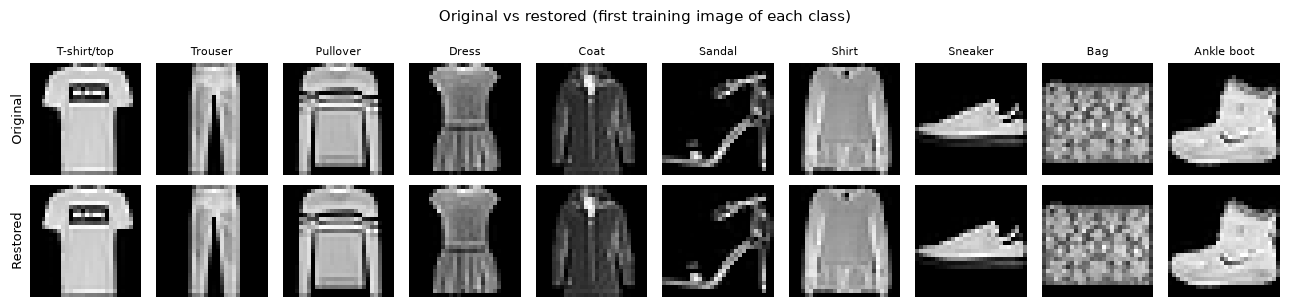

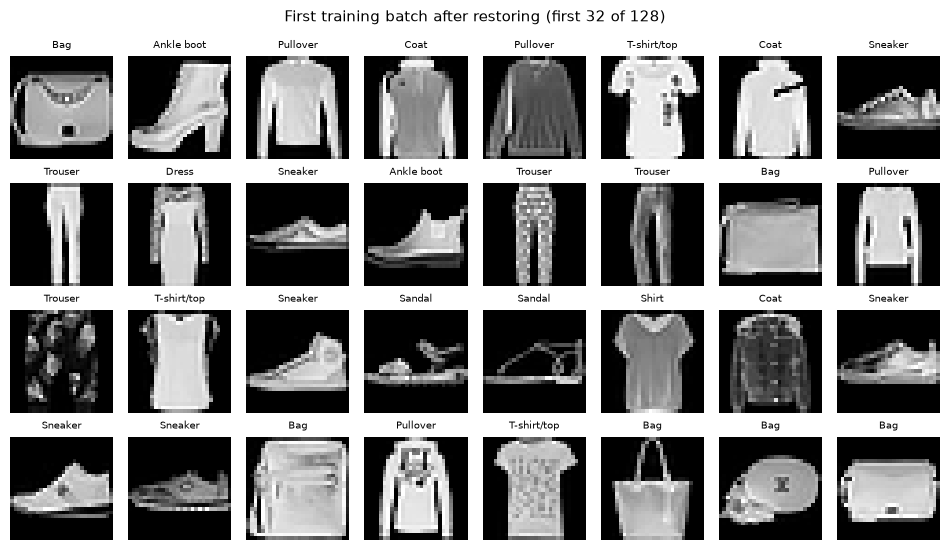

In [233]:
# 13-1. 되돌리기 함수: -1~1 → 0~1
#  - (x + 1) / 2 : -1 → 0, 0 → 0.5, 1 → 1
#  - 이후 생성 이미지(Generator 출력, -1~1)를 그릴 때도 같은 함수를 사용합니다.
def denormalize(x):
    """-1~1 범위의 이미지 텐서를 0~1 범위로 되돌립니다."""
    return (x + 1) / 2


# 13-2. 원본과 되돌린 이미지 비교 (클래스마다 첫 번째 이미지 1장씩)
#  - 원본          : data 속성(0~255 정수) ÷ 255 → 0~1
#  - 되돌린 이미지 : train_dataset_gan에서 꺼낸 -1~1 이미지 → denormalize → 0~1
#  - 최대 차이가 0에 매우 가까우면, 전처리와 되돌리기가 서로 정확히 반대 계산이라는 뜻입니다.
gan_train_labels = train_dataset_gan.targets.numpy()
first_idx = [int(np.where(gan_train_labels == c)[0][0]) for c in range(num_classes)]   # 클래스마다 첫 번째 이미지 위치

original = train_dataset_gan.data[first_idx].float() / 255                                    # (10, 28, 28), 0~1
restored = torch.stack([denormalize(train_dataset_gan[i][0]) for i in first_idx]).squeeze(1)   # (10, 28, 28), 0~1
print(f"원본과 되돌린 이미지의 최대 차이: {(original - restored).abs().max().item():.2e}")

fig, axes = plt.subplots(2, num_classes, figsize=(num_classes * 1.3, 3.2))
for col in range(num_classes):
    for row, imgs in enumerate([original, restored]):
        ax = axes[row, col]
        ax.imshow(imgs[col].numpy(), cmap="gray", vmin=0, vmax=1)   # 표시 범위 0~1로 고정
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[0, col].set_title(class_names[col], fontsize=8)
axes[0, 0].set_ylabel("Original", fontsize=9)
axes[1, 0].set_ylabel("Restored", fontsize=9)
fig.suptitle("Original vs restored (first training image of each class)", fontsize=11)
plt.tight_layout()
plt.show()

# 13-3. DataLoader 묶음 이미지를 되돌려서 그리기 (앞 32장, 4줄 x 8칸)
#  - batch_images, batch_labels: '12. 전처리: DataLoader 구성'의 12-4에서 꺼낸 첫 번째 학습 묶음
N_ROWS, N_COLS = 4, 8
fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(N_COLS * 1.2, N_ROWS * 1.4))
for k, ax in enumerate(axes.flat):   # axes.flat: 4x8 칸을 왼쪽 위부터 차례대로 하나씩 꺼냄
    ax.imshow(denormalize(batch_images[k, 0]).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[batch_labels[k].item()], fontsize=7)   # 이 이미지의 라벨 (클래스 이름)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle(f"First training batch after restoring (first {N_ROWS * N_COLS} of {BATCH_SIZE})", fontsize=11)
plt.tight_layout()
plt.show()

### 결과
아래에서 'n번째 줄 m번째 칸'은 두 번째 그림(묶음 32장)에서 위에서부터, 왼쪽부터 센 순서입니다.

- 되돌린 이미지가 원본과 같은가?
  - 클래스마다 첫 번째 학습 이미지 10장에서, 원본과 되돌린 이미지의 최대 차이는 5.96e-08(약 0.00000006)입니다.
  - 첫 번째 그림에서도 10개 클래스 모두 위(원본)와 아래(되돌린 이미지)가 같은 모습으로 보입니다.
- DataLoader 묶음의 이미지가 옷 모양 그대로 보이고, 위에 표시된 클래스 이름과 맞는가?
  - 첫 번째 학습 묶음의 앞 32장 모두, 원본 데이터와 같이 검은 배경 위에 물건 하나가 놓인 형태로 보입니다.
  - 대부분의 이미지는 위에 표시된 클래스 이름에 맞는 물건으로 보입니다.
  - 3번째 줄 6번째 칸(Shirt)은 반팔이라 T-shirt/top과 비슷해 보이고, 3번째 줄 1번째 칸(Trouser)은 어둡고 무늬가 많아 모양을 알아보기 어렵습니다.

### 해석
- 최대 차이 5.96e-08은 실수 계산 오차 수준이므로, `denormalize`는 '11. 전처리: 픽셀 값 변환'의 변환을 정확히 거꾸로 계산합니다. 이후 Generator가 만든 이미지도 이 함수로 되돌려 원본과 같은 기준(0~1)으로 볼 수 있습니다.
- 값 변환과 묶음 구성을 거친 뒤에도 이미지의 모양은 그대로이고, 이미지와 라벨이 짝이 맞게 묶여 나옵니다.
- 반팔 Shirt처럼 다른 클래스와 비슷해 보이는 이미지는 '5. 클래스별 샘플 이미지 확인'과 '6. 이상치 확인'에서도 관찰된 것으로, 전처리 때문에 생긴 것이 아니라 원본 데이터의 특징입니다.
- 이것으로 전처리를 마칩니다. 모델에는 -1~1 범위의 이미지 묶음 (128, 1, 28, 28)과 정수 라벨 묶음 (128,)이 들어갑니다.

## 14. 모델 설계: Generator

노이즈와 클래스 번호를 받아, 그 클래스의 28×28 흑백 이미지를 만드는 Generator를 정의합니다.

### 목적
- Generator는 cGAN에서 가짜 이미지를 만드는 모델입니다. 학습이 끝나면 클래스 번호를 지정해서 원하는 옷 이미지를 만드는 데 씁니다.
- 입력이 두 가지인 이유
  - 노이즈(무작위 숫자 100개): 같은 클래스라도 노이즈가 달라지면 다른 모양의 이미지가 나오게 해서, 다양한 이미지를 만들기 위해 넣습니다.
  - 클래스 번호(0~9): 어떤 클래스의 이미지를 만들지 정하는 조건입니다.
- 출력은 '11. 전처리: 픽셀 값 변환'에서 맞춘 진짜 이미지와 같은 모양(1, 28, 28)과 같은 범위(-1~1)여야 합니다.

### 방법
| 단계 | 하는 일 | 출력 모양 |
| --- | --- | --- |
| 1. 라벨 임베딩 | 클래스 번호를 길이 50의 숫자 묶음으로 바꿉니다. 이 숫자들은 학습하면서 함께 정해집니다. | (50,) |
| 2. 이어 붙이기 | 노이즈 100개와 라벨 숫자 50개를 하나로 붙입니다. | (150,) |
| 3. 완전연결층 | 150개 숫자를 128×7×7개로 늘린 뒤, 7×7 크기의 특징 지도 128장으로 모양을 바꿉니다. | (128, 7, 7) |
| 4. 전치 합성곱 1 | 특징 지도의 크기를 두 배로 키웁니다. | (64, 14, 14) |
| 5. 전치 합성곱 2 + Tanh | 크기를 다시 두 배로 키워 흑백 한 장으로 만들고, Tanh로 값을 -1~1로 맞춥니다. | (1, 28, 28) |

- 용어
  - 전치 합성곱(`ConvTranspose2d`): 합성곱과 반대로, 특징 지도의 크기를 키우는 층입니다.
  - BatchNorm: 층을 지날 때마다 값의 분포를 일정하게 맞춰 학습을 안정시키는 층입니다.
  - ReLU: 음수는 0으로, 양수는 그대로 내보내는 함수입니다.
- DCGAN 논문(Radford et al., 2015)의 설계 지침을 따릅니다.
  - 크기를 키울 때 풀링 대신 stride가 있는 전치 합성곱을 사용합니다.
  - 중간 층에는 BatchNorm과 ReLU를 쓰고, 출력층에는 BatchNorm 없이 Tanh를 씁니다.
- 가중치 초기화: DCGAN 논문과 같이 합성곱·완전연결층의 가중치를 평균 0, 표준편차 0.02인 정규분포로 정합니다. BatchNorm의 가중치는 1 근처(표준편차 0.02)로 둡니다. 0 근처로 두면 BatchNorm을 지난 값이 거의 0이 되어 신호가 사라지기 때문입니다. 라벨 임베딩은 PyTorch 기본값을 그대로 둡니다. 이 초기화 함수는 '15. 모델 설계: Discriminator'에서도 같이 사용합니다.
- 확인: 노이즈 8개와 클래스 번호 8개(0~7)를 넣어 출력 모양과 값 범위를 확인하고, 학습할 숫자(파라미터)의 개수를 출력합니다. 아직 학습 전이므로 출력 이미지는 의미 없는 모양입니다.
- 확인용 모델의 가중치와 노이즈는 시드 42로 고정해, 다시 실행해도 같은 값이 나오게 합니다. 학습에 쓰는 모델은 '16. 학습 설정'에서 시드를 다시 정하므로, 이 시드는 학습에 영향을 주지 않습니다.

### 확인할 점
- 출력 모양이 (8, 1, 28, 28)인가?
- 출력 값이 -1~1 범위 안에 있는가?

In [234]:
# 14-1. Generator 설정값
LATENT_DIM = 100     # 노이즈(무작위 숫자)의 개수
G_EMBED_DIM = 50     # 클래스 번호를 바꿀 숫자 묶음(라벨 임베딩)의 길이


# 14-2. 가중치 초기화 함수 (DCGAN 논문 설정)
#  - 합성곱, 전치 합성곱, 완전연결층: 가중치를 평균 0, 표준편차 0.02 정규분포로, 편향은 0으로
#  - BatchNorm: 가중치를 평균 1, 표준편차 0.02 정규분포로, 편향은 0으로
#  - 라벨 임베딩(nn.Embedding)은 PyTorch 기본값을 그대로 둡니다.
def init_weights(module):
    """모델의 각 층에 DCGAN 방식의 가중치 초기화를 적용합니다. model.apply(init_weights)로 사용합니다."""
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
        nn.init.normal_(module.weight, mean=1.0, std=0.02)
        nn.init.zeros_(module.bias)


# 14-3. Generator 정의
class Generator(nn.Module):
    """노이즈(LATENT_DIM)와 클래스 번호를 받아 (1, 28, 28), -1~1 범위의 이미지를 만듭니다."""

    def __init__(self, latent_dim=LATENT_DIM, n_classes=num_classes, embed_dim=G_EMBED_DIM):
        super().__init__()
        # 1. 라벨 임베딩: 클래스 번호(0~9) → 길이 embed_dim의 숫자 묶음
        self.label_embedding = nn.Embedding(n_classes, embed_dim)

        # 3. 완전연결층: (노이즈 + 라벨) → 128 x 7 x 7
        #  - 바로 뒤에 BatchNorm이 있으므로 편향(bias)은 쓰지 않습니다(BatchNorm이 같은 역할을 함).
        self.fc = nn.Sequential(
            nn.Linear(latent_dim + embed_dim, 128 * 7 * 7, bias=False),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU(inplace=True),
        )

        # 4~5. 전치 합성곱으로 7x7 → 14x14 → 28x28
        #  - kernel_size=4, stride=2, padding=1: 크기가 정확히 두 배가 되는 조합
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),   # (64, 14, 14)
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),                  # (1, 28, 28)
            nn.Tanh(),                                                                      # 값을 -1~1로
        )

    def forward(self, z, labels):
        # 2. 노이즈와 라벨 숫자 묶음을 이어 붙이기: (묶음 크기, 100) + (묶음 크기, 50) → (묶음 크기, 150)
        x = torch.cat([z, self.label_embedding(labels)], dim=1)
        # 3. 완전연결층을 지난 뒤 (묶음 크기, 128, 7, 7) 모양으로 바꾸기
        x = self.fc(x).view(-1, 128, 7, 7)
        # 4~5. 크기를 키워 이미지로 만들기
        return self.deconv(x)


# 14-4. 출력 모양 확인 (학습 전)
#  - 노이즈 8개와 클래스 번호 0~7을 넣어 봅니다.
#  - eval(): BatchNorm이 확인용 입력의 통계로 바뀌지 않도록 평가 모드로 실행합니다.
torch.manual_seed(42)   # 확인용 가중치와 노이즈를 실행할 때마다 같게 (학습용 모델은 '16. 학습 설정'에서 시드를 다시 정함)
check_generator = Generator()
check_generator.apply(init_weights)
check_generator.eval()

with torch.no_grad():   # 확인만 하므로 학습용 계산 기록은 남기지 않음
    check_z = torch.randn(8, LATENT_DIM)
    check_labels = torch.arange(8)
    check_out = check_generator(check_z, check_labels)

print(f"출력 shape : {tuple(check_out.shape)}")   # (8, 1, 28, 28) 예상
print(f"출력 값 범위 : [{check_out.min().item():.3f}, {check_out.max().item():.3f}]")
print(f"학습할 숫자(파라미터) 개수 : {sum(p.numel() for p in check_generator.parameters()):,}")

출력 shape : (8, 1, 28, 28)
출력 값 범위 : [-0.047, 0.061]
학습할 숫자(파라미터) 개수 : 1,086,069


### 결과
- 출력 모양이 (8, 1, 28, 28)인가?
  - 출력 모양은 (8, 1, 28, 28)입니다.
- 출력 값이 -1~1 범위 안에 있는가?
  - 출력 값 범위는 [-0.047, 0.061]으로, -1~1 안에 있습니다.
- 학습할 숫자(파라미터) 개수는 1,086,069개입니다.

### 해석
- Generator는 진짜 이미지와 같은 모양 (1, 28, 28)과 같은 범위(-1~1)의 이미지를 만듭니다. 따라서 진짜 이미지와 같은 방식으로 Discriminator에 넣을 수 있습니다.
- 출력 값이 0 근처(-0.047~0.061)에만 모여 있는 것은, 학습 전 가중치를 작은 값(표준편차 0.02)으로 시작했기 때문으로 보입니다. '13. 전처리: 되돌려서 눈으로 확인'의 `denormalize`로 되돌리면 약 0.48~0.53이므로, 학습 전 출력은 거의 회색 한 가지 색의 이미지입니다.
- 파라미터 1,086,069개 중 940,800개(약 86.6%)는 3단계 완전연결층(150개 → 128×7×7개)에 있습니다. 이 값은 층 설정으로 계산한 것이고, 층별로 계산한 개수를 모두 더하면 출력된 1,086,069개와 같습니다.

## 15. 모델 설계: Discriminator

이미지와 클래스 번호를 함께 받아, 그 이미지가 "그 클래스의 진짜 이미지"인지 점수를 매기는 Discriminator를 정의합니다.

### 목적
- Discriminator는 진짜 이미지와 Generator가 만든 가짜 이미지를 구별하는 모델입니다. Generator는 Discriminator를 속이는 방향으로 배웁니다.
- 클래스 번호도 함께 받는 이유
  - 이미지만 보면 "그럴듯한 옷인가"만 판단할 수 있습니다.
  - 클래스 번호를 같이 보면 "Sandal이라고 했는데 운동화 모양" 같은 경우도 가짜로 판단할 수 있습니다. 그래서 Generator가 클래스에 맞는 이미지를 만들도록 배우게 됩니다.

### 방법
| 단계 | 하는 일 | 출력 모양 |
| --- | --- | --- |
| 1. 라벨 판 만들기 | 클래스 번호를 28×28개의 숫자로 바꿔(라벨 임베딩), 이미지와 같은 크기의 판 한 장으로 만듭니다. | (1, 28, 28) |
| 2. 이어 붙이기 | 이미지 한 장과 라벨 판 한 장을 겹쳐 두 장짜리 입력으로 만듭니다. | (2, 28, 28) |
| 3. 합성곱 1 | 크기를 절반으로 줄이며 특징을 뽑습니다. | (64, 14, 14) |
| 4. 합성곱 2 | 크기를 다시 절반으로 줄이며 특징을 뽑습니다. | (128, 7, 7) |
| 5. 완전연결층 | 특징을 한 줄로 펼쳐 점수 1개로 만듭니다. | (1,) |

- 출력 점수는 0~1 확률이 아니라 범위 제한이 없는 숫자입니다. 클수록 "진짜", 작을수록 "가짜"라는 뜻입니다. 확률로 바꾸는 계산(sigmoid)은 '16. 학습 설정'에서 손실 함수 안에 함께 넣습니다.
- DCGAN 논문(Radford et al., 2015)의 설계 지침을 따릅니다.
  - 크기를 줄일 때 풀링 대신 stride가 있는 합성곱을 사용합니다.
  - 입력층에는 BatchNorm을 쓰지 않고, 중간 층에만 BatchNorm을 씁니다.
  - 활성화 함수는 LeakyReLU(기울기 0.2)를 씁니다. LeakyReLU는 ReLU와 비슷하지만, 음수를 0으로 없애지 않고 0.2배로 줄여서 내보냅니다.
- 가중치 초기화는 '14. 모델 설계: Generator'의 `init_weights`를 그대로 사용합니다.
- 확인: '12. 전처리: DataLoader 구성'에서 꺼낸 진짜 이미지 묶음(128장)과, '14. 모델 설계: Generator'의 확인용 가짜 이미지 8장을 넣어 출력 모양을 확인하고, 파라미터 개수를 출력합니다.

### 확인할 점
- 진짜 이미지 묶음을 넣었을 때 출력 모양이 (128, 1)인가?
- 가짜 이미지 8장을 넣었을 때 출력 모양이 (8, 1)인가?

In [235]:
# 15-1. Discriminator 정의
class Discriminator(nn.Module):
    """이미지 (1, 28, 28)와 클래스 번호를 받아 '진짜일수록 큰' 점수 1개를 내보냅니다."""

    def __init__(self, n_classes=num_classes, img_size=28):
        super().__init__()
        self.img_size = img_size
        # 1. 라벨 임베딩: 클래스 번호 → 28 x 28 = 784개의 숫자 (이미지와 같은 크기의 판 한 장)
        self.label_embedding = nn.Embedding(n_classes, img_size * img_size)

        # 3~4. 합성곱으로 28x28 → 14x14 → 7x7
        #  - kernel_size=4, stride=2, padding=1: 크기가 정확히 절반이 되는 조합
        #  - 입력층(첫 합성곱)에는 BatchNorm을 쓰지 않음 (DCGAN 지침)
        self.conv = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=4, stride=2, padding=1),                 # (64, 14, 14)
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),   # (128, 7, 7)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
        )

        # 5. 완전연결층: 128 x 7 x 7 → 점수 1개 (sigmoid는 손실 함수 안에서 계산)
        self.fc = nn.Linear(128 * 7 * 7, 1)

    def forward(self, images, labels):
        # 1. 라벨 판: (묶음 크기, 784) → (묶음 크기, 1, 28, 28)
        label_map = self.label_embedding(labels).view(-1, 1, self.img_size, self.img_size)
        # 2. 이미지와 라벨 판을 채널 방향으로 겹치기: (묶음 크기, 2, 28, 28)
        x = torch.cat([images, label_map], dim=1)
        # 3~4. 합성곱으로 특징 뽑기 → (묶음 크기, 128, 7, 7)
        x = self.conv(x)
        # 5. 한 줄로 펼친 뒤 점수 1개로: (묶음 크기, 1)
        return self.fc(x.flatten(start_dim=1))


# 15-2. 출력 모양 확인 (학습 전)
#  - batch_images, batch_labels : '12. 전처리: DataLoader 구성'에서 꺼낸 진짜 이미지 묶음 (128장)
#  - check_out, check_labels    : '14. 모델 설계: Generator'의 확인용 가짜 이미지 8장과 클래스 번호
check_discriminator = Discriminator()
check_discriminator.apply(init_weights)
check_discriminator.eval()

with torch.no_grad():
    real_scores = check_discriminator(batch_images, batch_labels)
    fake_scores = check_discriminator(check_out, check_labels)

print(f"진짜 이미지 묶음 입력 shape : {tuple(batch_images.shape)} → 출력 shape : {tuple(real_scores.shape)}")   # (128, 1) 예상
print(f"가짜 이미지 입력 shape      : {tuple(check_out.shape)} → 출력 shape : {tuple(fake_scores.shape)}")      # (8, 1) 예상
print(f"학습할 숫자(파라미터) 개수 : {sum(p.numel() for p in check_discriminator.parameters()):,}")

진짜 이미지 묶음 입력 shape : (128, 1, 28, 28) → 출력 shape : (128, 1)
가짜 이미지 입력 shape      : (8, 1, 28, 28) → 출력 shape : (8, 1)
학습할 숫자(파라미터) 개수 : 147,553


### 결과
- 진짜 이미지 묶음을 넣었을 때 출력 모양이 (128, 1)인가?
  - 입력 (128, 1, 28, 28)에 대해 출력 모양은 (128, 1)입니다.
- 가짜 이미지 8장을 넣었을 때 출력 모양이 (8, 1)인가?
  - 입력 (8, 1, 28, 28)에 대해 출력 모양은 (8, 1)입니다.
- 학습할 숫자(파라미터) 개수는 147,553개입니다.

### 해석
- Discriminator는 이미지 한 장마다 점수 1개를 내보내고, 묶음 크기가 128이든 8이든 같은 방식으로 처리합니다.
- Generator가 만든 이미지를 모양을 바꾸지 않고 바로 Discriminator에 넣을 수 있으므로, 두 모델을 연결해서 함께 학습할 수 있습니다.
- 이번 확인은 모양만 본 것입니다. 점수 값은 학습 전이라 의미가 없어서 해석하지 않습니다.
- Generator의 파라미터 수가 Discriminator의 약 7.4배입니다. Discriminator 파라미터 147,553개 중 131,072개(약 88.8%)는 4단계 두 번째 합성곱(64장 → 128장)에 있습니다. 이 값은 층 설정으로 계산한 것입니다.

### 한계
- 파라미터 수의 차이가 두 모델의 학습 균형에 어떤 영향을 주는지는 이 결과만으로는 알 수 없습니다. '17. 학습'의 손실 기록으로 확인합니다.

## 16. 학습 설정

GPU 사용, 모델 생성, 손실 함수와 옵티마이저, 학습 중 확인용 고정 입력, 학습이 끝난 모델의 저장과 불러오기를 준비합니다.

### 목적
- '17. 학습'에서 쓸 모델과 학습 도구를 한곳에서 준비합니다.
- 학습은 시간이 걸리므로, 30 에폭 학습을 모두 마친 모델을 파일로 저장해 둡니다. 노트북을 다시 실행할 때 학습이 끝난 파일이 있으면, 학습을 건너뛰고 그 파일을 사용합니다.

### 방법
| 항목 | 설정 | 이유 |
| --- | --- | --- |
| 장치 | GPU(`cuda`), 찾지 못하면 CPU | 합성곱 계산을 GPU에서 빠르게 하기 위해 |
| 에폭 수 | 30 | 학습 데이터 전체를 30번 반복합니다. |
| 손실 함수 | `BCEWithLogitsLoss` | Discriminator 점수를 sigmoid로 0~1 확률로 바꾼 뒤, 정답(진짜 1, 가짜 0)과의 차이를 계산합니다. sigmoid와 손실 계산을 한 번에 해서, 따로 할 때보다 계산이 안정적입니다(PyTorch 문서). |
| 옵티마이저 | Adam, 학습률 0.0002, β1 0.5, β2 0.999 | DCGAN 논문 설정입니다. 논문에서는 학습률 0.001은 너무 높았고, β1을 0.9로 두면 학습이 흔들려 0.5로 낮췄다고 합니다. β2는 Adam 기본값입니다. |
| 가중치 초기화 | `init_weights` | '14. 모델 설계: Generator'에서 정의한 함수입니다. |
| 시드 | 42 | 모델의 처음 가중치와 고정 입력이 실행할 때마다 같게 나오도록 |
| 고정 입력 | 노이즈 100개 + 라벨 100개 (클래스마다 10개) | 에폭마다 같은 입력으로 이미지를 만들어, 학습이 진행되면서 이미지가 어떻게 바뀌는지 비교하기 위해 |

- β1, β2: Adam은 지난 기울기들을 평균 내어 다음에 가중치를 고칠 방향과 크기를 정합니다. β1과 β2는 그 평균에 과거 값을 얼마나 많이 반영할지 정하는 값입니다.

학습이 끝난 모델의 저장과 불러오기
- 저장 위치: `../results/cgan_jaeone/checkpoint.pt`. 노트북이 있는 `eda` 폴더 기준이므로, 저장소의 `results/cgan_jaeone/` 폴더입니다.
- 저장 시점: 30 에폭 학습을 모두 마친 뒤 한 번만 저장합니다. 학습이 중간에 멈추면 아무것도 저장하지 않으므로, 다음에 실행하면 처음부터 다시 학습합니다.
- 저장하는 내용
  - 학습한 에폭 수
  - Generator와 Discriminator의 가중치
  - 에폭별 손실 기록과, 에폭별로 고정 입력으로 만든 이미지 (학습 결과 확인용)
- 저장할 때는 임시 파일(`checkpoint.pt.tmp`)에 먼저 다 쓴 뒤 이름을 바꿉니다. 저장하는 도중에 멈추면 덜 쓰인 파일이 남을 수 있는데, 그 파일을 다음 실행 때 학습이 끝난 파일로 잘못 사용하지 않게 하기 위해서입니다. 이렇게 하면 `checkpoint.pt`는 항상 학습을 끝까지 마친 파일만 남습니다.
- 불러오기 규칙

| 상황 | 동작 |
| --- | --- |
| 파일 없음 | 처음부터 30 에폭 학습한 뒤 저장합니다. |
| 파일 있음 | 파일을 불러와 그대로 사용하고, 학습은 건너뜁니다. |

- 이 섹션에서는 불러오기까지만 합니다. 실제 학습과 저장은 '17. 학습'에서 합니다.
- 주의: 파일이 있으면 바뀐 설정과 상관없이 저장된 파일을 사용합니다. 모델 구조나 학습 설정을 바꿔 새로 학습하려면 `results/cgan_jaeone/` 폴더를 지운 뒤 실행해야 합니다.

### 확인할 점
- 장치가 `cuda`이고 GPU 이름이 출력되는가?
- 두 모델이 GPU(`cuda:0`)에 올라가 있는가?
- 고정 노이즈가 (100, 100), 고정 라벨이 (100,)이고, 클래스마다 10개씩인가?
- 학습 파일 상태가 예상과 같은가? 처음 실행이라면 "저장된 학습 파일 없음"이 나와야 합니다.

In [236]:
# 16-1. 장치 설정: GPU(cuda)를 쓸 수 있으면 GPU, 없으면 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"장치 : {device}")
if device.type == "cuda":
    print(f"GPU 이름 : {torch.cuda.get_device_name(0)}")
else:
    print("GPU를 찾지 못해 CPU로 학습합니다. 학습 시간이 오래 걸릴 수 있습니다.")


# 16-2. 학습 설정값
NUM_EPOCHS = 30            # 학습 데이터 전체를 반복할 횟수
LEARNING_RATE = 0.0002     # DCGAN 논문 설정
BETAS = (0.5, 0.999)       # Adam의 β1(DCGAN 논문 설정), β2(Adam 기본값)
TRAIN_SEED = 42            # 처음 가중치와 고정 입력을 매번 같게 만들기 위한 시드
SAMPLES_PER_CLASS = 10     # 고정 입력에서 클래스마다 만들 이미지 수


# 16-3. 모델 생성 → 가중치 초기화 → GPU로 옮기기
torch.manual_seed(TRAIN_SEED)
generator = Generator().to(device)
discriminator = Discriminator().to(device)
generator.apply(init_weights)        # '14. 모델 설계: Generator'의 초기화 함수
discriminator.apply(init_weights)


# 16-4. 손실 함수와 옵티마이저
#  - BCEWithLogitsLoss: Discriminator 점수에 sigmoid를 적용한 뒤 정답(진짜 1, 가짜 0)과의 차이를 계산
#  - 옵티마이저는 모델마다 하나씩 따로 둡니다(각자 자기 가중치만 고침).
criterion = nn.BCEWithLogitsLoss()
optimizer_g = torch.optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=BETAS)
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=BETAS)


# 16-5. 학습 중 확인용 고정 입력 (에폭마다 같은 입력으로 이미지를 만들어 비교)
#  - fixed_z      : 노이즈 100개, 시드를 정한 별도의 난수 생성기로 만들어 매번 같게 나옴
#  - fixed_labels : [0]*10, [1]*10, ..., [9]*10 → 10개씩 한 줄로 그리면 한 줄이 한 클래스
noise_rng = torch.Generator().manual_seed(TRAIN_SEED)
fixed_z = torch.randn(num_classes * SAMPLES_PER_CLASS, LATENT_DIM, generator=noise_rng).to(device)
fixed_labels = torch.arange(num_classes).repeat_interleave(SAMPLES_PER_CLASS).to(device)


# 16-6. 학습 파일 경로와 저장 함수
#  - 노트북이 있는 eda 폴더 기준 → 저장소의 results/cgan_jaeone/checkpoint.pt
#  - save_checkpoint는 '17. 학습'에서 30 에폭 학습을 모두 마친 뒤 한 번만 호출합니다.
CKPT_DIR = Path("../results/cgan_jaeone")
CKPT_PATH = CKPT_DIR / "checkpoint.pt"


def save_checkpoint():
    """학습을 마친 두 모델의 가중치와 학습 기록(history)을 CKPT_PATH에 저장합니다."""
    CKPT_DIR.mkdir(parents=True, exist_ok=True)   # 폴더가 없으면 만들기
    checkpoint = {
        "num_epochs": NUM_EPOCHS,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "history": history,
    }
    # 임시 파일에 먼저 다 쓴 뒤 이름을 바꿈 → 저장 도중에 멈춰도 덜 쓰인 checkpoint.pt가 남지 않음
    tmp_path = CKPT_PATH.with_name(CKPT_PATH.name + ".tmp")
    torch.save(checkpoint, tmp_path)
    tmp_path.replace(CKPT_PATH)


# 16-7. 학습이 끝난 파일 확인 및 불러오기
#  - is_trained : True면 '17. 학습'에서 학습을 건너뜀
#  - history    : 에폭별 기록 (loss_d, loss_g: 평균 손실 / samples: 고정 입력으로 만든 이미지)
is_trained = False
history = {"loss_d": [], "loss_g": [], "samples": []}

print(f"\n학습 파일 위치 : {CKPT_PATH.as_posix()}")
if CKPT_PATH.exists():
    # weights_only=True: 텐서, 숫자, 리스트, 딕셔너리 같은 데이터만 불러옴(안전한 방식)
    loaded = torch.load(CKPT_PATH, map_location="cpu", weights_only=True)
    generator.load_state_dict(loaded["generator"])
    discriminator.load_state_dict(loaded["discriminator"])
    history = loaded["history"]
    is_trained = True
    print(f"학습이 끝난 파일 있음 ({loaded['num_epochs']} 에폭 학습) → 불러온 모델을 그대로 사용하고 학습을 건너뜁니다.")
else:
    print(f"저장된 학습 파일 없음 → 처음부터 {NUM_EPOCHS} 에폭 학습한 뒤 저장합니다.")


# 16-8. 준비 상태 확인
print(f"\nGenerator 위치     : {next(generator.parameters()).device}")
print(f"Discriminator 위치 : {next(discriminator.parameters()).device}")
print(f"고정 노이즈 shape : {tuple(fixed_z.shape)}, 고정 라벨 shape : {tuple(fixed_labels.shape)}")
print(f"클래스별 고정 입력 개수 : {torch.bincount(fixed_labels).tolist()}")

장치 : cuda
GPU 이름 : NVIDIA GeForce RTX 4070 SUPER

학습 파일 위치 : ../results/cgan_jaeone/checkpoint.pt
학습이 끝난 파일 있음 (30 에폭 학습) → 불러온 모델을 그대로 사용하고 학습을 건너뜁니다.

Generator 위치     : cuda:0
Discriminator 위치 : cuda:0
고정 노이즈 shape : (100, 100), 고정 라벨 shape : (100,)
클래스별 고정 입력 개수 : [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


### 결과
- 장치가 `cuda`이고 GPU 이름이 출력되는가?
  - 장치는 `cuda`, GPU 이름은 NVIDIA GeForce RTX 4070 SUPER입니다.
- 두 모델이 GPU(`cuda:0`)에 올라가 있는가?
  - Generator와 Discriminator 모두 `cuda:0`에 있습니다.
- 고정 노이즈가 (100, 100), 고정 라벨이 (100,)이고, 클래스마다 10개씩인가?
  - 고정 노이즈는 (100, 100), 고정 라벨은 (100,)이고, 클래스별 개수는 10개 클래스 모두 10개입니다.
- 학습 파일 상태가 예상과 같은가?
  - 학습 파일 위치는 `../results/cgan_jaeone/checkpoint.pt`로 출력되었습니다.
  - "학습이 끝난 파일 있음 (30 에폭 학습) → 불러온 모델을 그대로 사용하고 학습을 건너뜁니다."가 출력되었습니다.

### 해석
- 학습은 GPU(NVIDIA GeForce RTX 4070 SUPER)에서 진행됩니다.
- 노트북이 있는 `eda` 폴더 기준의 상대 경로이므로, 학습 파일은 저장소의 `results/cgan_jaeone/` 폴더에 있습니다.
- 30 에폭 학습이 끝난 파일이 있어서, 그 파일을 불러와 학습을 건너뜁니다. 따라서 '17. 학습'에서는 다시 학습하지 않고, 저장된 기록을 출력합니다.
- 고정 입력은 클래스마다 10개씩이므로, 10개씩 한 줄로 그리면 한 줄이 한 클래스가 됩니다.

## 17. 학습

Generator와 Discriminator를 번갈아 학습시키고, 30 에폭을 모두 마치면 학습한 모델을 저장합니다.

### 목적
- 두 모델을 번갈아 학습시켜, Generator가 클래스 번호에 맞는 진짜 같은 이미지를 만들도록 합니다.
- '16. 학습 설정'에서 학습이 끝난 파일을 불러왔다면(`is_trained`가 True) 학습을 건너뜁니다.

### 방법
한 묶음(128장)마다 아래 두 단계를 차례로 합니다.

| 단계 | 하는 일 | 정답 | 고치는 모델 |
| --- | --- | --- | --- |
| 1. Discriminator 학습 | 진짜 이미지와 Generator가 만든 가짜 이미지에 점수를 매깁니다. | 진짜 1, 가짜 0 | Discriminator |
| 2. Generator 학습 | 같은 가짜 이미지를 방금 고친 Discriminator에 다시 넣습니다. | 가짜를 1(진짜)로 | Generator |

- 가짜 이미지를 만들 때는 그 묶음의 진짜 라벨을 그대로 씁니다. 진짜와 가짜의 클래스 구성이 같아져서, Discriminator가 같은 클래스끼리 진짜와 가짜를 비교하게 됩니다.
- Discriminator 손실 = 진짜를 1로 맞히는 손실 + 가짜를 0으로 맞히는 손실
- 1단계의 `detach()`: 가짜 이미지를 Generator와 끊어서, Discriminator를 학습할 때 Generator의 가중치는 바뀌지 않게 합니다.
- 2단계에서 정답을 1로 두는 이유
  - Generator는 Discriminator가 가짜를 진짜(1)로 판단하도록 배웁니다.
  - GAN 논문(Goodfellow et al., 2014)은 학습 초기에 Generator가 서툴 때, "가짜로 판단될 확률을 줄이는" 방식보다 "진짜로 판단될 확률을 높이는" 방식이 더 강한 기울기를 준다고 설명합니다.
- 에폭이 끝날 때마다
  - 묶음별 손실의 평균을 `history`에 기록합니다(`loss_d`, `loss_g`).
  - '16. 학습 설정'의 고정 입력(클래스마다 10개)으로 이미지를 만들어 `history["samples"]`에 기록합니다. 이때는 Generator를 평가 모드(`eval()`)로 바꿔 BatchNorm 통계가 바뀌지 않게 하고, 끝나면 학습 모드(`train()`)로 돌립니다.
  - 에폭 번호, 두 손실의 평균, 걸린 시간을 출력합니다.
- 30 에폭을 모두 마치면 '16. 학습 설정'의 `save_checkpoint`로 한 번 저장합니다.
- 학습이 끝난 파일을 불러온 경우에는 학습 대신, 저장된 `history`에서 에폭별 평균 손실을 학습할 때와 같은 형식으로 다시 출력합니다. 에폭별 걸린 시간은 저장하지 않았으므로 출력하지 않습니다.
- 주의: 학습 도중에 멈추면(커널 중단 등) 저장되지 않습니다. 이때 메모리에 남은 모델은 학습이 덜 된 상태이므로, '16. 학습 설정'부터 다시 실행해야 처음부터 학습합니다. 이 셀만 다시 실행하면 덜 된 모델에 이어서 학습하게 되므로, 코드 첫 부분에서 이 경우를 찾아 오류로 멈춥니다.

### 확인할 점
- 30 에폭이 오류 없이 끝나고 저장 메시지가 출력되는가?
- 손실 값이 `nan`(계산할 수 없는 값)이 되지 않는가?
- 두 손실 중 한쪽만 0에 가까워지고 다른 쪽은 계속 커지지 않는가? 이런 모습이면 한 모델이 일방적으로 이기고 있어, 두 모델이 서로 경쟁하며 배우지 못하는 상태로 볼 수 있습니다.
- 에폭마다 걸리는 시간은 얼마인가?

In [237]:
# 17-1. 학습 전 확인
#  - 학습이 중간에 멈춘 뒤 이 셀만 다시 실행하면, 학습이 덜 된 모델에 이어서 학습하게 됩니다.
#  - 옵티마이저가 한 번이라도 가중치를 고쳤다면 optimizer_g.state가 비어 있지 않으므로, 이것으로 확인합니다.
if not is_trained and len(optimizer_g.state) > 0:
    raise RuntimeError("이전 학습이 중간에 멈춘 상태입니다. '16. 학습 설정'부터 다시 실행해 주세요.")


# 17-2. 학습이 끝난 파일을 불러왔다면 학습 건너뛰기
#  - 학습 대신, 저장된 history에서 에폭별 평균 손실을 학습할 때와 같은 형식으로 다시 출력
#  - 에폭별 걸린 시간은 저장하지 않았으므로 출력하지 않음
if is_trained:
    print("'16. 학습 설정'에서 학습이 끝난 파일을 불러왔으므로 학습을 건너뜁니다.")
    print("저장된 기록(history)의 에폭별 평균 손실 (걸린 시간은 저장하지 않아 표시하지 않음)\n")
    saved_epochs = len(history["loss_d"])
    for epoch, (avg_d, avg_g) in enumerate(zip(history["loss_d"], history["loss_g"]), start=1):
        print(f"[{epoch:2d}/{saved_epochs}] D 손실 {avg_d:.4f} | G 손실 {avg_g:.4f}")

# 17-3. 학습
else:
    generator.train()
    discriminator.train()
    train_start = time.perf_counter()

    for epoch in range(1, NUM_EPOCHS + 1):
        epoch_start = time.perf_counter()
        sum_loss_d, sum_loss_g = 0.0, 0.0

        for real_images, labels in train_loader:
            real_images = real_images.to(device)
            labels = labels.to(device)
            n = real_images.size(0)
            real_target = torch.ones(n, 1, device=device)    # 정답: 진짜 = 1
            fake_target = torch.zeros(n, 1, device=device)   # 정답: 가짜 = 0

            # (1) Discriminator 학습: 진짜는 1, 가짜는 0으로 맞히도록
            #  - 가짜 이미지는 이 묶음의 진짜 라벨(labels)로 만듦
            #  - detach(): Generator와 끊어서 Generator의 가중치는 바뀌지 않게 함
            z = torch.randn(n, LATENT_DIM, device=device)
            fake_images = generator(z, labels)
            loss_d_real = criterion(discriminator(real_images, labels), real_target)
            loss_d_fake = criterion(discriminator(fake_images.detach(), labels), fake_target)
            loss_d = loss_d_real + loss_d_fake

            optimizer_d.zero_grad()   # 이전 묶음의 기울기 지우기
            loss_d.backward()         # 기울기 계산
            optimizer_d.step()        # Discriminator 가중치 고치기

            # (2) Generator 학습: 방금 고친 Discriminator가 가짜를 진짜(1)로 판단하도록
            loss_g = criterion(discriminator(fake_images, labels), real_target)

            optimizer_g.zero_grad()
            loss_g.backward()
            optimizer_g.step()        # Generator 가중치 고치기

            sum_loss_d += loss_d.item()
            sum_loss_g += loss_g.item()

        # (3) 에폭 기록: 묶음별 손실의 평균 + 고정 입력으로 만든 이미지
        history["loss_d"].append(sum_loss_d / len(train_loader))
        history["loss_g"].append(sum_loss_g / len(train_loader))

        generator.eval()                  # BatchNorm 통계가 바뀌지 않도록 평가 모드
        with torch.no_grad():
            history["samples"].append(generator(fixed_z, fixed_labels).cpu())
        generator.train()                 # 다시 학습 모드

        print(f"[{epoch:2d}/{NUM_EPOCHS}] D 손실 {history['loss_d'][-1]:.4f} | "
              f"G 손실 {history['loss_g'][-1]:.4f} | {time.perf_counter() - epoch_start:.1f}초")

    # 17-4. 30 에폭을 모두 마친 뒤 한 번만 저장
    save_checkpoint()
    is_trained = True
    print(f"\n학습 완료 (총 {time.perf_counter() - train_start:.1f}초) → 저장 : {CKPT_PATH.as_posix()}")

'16. 학습 설정'에서 학습이 끝난 파일을 불러왔으므로 학습을 건너뜁니다.
저장된 기록(history)의 에폭별 평균 손실 (걸린 시간은 저장하지 않아 표시하지 않음)

[ 1/30] D 손실 0.8583 | G 손실 1.4933
[ 2/30] D 손실 0.8976 | G 손실 1.3813
[ 3/30] D 손실 0.8703 | G 손실 1.4559
[ 4/30] D 손실 0.9662 | G 손실 1.3623
[ 5/30] D 손실 1.0575 | G 손실 1.2284
[ 6/30] D 손실 1.1007 | G 손실 1.1625
[ 7/30] D 손실 1.1131 | G 손실 1.1452
[ 8/30] D 손실 1.1540 | G 손실 1.1193
[ 9/30] D 손실 1.1630 | G 손실 1.0810
[10/30] D 손실 1.1715 | G 손실 1.0963
[11/30] D 손실 1.1687 | G 손실 1.0729
[12/30] D 손실 1.1836 | G 손실 1.0781
[13/30] D 손실 1.1830 | G 손실 1.0656
[14/30] D 손실 1.1884 | G 손실 1.0612
[15/30] D 손실 1.1830 | G 손실 1.0611
[16/30] D 손실 1.1781 | G 손실 1.0741
[17/30] D 손실 1.1793 | G 손실 1.0641
[18/30] D 손실 1.1741 | G 손실 1.0746
[19/30] D 손실 1.1843 | G 손실 1.0605
[20/30] D 손실 1.1779 | G 손실 1.0618
[21/30] D 손실 1.1822 | G 손실 1.0603
[22/30] D 손실 1.1762 | G 손실 1.0628
[23/30] D 손실 1.1836 | G 손실 1.0633
[24/30] D 손실 1.1784 | G 손실 1.0564
[25/30] D 손실 1.1761 | G 손실 1.0627
[26/30] D 손실 1.1726 | G 손실 1.0689
[27/30] D 손실 1.1719 

### 결과
- 30 에폭이 오류 없이 끝나고 저장 메시지가 출력되는가?
  - 이번 출력은 '16. 학습 설정'에서 학습이 끝난 파일을 불러와 학습을 건너뛴 결과라서, 저장 메시지 대신 "학습을 건너뜁니다"와 저장된 기록이 출력되었습니다.
  - 저장된 기록에 1~30 에폭의 평균 손실이 모두 있으므로, 30 에폭 학습을 끝까지 마친 파일입니다.
- 손실 값이 `nan`이 되지 않는가?
  - 30 에폭 모두 두 손실이 숫자로 나왔고, `nan`은 없습니다.
- 두 손실 중 한쪽만 0에 가까워지고 다른 쪽은 계속 커지지 않는가?
  - D 손실은 1에폭 0.8583에서 9에폭 1.1630까지 올라간 뒤, 9~30에폭은 1.1614~1.1884 사이에 있습니다. 30에폭은 1.1614입니다.
  - G 손실은 1에폭 1.4933에서 9에폭 1.0810까지 내려간 뒤, 9~30에폭은 1.0564~1.0963 사이에 있습니다. 30에폭은 1.0832입니다.
  - 두 손실 모두 0에 가까워지거나 계속 커지지 않았습니다.
- 에폭마다 걸리는 시간은 얼마인가?
  - 이번 출력은 학습을 건너뛰었고 걸린 시간은 저장하지 않았으므로, 이 출력으로는 확인할 수 없습니다.

### 해석
- 1~4에폭은 D 손실이 1보다 낮고(0.8583~0.9662) G 손실이 높아(1.3623~1.4933), Discriminator가 진짜와 가짜를 상대적으로 잘 구별하던 시기입니다. 이후 D 손실은 올라가고 G 손실은 내려가다가, 9에폭 무렵부터는 두 손실 모두 거의 변하지 않습니다. 한 모델이 일방적으로 이기지 않고, 두 모델이 비슷한 수준에서 경쟁을 이어간 것으로 볼 수 있습니다.
- 참고값: Discriminator가 진짜와 가짜를 전혀 구별하지 못해 모든 이미지에 0.5(반반)를 준다면, D 손실은 2×ln2 ≈ 1.386, G 손실은 ln2 ≈ 0.693입니다. 30에폭의 D 손실 1.1614는 1.386보다 낮으므로, 학습이 끝날 때도 Discriminator는 진짜와 가짜를 어느 정도 구별하고 있습니다.
- 손실은 두 모델이 서로를 얼마나 잘 속이고 구별하는지를 나타낼 뿐, 이미지가 얼마나 좋은지를 직접 나타내지는 않습니다. 9에폭 이후 손실이 거의 변하지 않았다고 해서 이미지도 더 나아지지 않았다고 볼 수는 없으므로, '18. 학습 결과 확인'에서 에폭별 이미지를 함께 봅니다.

## 18. 학습 결과 확인

'17. 학습'에서 기록한 에폭별 손실과 이미지(`history`)를 그림으로 확인합니다.

### 목적
- 에폭에 따라 두 손실이 어떻게 변했는지 한눈에 봅니다.
- 학습이 진행되면서 Generator가 만든 이미지가 어떻게 바뀌었는지, 각 클래스 번호에 맞는 이미지가 나오는지 눈으로 확인합니다.

### 방법
- 그림 1: 손실 곡선
  - 가로축은 에폭(1~30), 세로축은 에폭별 평균 손실입니다.
  - 점선은 Discriminator가 진짜와 가짜를 전혀 구별하지 못할 때(모든 이미지에 0.5)의 값입니다. D 손실은 2×ln2 ≈ 1.386, G 손실은 ln2 ≈ 0.693입니다.
- 그림 2: 에폭별 이미지 변화
  - 1, 5, 10, 20, 30에폭의 고정 입력 이미지 중, 클래스마다 첫 번째 이미지 1장씩을 보여줍니다.
  - 한 줄이 한 에폭, 한 칸이 한 클래스입니다. 같은 칸의 이미지는 모두 같은 노이즈와 같은 클래스 번호로 만든 것이므로, 위에서 아래로 내려가며 학습에 따른 변화만 비교할 수 있습니다.
- 그림 3: 마지막 에폭(30)의 이미지 100장
  - 한 줄이 한 클래스이고, 한 줄의 10장은 클래스 번호는 같고 노이즈만 다릅니다.
- 이미지는 '13. 전처리: 되돌려서 눈으로 확인'의 `denormalize`로 0~1 범위로 되돌려 흑백으로 그립니다.
- 학습이 끝난 파일을 불러온 경우에도 `history`가 함께 불러와지므로, 같은 그림이 나옵니다.

### 확인할 점
- 손실 곡선이 '17. 학습'의 출력과 같은 흐름인가?
- 에폭이 지날수록 이미지가 옷 모양에 가까워지는가?
- 30에폭 이미지에서 각 줄이 그 클래스로 보이는가? 특히 '9. EDA 정리'에서 볼 점으로 정한 Pullover, Coat, Shirt가 서로 구별되는가?
- 같은 줄의 10장이 서로 다른 모양인가? 특히 Sandal, Bag에서 한 가지 모양만 반복되지 않는가?

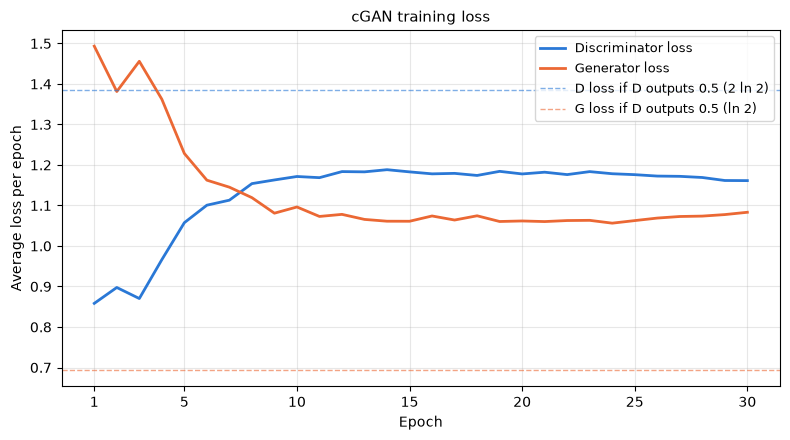

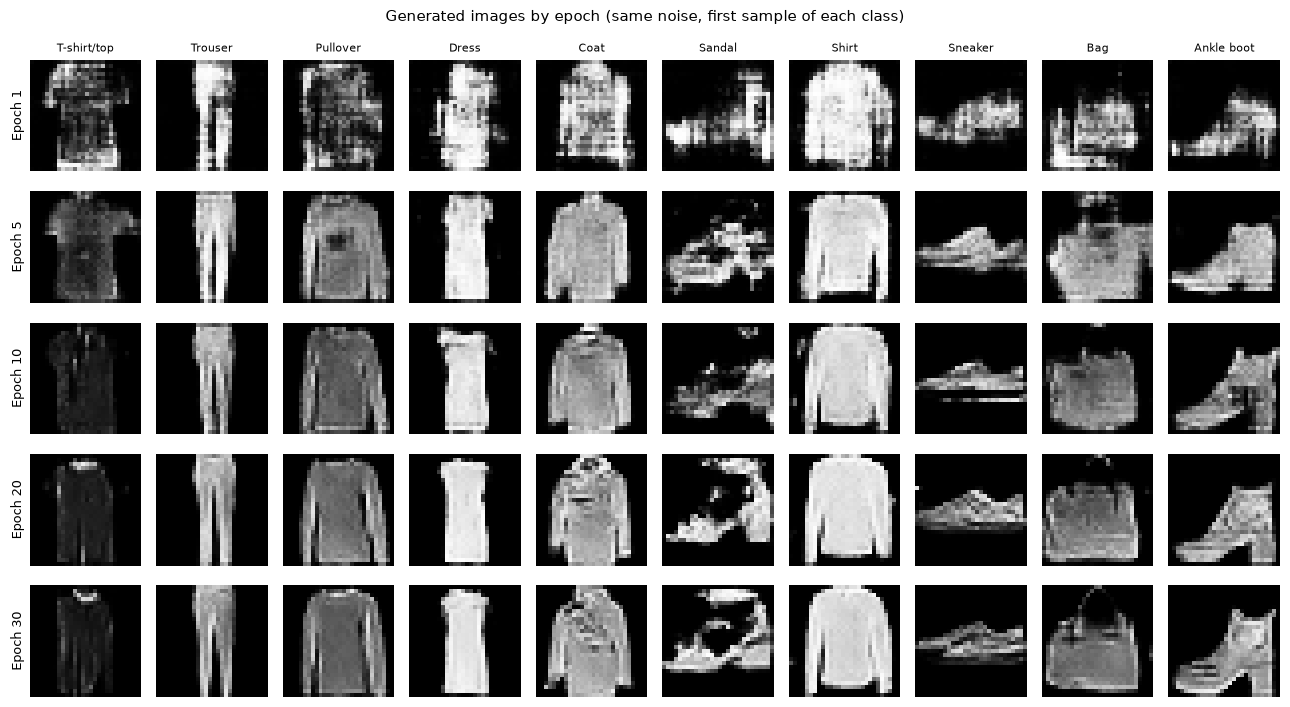

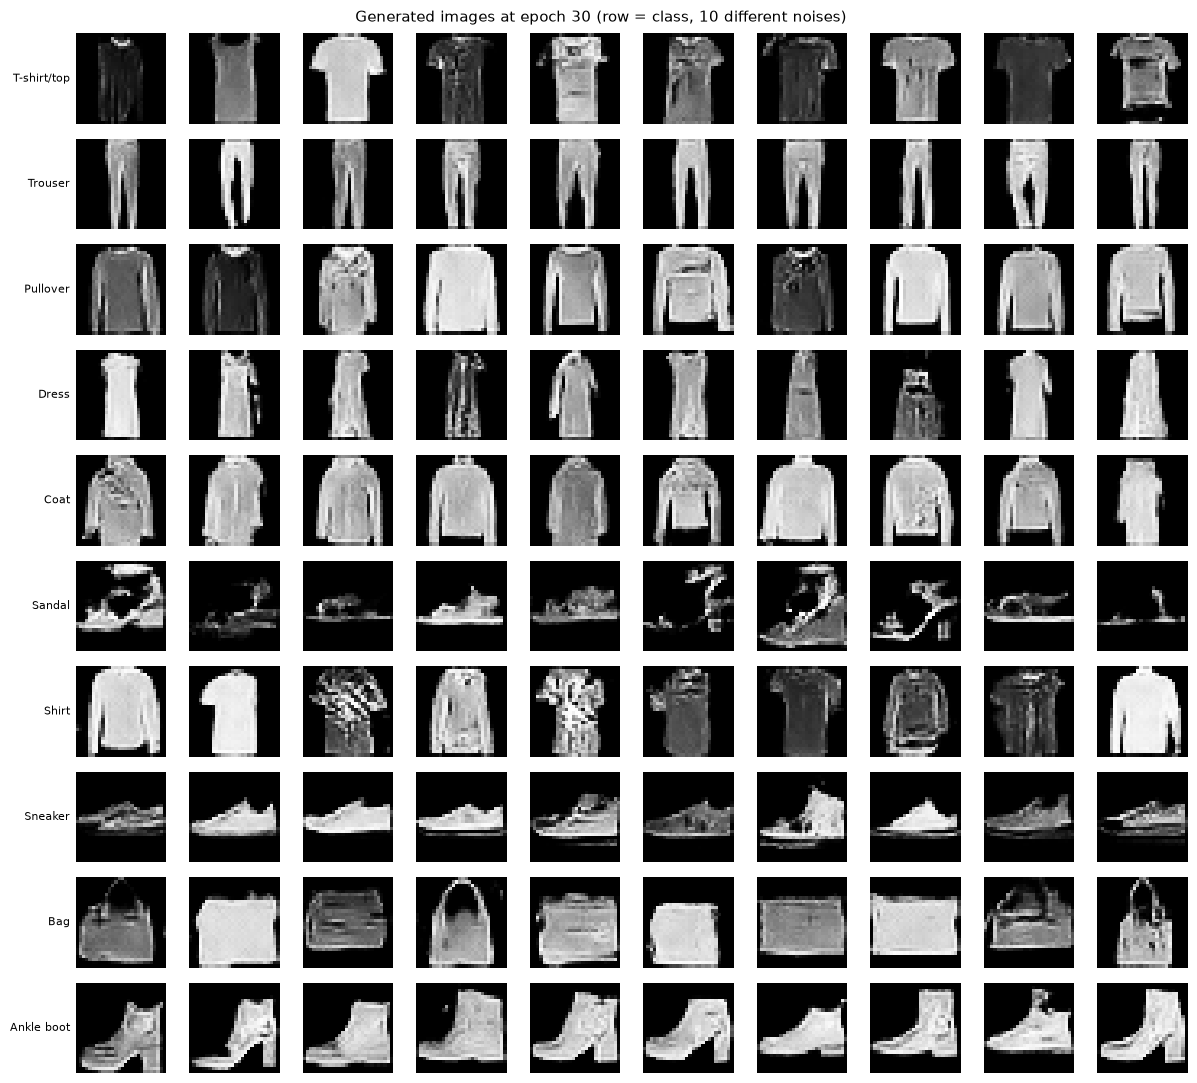

In [238]:
# 18-1. 그림 1: 손실 곡선
#  - 색: Discriminator #2a78d6, Generator #eb6834
#  - 점선: Discriminator가 모든 이미지에 0.5를 줄 때의 값 (D 손실 2 x ln2, G 손실 ln2)
epochs = range(1, len(history["loss_d"]) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs, history["loss_d"], color="#2a78d6", linewidth=2, label="Discriminator loss")
ax.plot(epochs, history["loss_g"], color="#eb6834", linewidth=2, label="Generator loss")
ax.axhline(2 * np.log(2), color="#2a78d6", linestyle="--", linewidth=1, alpha=0.6, label="D loss if D outputs 0.5 (2 ln 2)")
ax.axhline(np.log(2), color="#eb6834", linestyle="--", linewidth=1, alpha=0.6, label="G loss if D outputs 0.5 (ln 2)")
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.set_xlabel("Epoch")
ax.set_ylabel("Average loss per epoch")
ax.set_title("cGAN training loss", fontsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


# 18-2. 그림 2: 에폭별 이미지 변화 (한 줄 = 한 에폭, 한 칸 = 한 클래스)
#  - history["samples"][e - 1] : e번째 에폭이 끝난 뒤 고정 입력으로 만든 이미지 100장 (-1~1)
#  - 클래스 c의 첫 번째 이미지는 c * SAMPLES_PER_CLASS 번째에 있음 (고정 라벨이 [0]*10, [1]*10, ... 순서이므로)
SHOW_EPOCHS = [1, 5, 10, 20, 30]

fig, axes = plt.subplots(len(SHOW_EPOCHS), num_classes, figsize=(num_classes * 1.3, len(SHOW_EPOCHS) * 1.45))
for row, epoch in enumerate(SHOW_EPOCHS):
    samples = denormalize(history["samples"][epoch - 1])   # 0~1로 되돌리기
    for col in range(num_classes):
        ax = axes[row, col]
        ax.imshow(samples[col * SAMPLES_PER_CLASS, 0].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(class_names[col], fontsize=8)
    axes[row, 0].set_ylabel(f"Epoch {epoch}", fontsize=9)
fig.suptitle("Generated images by epoch (same noise, first sample of each class)", fontsize=11)
plt.tight_layout()
plt.show()


# 18-3. 그림 3: 마지막 에폭의 이미지 100장 (한 줄 = 한 클래스, 노이즈만 다른 10장)
final_samples = denormalize(history["samples"][-1])

fig, axes = plt.subplots(num_classes, SAMPLES_PER_CLASS, figsize=(SAMPLES_PER_CLASS * 1.1 + 1.2, num_classes * 1.1))
for k, ax in enumerate(axes.flat):   # 왼쪽 위부터 차례대로: k번째 칸 = k번째 고정 입력
    ax.imshow(final_samples[k, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    if k % SAMPLES_PER_CLASS == 0:   # 줄의 첫 칸에 클래스 이름
        ax.set_ylabel(class_names[fixed_labels[k].item()], fontsize=8, rotation=0, ha="right", va="center")
fig.suptitle(f"Generated images at epoch {len(history['samples'])} (row = class, 10 different noises)", fontsize=11)
plt.tight_layout()
plt.show()

### 결과
아래에서 'n번째'는 그림 3의 각 줄에서 왼쪽부터 센 순서입니다.

- 손실 곡선이 '17. 학습'의 출력과 같은 흐름인가?
  - 같은 흐름입니다. D 손실은 0.86에서 올라가고 G 손실은 1.49에서 내려가, 7~8에폭 사이에서 두 선이 교차한 뒤 9에폭 무렵부터 거의 평평합니다.
  - 30에폭 내내 D 손실은 점선(1.386)보다 아래, G 손실은 점선(0.693)보다 위에 있습니다.
- 에폭이 지날수록 이미지가 옷 모양에 가까워지는가? (그림 2)
  - 1에폭에서도 바지의 두 다리, 옆으로 놓인 신발처럼 클래스별 윤곽은 보이지만, 밝은 줄무늬와 얼룩이 많고 거칩니다.
  - 5에폭에는 Sandal을 빼면 대부분 무슨 물건인지 알아볼 수 있고, 표면도 매끄러워집니다.
  - 10~30에폭은 윤곽 변화는 작지만 세부 모양이 계속 바뀝니다. Sandal은 끈과 굽이 있는 샌들 모양이 되고, Bag은 손잡이가, Ankle boot는 굽이 점점 뚜렷해집니다.
  - T-shirt/top 칸은 10에폭부터 어두워지고, 30에폭에서는 어둡고 길쭉한 모양이라 T-shirt/top인지 알아보기 어렵습니다.
- 30에폭 이미지에서 각 줄이 그 클래스로 보이는가? (그림 3)
  - Trouser, Sneaker, Bag, Ankle boot 줄은 10장 모두 그 클래스로 보입니다. 다만 Ankle boot 9번째는 발목 부분이 낮아 Sneaker와 비슷해 보입니다.
  - T-shirt/top 줄은 대부분 반팔 티셔츠이고 2번째는 민소매입니다. 1번째는 어둡고 길쭉해 알아보기 어렵습니다.
  - Dress 줄은 대부분 원피스로 보이지만, 4번째와 8번째는 어둡고 무늬가 많아 모양이 흐트러져 있습니다.
  - Sandal 줄은 굽이 있는 것, 납작한 것, 끈만 있는 것 등 모양은 여러 가지이지만, 2, 3, 5, 10번째는 어둡고 가늘며 6번째는 조각난 모습이라, 다른 신발 줄보다 알아보기 어렵습니다.
- Pullover, Coat, Shirt가 서로 구별되는가?
  - Pullover와 Coat는 둘 다 긴팔 상의라 윤곽이 비슷해, 이 그림만으로는 뚜렷한 차이를 말하기 어렵습니다. 눈에 띄는 차이는 Pullover 줄에는 아주 어두운 이미지(2, 7번째)가 있고, Coat 줄은 대부분 밝은 회색이라는 정도입니다.
  - Shirt 줄은 긴팔(1, 4, 8, 10번째), 반팔(2, 3, 5, 6, 7번째), 체크나 무늬(3, 5번째)가 섞여 있습니다. 2번째(흰 반팔)는 T-shirt/top처럼, 1번째와 10번째(흰 긴팔)는 Pullover처럼 보입니다.
- 같은 줄의 10장이 서로 다른 모양인가? 특히 Sandal, Bag에서 한 가지 모양만 반복되지 않는가?
  - 10장이 모두 같은 줄은 없습니다. 모든 줄에서 모양이나 밝기가 서로 다릅니다.
  - Bag은 손잡이가 있는 것(1, 4, 9, 10번째), 없는 것(2, 6, 8번째), 각진 네모 모양(3, 7번째)이 섞여 있고, Sandal도 위와 같이 여러 모양이 나옵니다.
  - T-shirt/top, Pullover, Shirt 줄에는 어두운 이미지와 밝은 이미지가 함께 있습니다.

### 해석
- 대부분의 줄이 지정한 클래스로 보이므로, 클래스 번호를 조건으로 원하는 종류의 이미지를 만드는 것은 동작합니다. 가장 뚜렷한 것은 Trouser, Sneaker, Bag, Ankle boot이고, 가장 알아보기 어려운 것은 Sandal입니다.
- 9에폭 이후 손실은 거의 변하지 않았지만, 그림 2에서는 Sandal, Bag, Ankle boot의 세부 모양이 30에폭까지 계속 바뀌었습니다. '17. 학습'의 해석처럼 손실만으로는 이미지의 변화를 알 수 없습니다.
- Pullover, Coat, Shirt가 잘 구별되지 않는 것과 Shirt 일부가 T-shirt/top처럼 보이는 것은, '9. EDA 정리'에서 원본 데이터도 이 클래스들의 윤곽이 비슷하고 경계가 애매한 이미지가 섞여 있다고 확인한 것과 같은 모습입니다. 다만 이것이 원본 데이터의 특징 때문인지, 모델이 덜 배운 것인지는 이 그림만으로는 나눌 수 없습니다.
- Sandal은 '9. EDA 정리'에서 원본 샘플의 모양이 제각각이고 평균 이미지가 흐렸던 클래스입니다. 생성 결과가 다른 신발보다 흐트러진 것과 관련이 있을 수 있지만, 이 그림만으로는 확인할 수 없습니다.
- 같은 줄 안에서 모양과 밝기가 다양하게 나오므로, 적어도 이 100장에서는 한 가지 모양만 반복해서 만드는 모습은 보이지 않습니다. T-shirt/top, Pullover, Shirt에서 밝기가 넓게 퍼진 것도 '9. EDA 정리'에서 확인한 원본 데이터의 특징과 같습니다.

### 한계
- 모든 판단은 눈으로 본 것이라 사람마다 다르게 볼 수 있습니다.
- 고정 입력 100장(클래스마다 10장)만 봤으므로, 다른 노이즈로 만든 이미지에서는 다르게 보일 수 있습니다.
- 진짜 이미지와 나란히 놓고 비교하지 않았고, 숫자로 된 평가 지표(FID 등)는 아직 계산하지 않았습니다.

## 19. 평가 준비: 평가용 분류기

생성 이미지를 숫자로 평가할 때 쓸 옷 종류 분류기를 학습하고, 테스트 데이터로 이 분류기를 믿을 수 있는지 확인합니다.

### 목적
- '21. 정량 평가: 분류기 정확도'에서는 생성 이미지를 이 분류기에 넣어, 요청한 클래스로 맞히는 비율을 잽니다.
- '22. 정량 평가: FID'에서는 이 분류기가 뽑은 특징(숫자 128개)으로 생성 이미지와 테스트 이미지의 거리를 잽니다.
- 분류기가 틀리면 평가도 틀리므로, 먼저 진짜 테스트 이미지로 분류기의 정확도를 확인합니다. 이 정확도는 생성 이미지 정확도와 비교할 기준값이 됩니다.

### 방법
| 단계 | 하는 일 | 출력 모양 |
| --- | --- | --- |
| 1. 합성곱 + 최대 풀링 | 특징을 뽑고 크기를 절반으로 줄입니다. | (32, 14, 14) |
| 2. 합성곱 + 최대 풀링 | 특징을 뽑고 크기를 다시 절반으로 줄입니다. | (64, 7, 7) |
| 3. 완전연결층 | 한 줄로 펼쳐 숫자 128개로 만듭니다. 이 128개를 FID 특징으로 씁니다. | (128,) |
| 4. 출력층 | 10개 클래스의 점수를 냅니다. | (10,) |

- 최대 풀링(`MaxPool2d`): 2×2 칸마다 가장 큰 값 하나만 남겨 크기를 절반으로 줄이는 층입니다.
- 입력: '11. 전처리: 픽셀 값 변환'과 같은 -1~1 이미지입니다. 그래서 Generator가 만든 이미지를 그대로 넣을 수 있습니다. 학습에는 '12. 전처리: DataLoader 구성'의 `train_loader`, 확인에는 `test_loader`를 그대로 씁니다.
- 학습 설정
  - 손실 함수: `CrossEntropyLoss`. 정답 클래스의 점수가 다른 클래스보다 높아지도록 학습합니다.
  - 옵티마이저: Adam, 학습률 0.001(Adam 기본값)
  - 에폭 수: 10. 근거가 있는 값이 아니라 정한 값이며, 충분한지는 테스트 정확도를 보고 판단합니다.
  - 시드: 42
- 테스트 데이터는 학습에 쓰지 않고, 학습이 끝난 뒤 정확도를 확인할 때만 씁니다. 테스트 정확도를 보면서 설정을 고치면 테스트 데이터가 공정한 기준 역할을 못 하기 때문입니다.
- 학습 중 정확도는 에폭 안에서 가중치가 계속 바뀌는 동안 잰 값이라, 에폭이 끝난 뒤의 정확도와 조금 다를 수 있습니다.
- 저장과 불러오기: '16. 학습 설정'과 같은 규칙입니다.
  - 10 에폭 학습을 모두 마쳤을 때만 `results/cgan_jaeone/classifier.pt`로 저장합니다.
  - 파일이 있으면 학습을 건너뛰고 불러와 쓰며, 저장된 에폭별 기록을 다시 출력합니다.
  - 학습 도중 멈추면 저장하지 않습니다. 이 셀을 다시 실행하면 분류기를 새로 만들어 처음부터 학습합니다.
- 이후 섹션에서 쓸 것도 함께 준비합니다.
  - `test_images_gan`, `test_labels_gan`: 테스트 이미지 10,000장(-1~1)과 라벨을 한 덩어리로 모아 둡니다.
    - '4. 클래스(옷 종류)별 이미지 개수 확인'과 '6. 이상치 확인'의 `test_labels`, `test_images`(0~255 원본)와 섞이지 않도록, `test_dataset_gan`처럼 이름 뒤에 `_gan`을 붙입니다.
  - `predict_probs(images)`: 이미지 묶음을 받아 클래스별 확률을 돌려주는 함수입니다. 확률은 10개 클래스 점수를 softmax로 바꾼 값으로, 0~1이고 합이 1입니다. 생성 이미지에도 그대로 씁니다.
  - `test_acc_per_class`: 클래스별 테스트 정확도. '21. 정량 평가: 분류기 정확도'의 기준값으로 씁니다.

### 확인할 점
- 처음 실행이라면 10 에폭이 오류 없이 끝나고 저장 메시지가 출력되는가?
- 에폭이 지날수록 학습 손실은 줄고 학습 중 정확도는 올라가는가?
- 전체 테스트 정확도는 몇 %인가? 학습 중 정확도와 차이가 큰가? 차이가 크면 학습 데이터에만 맞춰진 상태(과적합)일 수 있습니다.
- 클래스별 테스트 정확도가 낮은 클래스는 어디인가? '9. EDA 정리'에서 서로 비슷하다고 본 Pullover, Coat, Shirt가 낮은가?

In [239]:
# 19-1. 평가용 분류기 정의
class FashionClassifier(nn.Module):
    """이미지 (1, 28, 28), -1~1 범위를 받아 10개 클래스의 점수를 내보내는 작은 CNN입니다."""

    def __init__(self, n_classes=num_classes):
        super().__init__()
        # 1~2. 합성곱 + 최대 풀링: 28x28 → 14x14 → 7x7
        #  - kernel_size=3, padding=1: 합성곱을 지나도 크기가 그대로인 조합 (크기는 최대 풀링이 절반으로 줄임)
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),    # (32, 28, 28)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                                # (32, 14, 14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),   # (64, 14, 14)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                                # (64, 7, 7)
        )
        # 3. 완전연결층: 숫자 128개 ('22. 정량 평가: FID'에서 특징으로 사용)
        self.feature_layer = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(inplace=True),
        )
        # 4. 출력층: 10개 클래스의 점수
        self.output_layer = nn.Linear(128, n_classes)

    def extract_features(self, x):
        """FID 계산에 쓸 특징(숫자 128개)을 돌려줍니다."""
        return self.feature_layer(self.conv(x))

    def forward(self, x):
        return self.output_layer(self.extract_features(x))


# 19-2. 분류기 설정값과 모델 생성
CLF_EPOCHS = 10                          # 정한 값 (테스트 정확도를 보고 충분한지 판단)
CLF_LR = 0.001                           # Adam 기본값
CLF_SEED = 42
CLF_PATH = CKPT_DIR / "classifier.pt"    # '16. 학습 설정'의 CKPT_DIR (results/cgan_jaeone)

torch.manual_seed(CLF_SEED)
classifier = FashionClassifier().to(device)


# 19-3. 학습이 끝난 분류기 파일이 있으면 불러오고, 없으면 학습한 뒤 저장
print(f"분류기 파일 위치 : {CLF_PATH.as_posix()}")
if CLF_PATH.exists():
    loaded_clf = torch.load(CLF_PATH, map_location="cpu", weights_only=True)
    classifier.load_state_dict(loaded_clf["classifier"])
    clf_history = loaded_clf["history"]
    print("학습이 끝난 분류기 파일 있음 → 불러와 사용하고 학습을 건너뜁니다.")
    print("저장된 기록의 에폭별 평균 손실과 학습 중 정확도 (걸린 시간은 저장하지 않아 표시하지 않음)\n")
    for epoch, (avg_loss, train_acc) in enumerate(zip(clf_history["loss"], clf_history["train_acc"]), start=1):
        print(f"[{epoch:2d}/{len(clf_history['loss'])}] 손실 {avg_loss:.4f} | 학습 중 정확도 {train_acc:.2%}")
else:
    print(f"저장된 분류기 파일 없음 → 처음부터 {CLF_EPOCHS} 에폭 학습한 뒤 저장합니다.\n")
    clf_criterion = nn.CrossEntropyLoss()
    optimizer_c = torch.optim.Adam(classifier.parameters(), lr=CLF_LR)
    clf_history = {"loss": [], "train_acc": []}

    classifier.train()
    for epoch in range(1, CLF_EPOCHS + 1):
        epoch_start = time.perf_counter()
        sum_loss, n_correct, n_seen = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            logits = classifier(images)                  # 10개 클래스의 점수
            loss = clf_criterion(logits, labels)

            optimizer_c.zero_grad()
            loss.backward()
            optimizer_c.step()

            sum_loss += loss.item()
            n_correct += (logits.argmax(dim=1) == labels).sum().item()   # 점수가 가장 높은 클래스 = 예측
            n_seen += labels.size(0)

        clf_history["loss"].append(sum_loss / len(train_loader))
        clf_history["train_acc"].append(n_correct / n_seen)
        print(f"[{epoch:2d}/{CLF_EPOCHS}] 손실 {clf_history['loss'][-1]:.4f} | "
              f"학습 중 정확도 {clf_history['train_acc'][-1]:.2%} | {time.perf_counter() - epoch_start:.1f}초")

    # 10 에폭을 모두 마친 뒤 한 번만 저장 (임시 파일에 먼저 쓴 뒤 이름 바꾸기)
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    clf_tmp_path = CLF_PATH.with_name(CLF_PATH.name + ".tmp")
    torch.save({"num_epochs": CLF_EPOCHS, "classifier": classifier.state_dict(), "history": clf_history}, clf_tmp_path)
    clf_tmp_path.replace(CLF_PATH)
    print(f"\n분류기 학습 완료 → 저장 : {CLF_PATH.as_posix()}")


# 19-4. 테스트 이미지 모으기 + 클래스별 확률 계산 함수
#  - test_images_gan : (10000, 1, 28, 28), -1~1 / test_labels_gan : (10000,)
test_images_gan = torch.cat([images for images, _ in test_loader])
test_labels_gan = torch.cat([labels for _, labels in test_loader])


@torch.no_grad()   # 확인만 하므로 학습용 계산 기록은 남기지 않음
def predict_probs(images, batch_size=1000):
    """이미지 묶음 (N, 1, 28, 28), -1~1 을 받아 클래스별 확률 (N, 10)을 CPU 텐서로 돌려줍니다."""
    classifier.eval()
    probs = []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size].to(device)
        probs.append(torch.softmax(classifier(batch), dim=1).cpu())   # 점수 → 합이 1인 확률
    return torch.cat(probs)


# 19-5. 테스트 정확도 (전체, 클래스별)
test_pred = predict_probs(test_images_gan).argmax(dim=1)   # 확률이 가장 높은 클래스 = 예측
test_acc = (test_pred == test_labels_gan).float().mean().item()
print(f"\n테스트 정확도 (전체 {len(test_labels_gan):,}장) : {test_acc:.2%}")
print(f"마지막 에폭 학습 중 정확도         : {clf_history['train_acc'][-1]:.2%}")

print("\n클래스별 테스트 정확도")
test_acc_per_class = []
for c in range(num_classes):
    is_class = test_labels_gan == c
    acc_c = (test_pred[is_class] == c).float().mean().item()
    test_acc_per_class.append(acc_c)
    print(f"  {class_names[c]:<12} : {acc_c:.2%} ({is_class.sum().item():,}장)")

분류기 파일 위치 : ../results/cgan_jaeone/classifier.pt
학습이 끝난 분류기 파일 있음 → 불러와 사용하고 학습을 건너뜁니다.
저장된 기록의 에폭별 평균 손실과 학습 중 정확도 (걸린 시간은 저장하지 않아 표시하지 않음)

[ 1/10] 손실 0.4879 | 학습 중 정확도 82.62%
[ 2/10] 손실 0.3066 | 학습 중 정확도 89.00%
[ 3/10] 손실 0.2593 | 학습 중 정확도 90.61%
[ 4/10] 손실 0.2285 | 학습 중 정확도 91.69%
[ 5/10] 손실 0.2034 | 학습 중 정확도 92.56%
[ 6/10] 손실 0.1839 | 학습 중 정확도 93.30%
[ 7/10] 손실 0.1665 | 학습 중 정확도 93.92%
[ 8/10] 손실 0.1487 | 학습 중 정확도 94.64%
[ 9/10] 손실 0.1329 | 학습 중 정확도 95.13%
[10/10] 손실 0.1189 | 학습 중 정확도 95.67%

테스트 정확도 (전체 10,000장) : 92.29%
마지막 에폭 학습 중 정확도         : 95.67%

클래스별 테스트 정확도
  T-shirt/top  : 86.00% (1,000장)
  Trouser      : 98.80% (1,000장)
  Pullover     : 88.80% (1,000장)
  Dress        : 91.40% (1,000장)
  Coat         : 88.40% (1,000장)
  Sandal       : 99.10% (1,000장)
  Shirt        : 78.70% (1,000장)
  Sneaker      : 97.10% (1,000장)
  Bag          : 98.40% (1,000장)
  Ankle boot   : 96.20% (1,000장)


### 결과
- 처음 실행이라면 10 에폭이 오류 없이 끝나고 저장 메시지가 출력되는가?
  - 이번 실행은 처음 실행이 아니어서, "학습이 끝난 분류기 파일 있음 → 불러와 사용하고 학습을 건너뜁니다."와 저장된 기록이 출력되었습니다.
  - 저장된 기록에 1~10 에폭의 손실과 학습 중 정확도가 모두 있으므로, 10 에폭 학습을 끝까지 마친 파일입니다. 걸린 시간은 저장하지 않아 출력되지 않습니다.
- 에폭이 지날수록 학습 손실은 줄고 학습 중 정확도는 올라가는가?
  - 손실은 0.4879에서 0.1189로, 에폭마다 줄었습니다.
  - 학습 중 정확도는 82.62%에서 95.67%로, 에폭마다 올랐습니다.
- 전체 테스트 정확도는 몇 %인가? 학습 중 정확도와 차이가 큰가?
  - 테스트 정확도는 92.29%(10,000장)입니다.
  - 마지막 에폭 학습 중 정확도(95.67%)보다 3.38%p 낮습니다.
- 클래스별 테스트 정확도가 낮은 클래스는 어디인가?

| 클래스 | 테스트 정확도 |
| --- | --- |
| Shirt | 78.70% |
| T-shirt/top | 86.00% |
| Coat | 88.40% |
| Pullover | 88.80% |
| Dress | 91.40% |
| Ankle boot | 96.20% |
| Sneaker | 97.10% |
| Bag | 98.40% |
| Trouser | 98.80% |
| Sandal | 99.10% |

  - 가장 낮은 클래스는 Shirt(78.70%)이고, 그다음이 T-shirt/top, Coat, Pullover입니다. 이 네 클래스만 90%보다 낮습니다.
  - Ankle boot, Sneaker, Bag, Trouser, Sandal은 96% 이상입니다.

### 해석
- 분류기는 진짜 테스트 이미지 10장 중 약 9장의 클래스를 맞힙니다. 이 분류기를 그대로 평가에 사용합니다. 테스트 데이터가 공정한 기준으로 남도록, 이 결과를 보고 설정을 고쳐 다시 학습하지는 않습니다.
- 학습 중 정확도가 테스트 정확도보다 3.38%p 높아, 분류기가 학습 데이터에 조금 더 맞춰져 있습니다. 다만 학습 중 정확도는 에폭 안에서 가중치가 바뀌는 동안 잰 값이라, 정확한 차이는 아닙니다.
- 10 에폭까지 손실이 계속 줄고 있어 학습이 다 끝난 상태는 아닙니다. 하지만 에폭을 늘렸을 때 테스트 정확도도 오를지는 이 결과만으로는 알 수 없습니다.
- 정확도가 낮은 Shirt, T-shirt/top, Coat, Pullover는 '9. EDA 정리'에서 윤곽이 서로 비슷하거나 경계가 애매하다고 본 클래스들입니다. 진짜 이미지도 분류기가 헷갈릴 만큼 구별이 어려운 클래스라는 뜻입니다.
- 그래서 '21. 정량 평가: 분류기 정확도'에서는 클래스별 생성 이미지 정확도를 100%가 아니라 이 클래스별 테스트 정확도와 비교해서 봅니다. 예를 들어 생성한 Shirt의 정확도는 78.70% 근처면 진짜 Shirt와 비슷한 수준입니다.
- Sandal은 테스트 정확도가 99.10%로 가장 높습니다. '18. 학습 결과 확인'에서 생성한 Sandal이 가장 알아보기 어려웠으므로, 생성한 Sandal의 정확도가 낮게 나온다면 분류기가 Sandal을 못 맞혀서가 아니라 생성 이미지 쪽의 문제일 가능성이 큽니다.

### 한계
- 분류기는 한 가지 설정과 시드로 한 번만 학습했습니다.
- 테스트 정확도가 100%가 아니므로, 생성 이미지의 정확도에는 분류기 자체의 오차도 섞여 있습니다.
- 분류기는 진짜 이미지로만 학습했기 때문에, 생성 이미지의 흐릿함이나 얼룩에 어떻게 반응하는지는 이 결과로 알 수 없습니다.

## 20. 평가 준비: 평가용 생성 이미지

학습이 끝난 Generator로, 정량 평가에 쓸 생성 이미지를 클래스당 1,000장씩 만듭니다.

### 목적
- '21. 정량 평가: 분류기 정확도', '22. 정량 평가: FID', '23. 정량 평가: 밝기 분포'에서 쓸 생성 이미지를 한 번에 만들어 둡니다. 세 평가가 모두 같은 생성 이미지를 쓰게 하기 위해서입니다.
- 테스트 데이터와 같은 수(클래스당 1,000장, 모두 10,000장)로 만들어, 테스트 이미지와 같은 조건에서 비교합니다.

### 방법
- 클래스 번호: 0~9를 1,000개씩 차례로 만듭니다(`gen_labels`).
- 노이즈: 10,000개를 시드 123으로 정한 별도의 난수 생성기로 만듭니다. '16. 학습 설정'의 고정 입력(시드 42)과 다른 시드를 써서, '18. 학습 결과 확인'에서 이미 본 이미지와 겹치지 않게 합니다.
- Generator를 평가 모드(`eval()`)로 두고, 1,000장씩 나눠 만듭니다. 평가 모드에서는 BatchNorm이 학습 때 기록해 둔 통계를 쓰므로, 한 번에 만드는 장수와 상관없이 같은 입력이면 같은 이미지가 나옵니다.
- 만든 이미지(`gen_images`)는 -1~1 범위 그대로 둡니다. 테스트 이미지(`test_images_gan`)와 같은 범위라서, '19. 평가 준비: 평가용 분류기'의 `predict_probs`에 그대로 넣을 수 있습니다.
- 생성 이미지는 파일로 저장하지 않습니다. 저장된 Generator와 시드가 같으면 다시 실행해도 같은 이미지가 만들어지기 때문입니다. 다만 GPU 계산 특성상 아주 작은 차이는 생길 수 있습니다.

### 확인할 점
- 생성 이미지가 (10000, 1, 28, 28), 라벨이 (10000,)인가?
- 값이 -1~1 범위 안에 있는가?
- 클래스별 개수가 생성 이미지와 테스트 이미지 모두 1,000장씩인가?

In [240]:
# 20-1. 평가용 생성 설정값
EVAL_PER_CLASS = 1000   # 클래스당 생성할 이미지 수 (테스트 데이터의 클래스당 개수와 같음)
EVAL_SEED = 123         # '16. 학습 설정'의 고정 입력(시드 42)과 겹치지 않도록 다른 시드
GEN_BATCH = 1000        # 한 번에 만들 이미지 수


# 20-2. 클래스 번호와 노이즈 만들기
#  - gen_labels : [0]*1000, [1]*1000, ..., [9]*1000
#  - eval_z     : 시드를 정한 별도의 난수 생성기로 만들어 매번 같게 나옴
gen_labels = torch.arange(num_classes).repeat_interleave(EVAL_PER_CLASS)
eval_rng = torch.Generator().manual_seed(EVAL_SEED)
eval_z = torch.randn(len(gen_labels), LATENT_DIM, generator=eval_rng)


# 20-3. 생성 (평가 모드, 1,000장씩)
generator.eval()   # BatchNorm이 학습 때 기록해 둔 통계를 사용
gen_chunks = []
with torch.no_grad():   # 생성만 하므로 학습용 계산 기록은 남기지 않음
    for start in range(0, len(gen_labels), GEN_BATCH):
        z = eval_z[start:start + GEN_BATCH].to(device)
        y = gen_labels[start:start + GEN_BATCH].to(device)
        gen_chunks.append(generator(z, y).cpu())
gen_images = torch.cat(gen_chunks)   # (10000, 1, 28, 28), -1~1


# 20-4. 확인: 모양, 값 범위, 클래스별 개수 (생성 vs 테스트)
print(f"생성 이미지 shape : {tuple(gen_images.shape)}, 라벨 shape : {tuple(gen_labels.shape)}")
print(f"생성 이미지 값 범위 : [{gen_images.min().item():.3f}, {gen_images.max().item():.3f}]")
print(f"테스트 이미지 shape : {tuple(test_images_gan.shape)}, 라벨 shape : {tuple(test_labels_gan.shape)}")
print(f"\n클래스별 개수 (생성) : {torch.bincount(gen_labels, minlength=num_classes).tolist()}")
print(f"클래스별 개수 (테스트) : {torch.bincount(test_labels_gan, minlength=num_classes).tolist()}")

생성 이미지 shape : (10000, 1, 28, 28), 라벨 shape : (10000,)
생성 이미지 값 범위 : [-1.000, 1.000]
테스트 이미지 shape : (10000, 1, 28, 28), 라벨 shape : (10000,)

클래스별 개수 (생성) : [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
클래스별 개수 (테스트) : [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


### 결과
- 생성 이미지가 (10000, 1, 28, 28), 라벨이 (10000,)인가?
  - 생성 이미지는 (10000, 1, 28, 28), 라벨은 (10000,)이고, 테스트 이미지·라벨과 모양이 같습니다.
- 값이 -1~1 범위 안에 있는가?
  - 생성 이미지의 값 범위는 [-1.000, 1.000]입니다.
- 클래스별 개수가 생성 이미지와 테스트 이미지 모두 1,000장씩인가?
  - 생성과 테스트 모두 10개 클래스가 1,000장씩입니다.

### 해석
- 생성 이미지와 테스트 이미지는 모양, 값 범위, 클래스별 개수가 같습니다. 따라서 21~23의 정량 평가에서 두 이미지 묶음을 같은 조건으로 비교할 수 있습니다.
- 값 범위 [-1.000, 1.000]은 '12. 전처리: DataLoader 구성'에서 확인한 진짜 이미지의 범위와 같습니다. 생성 이미지에도 가장 어두운 값(-1, 검은 배경)과 가장 밝은 값(1)에 가까운 픽셀이 있다는 뜻입니다.

## 21. 정량 평가: 분류기 정확도

생성 이미지가 요청한 클래스로 보이는지를, '19. 평가 준비: 평가용 분류기'의 분류기로 숫자로 확인합니다.

### 목적
- 조건부 생성 성능, 즉 클래스 번호를 지정했을 때 그 클래스의 이미지가 나오는지를 가장 직접 보여주는 평가입니다.
- 어떤 클래스를 어떤 클래스로 헷갈리는지 보고, 진짜 테스트 이미지에서도 같은 헷갈림이 있는지 비교합니다. '18. 학습 결과 확인'에서 남긴 질문, 즉 Pullover, Coat, Shirt가 잘 구별되지 않는 것이 원본 데이터의 특징인지 모델이 덜 배운 것인지를 확인하기 위해서입니다.

### 방법
- '20. 평가 준비: 평가용 생성 이미지'의 10,000장을 `predict_probs`에 넣고, 확률이 가장 높은 클래스를 분류기의 예측으로 봅니다.
- 정확도: 예측한 클래스가 요청한 클래스와 같은 비율입니다. 전체와 클래스별로 계산합니다.
- 기준값: 같은 분류기의 테스트 정확도(전체 92.29%, 클래스별 값은 '19. 평가 준비: 평가용 분류기')입니다. 생성 이미지의 정확도가 기준값에 가까우면, 분류기가 보기에 진짜 이미지만큼 그 클래스로 보인다는 뜻입니다.
- 생성 이미지의 정확도가 기준값보다 높게 나올 수도 있습니다. 이것은 진짜보다 낫다는 뜻이 아니라, 생성 이미지가 그 클래스의 전형적인 모양에 몰려 있을 가능성도 있다는 뜻입니다. 그래서 다양성까지 반영하는 '22. 정량 평가: FID'와 함께 봅니다.
- 혼동 행렬: 어떤 클래스를 어떤 클래스로 예측했는지 세어 놓은 표입니다.
  - 행은 요청한 클래스(테스트 이미지는 실제 클래스), 열은 분류기가 예측한 클래스입니다.
  - 각 칸의 값은 그 행의 이미지 중 그 열로 예측된 비율(%)입니다. 대각선은 맞힌 비율, 대각선 밖은 헷갈린 비율입니다.
  - 테스트 이미지와 생성 이미지의 혼동 행렬을 나란히 그립니다. 1% 미만인 칸은 숫자를 생략합니다.
- 출력
  - 전체 정확도와 클래스별 정확도(테스트, 생성, 차이)
  - 가장 많이 헷갈린 클래스 쌍 상위 5개 (테스트, 생성 각각)
  - 그림 1: 클래스별 정확도 막대그래프 (테스트 #eb6834, 생성 #2a78d6)
  - 그림 2: 혼동 행렬 두 개 (테스트, 생성)

### 확인할 점
- 생성 이미지의 전체 정확도는 테스트 정확도(92.29%)와 얼마나 차이 나는가?
- 기준값보다 크게 낮은 클래스는 어디인가? 특히 '18. 학습 결과 확인'에서 가장 알아보기 어려웠던 Sandal은 어떤가?
- 생성 이미지에서 많이 헷갈리는 쌍이 테스트 이미지에서도 많이 헷갈리는 쌍과 같은가? Pullover, Coat, Shirt는 어떤가?

전체 정확도 : 테스트 92.29% | 생성 92.08% | 차이(생성 - 테스트) -0.21%p

클래스별 정확도
  T-shirt/top  : 테스트  86.00% | 생성  84.90% | 차이  -1.10%p
  Trouser      : 테스트  98.80% | 생성  99.70% | 차이  +0.90%p
  Pullover     : 테스트  88.80% | 생성  93.10% | 차이  +4.30%p
  Dress        : 테스트  91.40% | 생성  95.00% | 차이  +3.60%p
  Coat         : 테스트  88.40% | 생성  83.50% | 차이  -4.90%p
  Sandal       : 테스트  99.10% | 생성  99.60% | 차이  +0.50%p
  Shirt        : 테스트  78.70% | 생성  71.80% | 차이  -6.90%p
  Sneaker      : 테스트  97.10% | 생성  96.40% | 차이  -0.70%p
  Bag          : 테스트  98.40% | 생성  98.30% | 차이  -0.10%p
  Ankle boot   : 테스트  96.20% | 생성  98.50% | 차이  +2.30%p

가장 많이 헷갈린 쌍 상위 5개 (테스트) : 실제(요청) → 예측
  T-shirt/top  → Shirt        :   9.5%
  Shirt        → T-shirt/top  :   8.4%
  Shirt        → Coat         :   5.7%
  Coat         → Shirt        :   5.7%
  Pullover     → Shirt        :   4.6%

가장 많이 헷갈린 쌍 상위 5개 (생성) : 실제(요청) → 예측
  T-shirt/top  → Shirt        :  10.2%
  Shirt        → Pullover     :   9.4%
  Shirt        → T-shirt/

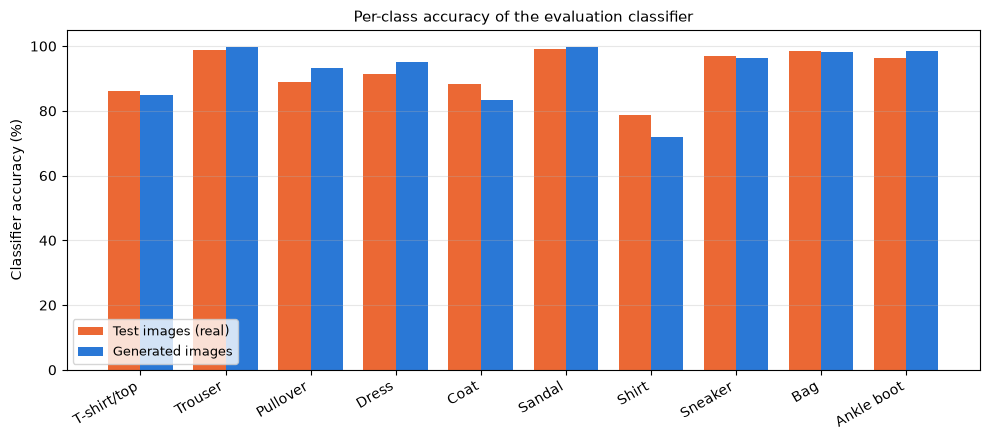

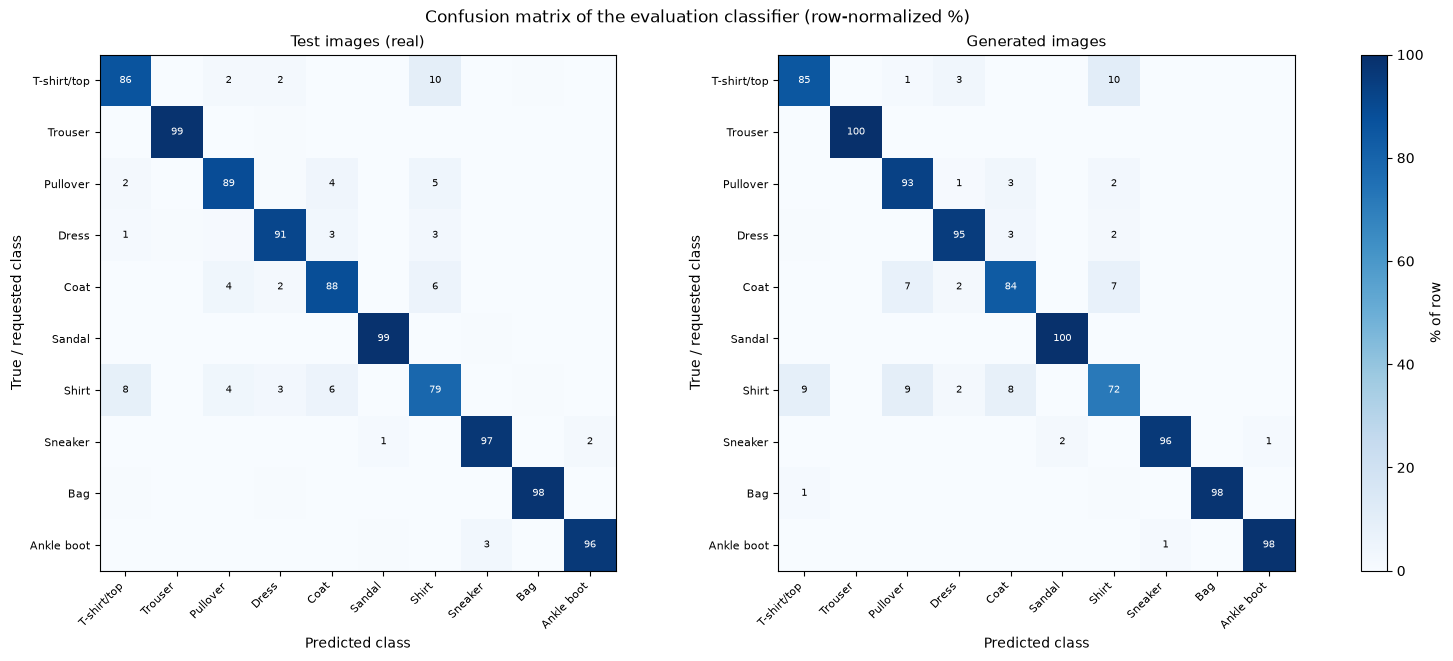

In [241]:
# 21-1. 생성 이미지 분류
#  - gen_images, gen_labels : '20. 평가 준비: 평가용 생성 이미지'의 10,000장과 요청한 클래스
#  - predict_probs          : '19. 평가 준비: 평가용 분류기'의 확률 계산 함수
gen_pred = predict_probs(gen_images).argmax(dim=1)   # 확률이 가장 높은 클래스 = 예측
gen_acc = (gen_pred == gen_labels).float().mean().item()


# 21-2. 전체 정확도와 클래스별 정확도 (테스트 vs 생성)
#  - test_acc, test_acc_per_class, test_pred : '19. 평가 준비: 평가용 분류기'의 결과
gen_acc_per_class = [(gen_pred[gen_labels == c] == c).float().mean().item() for c in range(num_classes)]

print(f"전체 정확도 : 테스트 {test_acc:.2%} | 생성 {gen_acc:.2%} | 차이(생성 - 테스트) {(gen_acc - test_acc) * 100:+.2f}%p")
print("\n클래스별 정확도")
for c in range(num_classes):
    diff = (gen_acc_per_class[c] - test_acc_per_class[c]) * 100
    print(f"  {class_names[c]:<12} : 테스트 {test_acc_per_class[c]:7.2%} | 생성 {gen_acc_per_class[c]:7.2%} | 차이 {diff:+6.2f}%p")


# 21-3. 혼동 행렬 (행 = 요청한/실제 클래스, 열 = 예측한 클래스, 값 = 행마다 비율 %)
def confusion_percent(true_labels, pred_labels):
    """실제 클래스와 예측 클래스를 받아, 행마다 합이 100인 혼동 행렬(%)을 numpy 배열로 돌려줍니다."""
    # 실제 t, 예측 p인 경우를 t * 10 + p 번 칸에 세어서 10 x 10 표로 바꿈
    counts = torch.bincount(true_labels * num_classes + pred_labels, minlength=num_classes ** 2)
    counts = counts.view(num_classes, num_classes).float()
    return (counts / counts.sum(dim=1, keepdim=True) * 100).numpy()


cm_test = confusion_percent(test_labels_gan, test_pred)
cm_gen = confusion_percent(gen_labels, gen_pred)


# 21-4. 가장 많이 헷갈린 클래스 쌍 상위 5개 (대각선 밖 칸 중 비율이 큰 순서)
def top_confusions(cm, k=5):
    """혼동 행렬에서 대각선 밖 값이 가장 큰 k개를 (실제, 예측, 비율) 목록으로 돌려줍니다."""
    off_diag = [(cm[i, j], i, j) for i in range(num_classes) for j in range(num_classes) if i != j]
    return [(class_names[i], class_names[j], v) for v, i, j in sorted(off_diag, reverse=True)[:k]]


for name, cm in [("테스트", cm_test), ("생성", cm_gen)]:
    print(f"\n가장 많이 헷갈린 쌍 상위 5개 ({name}) : 실제(요청) → 예측")
    for true_name, pred_name, v in top_confusions(cm):
        print(f"  {true_name:<12} → {pred_name:<12} : {v:5.1f}%")


# 21-5. 그림 1: 클래스별 정확도 (테스트 vs 생성)
x = np.arange(num_classes)
bar_width = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - bar_width / 2, np.array(test_acc_per_class) * 100, bar_width, color="#eb6834", label="Test images (real)")
ax.bar(x + bar_width / 2, np.array(gen_acc_per_class) * 100, bar_width, color="#2a78d6", label="Generated images")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=30, ha="right")
ax.set_ylim(0, 105)
ax.set_ylabel("Classifier accuracy (%)")
ax.set_title("Per-class accuracy of the evaluation classifier", fontsize=11)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()


# 21-6. 그림 2: 혼동 행렬 (왼쪽 테스트, 오른쪽 생성)
#  - 색: 한 가지 색(파랑)의 진하기로 비율 표시, 0~100%
#  - 1% 미만인 칸은 숫자를 생략해 읽기 쉽게 함
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), layout="constrained")
for ax, cm, title in zip(axes, [cm_test, cm_gen], ["Test images (real)", "Generated images"]):
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(num_classes):
        for j in range(num_classes):
            if cm[i, j] >= 1:
                ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 50 else "black")
    ax.set_xticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(num_classes))
    ax.set_yticklabels(class_names, fontsize=8)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True / requested class")
    ax.set_title(title, fontsize=11)
fig.colorbar(im, ax=axes, fraction=0.025, label="% of row")
fig.suptitle("Confusion matrix of the evaluation classifier (row-normalized %)", fontsize=12)
plt.show()

### 결과
- 생성 이미지의 전체 정확도는 테스트 정확도(92.29%)와 얼마나 차이 나는가?
  - 생성 이미지의 전체 정확도는 92.08%로, 테스트 정확도보다 0.21%p 낮습니다.
- 기준값보다 크게 낮은 클래스는 어디인가? 특히 Sandal은 어떤가?

| 클래스 | 테스트 | 생성 | 차이(생성 - 테스트) |
| --- | --- | --- | --- |
| Shirt | 78.70% | 71.80% | -6.90%p |
| Coat | 88.40% | 83.50% | -4.90%p |
| T-shirt/top | 86.00% | 84.90% | -1.10%p |
| Sneaker | 97.10% | 96.40% | -0.70%p |
| Bag | 98.40% | 98.30% | -0.10%p |
| Sandal | 99.10% | 99.60% | +0.50%p |
| Trouser | 98.80% | 99.70% | +0.90%p |
| Ankle boot | 96.20% | 98.50% | +2.30%p |
| Dress | 91.40% | 95.00% | +3.60%p |
| Pullover | 88.80% | 93.10% | +4.30%p |

  - 기준값보다 가장 많이 낮은 클래스는 Shirt(-6.90%p)와 Coat(-4.90%p)입니다.
  - Sandal은 생성 99.60%로, 테스트(99.10%)와 비슷합니다.
  - Pullover(+4.30%p), Dress(+3.60%p), Ankle boot(+2.30%p)는 생성 이미지의 정확도가 테스트보다 높습니다.
- 생성 이미지에서 많이 헷갈리는 쌍이 테스트 이미지에서도 많이 헷갈리는 쌍과 같은가?

| 순위 | 테스트 (실제 → 예측) | 생성 (요청 → 예측) |
| --- | --- | --- |
| 1 | T-shirt/top → Shirt 9.5% | T-shirt/top → Shirt 10.2% |
| 2 | Shirt → T-shirt/top 8.4% | Shirt → Pullover 9.4% |
| 3 | Shirt → Coat 5.7% | Shirt → T-shirt/top 8.7% |
| 4 | Coat → Shirt 5.7% | Shirt → Coat 8.0% |
| 5 | Pullover → Shirt 4.6% | Coat → Pullover 7.4% |

  - 테스트와 생성 모두 상위 5개가 T-shirt/top, Pullover, Coat, Shirt 네 클래스 사이에서만 나옵니다.
  - 혼동 행렬에서 Pullover 쪽으로 예측된 비율이 생성 이미지에서 더 높습니다. Shirt → Pullover는 테스트 4%, 생성 9%이고, Coat → Pullover는 테스트 4%, 생성 7%입니다.
  - 나머지 클래스(Trouser, Sandal, Sneaker, Bag, Ankle boot)는 테스트와 생성 모두 대각선 밖의 칸이 하나하나 3% 이하입니다.

### 해석
- 분류기 기준으로 보면, 생성 이미지는 평균적으로 진짜 테스트 이미지와 거의 같은 비율(92.08% vs 92.29%)로 요청한 클래스로 보입니다. 클래스 번호를 지정하면 그 클래스의 이미지가 나오는 조건부 생성은 전체적으로 잘 동작합니다.
- '18. 학습 결과 확인'에서 가장 알아보기 어려웠던 Sandal도 99.60%가 Sandal로 분류됩니다. 분류기는 다른 클래스와 구별되는 특징만 보므로, 생성한 Sandal은 다른 클래스와 헷갈리지는 않습니다. 눈으로 본 흐트러짐이 품질 면에서 얼마나 차이 나는지는 '22. 정량 평가: FID'에서 확인합니다.
- '18. 학습 결과 확인'에서 남긴 질문(Pullover, Coat, Shirt가 잘 구별되지 않는 이유)에 대한 답은 두 가지가 섞여 있다고 볼 수 있습니다.
  - 원본 데이터의 특징: 진짜 테스트 이미지도 같은 네 클래스 사이에서 가장 많이 헷갈립니다.
  - 모델의 부족한 점: 생성한 Shirt와 Coat는 진짜보다 정확도가 각각 6.90%p, 4.90%p 낮고, 특히 Pullover로 예측되는 비율이 진짜보다 높습니다. 생성한 Shirt와 Coat 중 일부가 진짜보다 Pullover에 가까운 모양으로 만들어진다고 볼 수 있습니다. '18. 학습 결과 확인'의 그림 3에서 Shirt 줄 일부(흰 긴팔)가 Pullover처럼 보였던 것과도 맞습니다.
- Pullover, Dress, Ankle boot는 생성 이미지의 정확도가 진짜보다 높습니다. 생성 이미지가 그 클래스의 전형적인 모양에 몰려 있을 가능성이 있으므로, 다양성까지 반영하는 '22. 정량 평가: FID'에서 함께 확인합니다.

### 한계
- 차이가 우연인지는 통계 검정을 하지 않았습니다. 클래스당 1,000장으로 잰 정확도는 우연만으로도 어느 정도 달라질 수 있습니다(이항분포 표준오차 기준 약 0.2~1.4%p). 그래서 차이가 1%p 안팎인 클래스(T-shirt/top, Sneaker, Bag, Sandal, Trouser)는 차이가 있다고 보기 어렵습니다.
- 분류기 하나로 잰 결과이므로, 분류기의 판단 방식이 결과에 섞여 있습니다.
- 분류기 정확도는 이미지가 얼마나 선명하고 자연스러운지, 얼마나 다양한지는 재지 않습니다.

## 22. 정량 평가: FID

생성 이미지 묶음이 진짜 테스트 이미지 묶음과 얼마나 비슷한지를, 품질과 다양성을 함께 반영하는 거리(FID)로 잽니다.

### 목적
- '21. 정량 평가: 분류기 정확도'는 생성 이미지가 요청한 클래스로 보이는지만 잽니다. FID는 생성 이미지들이 진짜 이미지들과 비슷하게 생겼는지, 그리고 진짜만큼 다양하게 퍼져 있는지를 함께 반영합니다.
- 클래스별로도 계산해서 아래 두 가지를 확인합니다.
  - '9. EDA 정리'에서 볼 점으로 정한 "Sandal, Bag처럼 모양이 다양한 클래스에서 한 가지 모양만 반복하지 않는지"
  - '21. 정량 평가: 분류기 정확도'에서 정확도가 진짜보다 높았던 Pullover, Dress, Ankle boot가 전형적인 모양에 몰려 있는지

### 방법
- FID(Heusel et al., 2017) 계산 순서
  1. 두 이미지 묶음을 각각 특징(숫자 128개)으로 바꿉니다. 특징은 '19. 평가 준비: 평가용 분류기'의 `extract_features`로 뽑습니다.
  2. 묶음마다 특징의 평균과 공분산(숫자들이 어떻게 함께 퍼져 있는지)을 구합니다.
  3. 두 묶음의 평균 차이와 퍼진 모양의 차이를 합쳐 거리를 계산합니다. 0에 가까울수록 두 묶음이 비슷합니다.
- 공식: FID = ‖μ₁ − μ₂‖² + Tr(Σ₁ + Σ₂ − 2(Σ₁Σ₂)^½)
  - μ는 평균, Σ는 공분산, Tr은 대각선 값의 합입니다.
  - 생성 이미지가 한 가지 모양만 반복하면 퍼진 정도가 진짜와 달라지고, 모양이 진짜와 어긋나면 평균이 달라집니다. 어느 쪽이든 FID가 커집니다.
  - (Σ₁Σ₂)^½의 대각선 합은 Σ₁Σ₂의 고윳값에 제곱근을 씌워 더한 값과 같습니다. 이 성질을 이용해 새 라이브러리 없이 torch로 계산합니다.
- 기준값: 진짜 이미지끼리의 FID입니다.
  - 학습 이미지에서 클래스당 1,000장(시드 42)을 뽑아, 테스트 이미지와의 FID를 구합니다.
  - 진짜 이미지끼리도 뽑힌 이미지가 다르면 FID가 0이 되지 않습니다. 그래서 생성 이미지의 FID는 이 기준값의 몇 배인지로 봅니다.
- 계산 범위: 전체(10,000장 vs 10,000장)와 클래스별(1,000장 vs 1,000장)
  - FID는 이미지 수가 적을수록 크게 나오는 경향이 있습니다(Bińkowski et al., 2018). 그래서 전체 FID와 클래스별 FID끼리는 비교하지 않고, 같은 장수로 계산한 기준값하고만 비교합니다.
- 계산 확인: 같은 묶음끼리(테스트 vs 테스트)의 FID를 계산해 0에 가까운지 봅니다. 0에 가까우면 FID 계산이 맞게 되어 있다는 뜻입니다.
- 주의: 이 FID는 직접 학습한 분류기의 특징으로 계산한 값입니다. 논문이나 다른 팀에서 보통 쓰는 FID(Inception-v3 특징)와 숫자를 비교할 수 없습니다.
- 그림: 클래스별 FID 막대그래프 (기준값은 회색, 생성은 #2a78d6)

### 확인할 점
- 테스트 vs 테스트 FID가 0에 가까운가?
- 전체 FID는 기준값의 몇 배인가?
- 기준값 대비 FID가 가장 큰 클래스는 어디인가? Sandal, Bag은 어떤가?
- '21. 정량 평가: 분류기 정확도'에서 정확도가 진짜보다 높았던 Pullover, Dress, Ankle boot의 FID는 기준값과 비교해 어떤가?

특징 shape : 테스트 (10000, 128), 생성 (10000, 128), 학습(기준) (10000, 128)

계산 확인 - 테스트 vs 테스트 FID : 0.000000

전체 FID (10,000장 vs 10,000장)
  기준값 (학습 vs 테스트) : 0.50
  생성 vs 테스트 : 6.91 → 기준값의 13.7배

클래스별 FID (1,000장 vs 1,000장)
  T-shirt/top  : 기준값    3.62 | 생성   17.89 | 기준값의  4.9배
  Trouser      : 기준값    2.51 | 생성    9.96 | 기준값의  4.0배
  Pullover     : 기준값    3.53 | 생성   12.25 | 기준값의  3.5배
  Dress        : 기준값    3.66 | 생성   10.99 | 기준값의  3.0배
  Coat         : 기준값    3.14 | 생성   15.45 | 기준값의  4.9배
  Sandal       : 기준값    3.79 | 생성   26.02 | 기준값의  6.9배
  Shirt        : 기준값    5.07 | 생성   24.80 | 기준값의  4.9배
  Sneaker      : 기준값    1.54 | 생성    9.53 | 기준값의  6.2배
  Bag          : 기준값    3.66 | 생성   41.16 | 기준값의 11.2배
  Ankle boot   : 기준값    2.38 | 생성   26.08 | 기준값의 11.0배


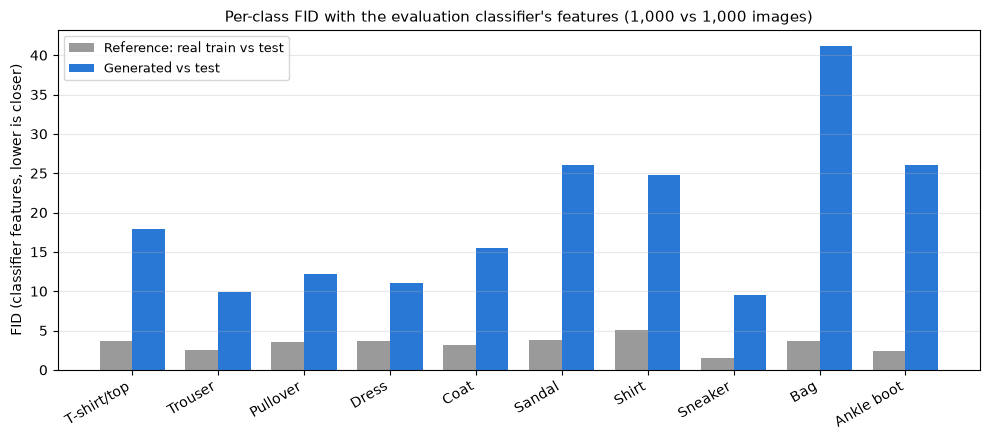

In [242]:
# 22-1. 기준값용 학습 이미지 뽑기 (클래스당 1,000장, 시드 고정)
#  - train_dataset_gan : '11. 전처리: 픽셀 값 변환'의 -1~1 학습 데이터셋
REF_SEED = 42
ref_rng = torch.Generator().manual_seed(REF_SEED)
train_targets = train_dataset_gan.targets   # (60000,) 학습 이미지의 클래스 번호

ref_idx = []
for c in range(num_classes):
    class_idx = torch.nonzero(train_targets == c).squeeze(1)                            # 클래스 c인 이미지 위치
    picked = torch.randperm(len(class_idx), generator=ref_rng)[:EVAL_PER_CLASS]          # 그중 1,000개를 무작위로
    ref_idx.append(class_idx[picked])
ref_idx = torch.cat(ref_idx)

train_ref_images = torch.stack([train_dataset_gan[i][0] for i in ref_idx.tolist()])   # (10000, 1, 28, 28), -1~1
train_ref_labels = train_targets[ref_idx]                                             # (10000,)


# 22-2. 특징 뽑기 (분류기의 마지막 바로 앞 층, 숫자 128개)
@torch.no_grad()   # 계산만 하므로 학습용 계산 기록은 남기지 않음
def extract_features_all(images, batch_size=1000):
    """이미지 묶음 (N, 1, 28, 28)을 받아 특징 (N, 128)을 CPU float64 텐서로 돌려줍니다."""
    classifier.eval()
    feats = []
    for start in range(0, len(images), batch_size):
        feats.append(classifier.extract_features(images[start:start + batch_size].to(device)).cpu())
    return torch.cat(feats).double()   # 공분산·고윳값 계산의 정밀도를 위해 float64


feat_test = extract_features_all(test_images_gan)
feat_gen = extract_features_all(gen_images)
feat_train = extract_features_all(train_ref_images)
print(f"특징 shape : 테스트 {tuple(feat_test.shape)}, 생성 {tuple(feat_gen.shape)}, 학습(기준) {tuple(feat_train.shape)}")


# 22-3. FID 계산 함수
#  - FID = |평균 차이|^2 + Tr(Σa + Σb - 2 (Σa Σb)^(1/2))
#  - Tr((Σa Σb)^(1/2)) = Σa Σb의 고윳값에 제곱근을 씌워 더한 값
def compute_fid(feat_a, feat_b):
    """두 특징 묶음 (N, d)의 FID를 계산합니다."""
    mu_a, mu_b = feat_a.mean(dim=0), feat_b.mean(dim=0)
    cov_a, cov_b = torch.cov(feat_a.T), torch.cov(feat_b.T)   # (d, d) 공분산 (torch.cov는 행 = 변수)
    eigvals = torch.linalg.eigvals(cov_a @ cov_b).real.clamp(min=0)   # 계산 오차로 생기는 아주 작은 음수·허수 부분 제거
    fid_value = (mu_a - mu_b).pow(2).sum() + cov_a.trace() + cov_b.trace() - 2 * eigvals.sqrt().sum()
    return fid_value.item()


# 22-4. 계산 확인: 같은 묶음끼리의 FID는 0에 가까워야 함
print(f"\n계산 확인 - 테스트 vs 테스트 FID : {compute_fid(feat_test, feat_test):.6f}")


# 22-5. 전체 FID (10,000장 vs 10,000장)
fid_ref_all = compute_fid(feat_train, feat_test)
fid_gen_all = compute_fid(feat_gen, feat_test)
print("\n전체 FID (10,000장 vs 10,000장)")
print(f"  기준값 (학습 vs 테스트) : {fid_ref_all:.2f}")
print(f"  생성 vs 테스트 : {fid_gen_all:.2f} → 기준값의 {fid_gen_all / fid_ref_all:.1f}배")


# 22-6. 클래스별 FID (1,000장 vs 1,000장)
fid_ref_per_class, fid_gen_per_class = [], []
print("\n클래스별 FID (1,000장 vs 1,000장)")
for c in range(num_classes):
    fid_ref_per_class.append(compute_fid(feat_train[train_ref_labels == c], feat_test[test_labels_gan == c]))
    fid_gen_per_class.append(compute_fid(feat_gen[gen_labels == c], feat_test[test_labels_gan == c]))
    ratio = fid_gen_per_class[c] / fid_ref_per_class[c]
    print(f"  {class_names[c]:<12} : 기준값 {fid_ref_per_class[c]:7.2f} | 생성 {fid_gen_per_class[c]:7.2f} | 기준값의 {ratio:4.1f}배")


# 22-7. 그림: 클래스별 FID (기준값 회색, 생성 #2a78d6)
x = np.arange(num_classes)
bar_width = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - bar_width / 2, fid_ref_per_class, bar_width, color="#9a9a9a", label="Reference: real train vs test")
ax.bar(x + bar_width / 2, fid_gen_per_class, bar_width, color="#2a78d6", label="Generated vs test")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=30, ha="right")
ax.set_ylabel("FID (classifier features, lower is closer)")
ax.set_title("Per-class FID with the evaluation classifier's features (1,000 vs 1,000 images)", fontsize=11)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 결과
- 테스트 vs 테스트 FID가 0에 가까운가?
  - 0.000000으로, 같은 묶음끼리의 FID가 0입니다.
- 전체 FID는 기준값의 몇 배인가?
  - 기준값(학습 vs 테스트)은 0.50, 생성 vs 테스트는 6.91로, 기준값의 13.7배입니다.
- 기준값 대비 FID가 가장 큰 클래스는 어디인가? Sandal, Bag은 어떤가?

| 클래스 | 기준값 (학습 vs 테스트) | 생성 vs 테스트 | 기준값의 몇 배 |
| --- | --- | --- | --- |
| Bag | 3.66 | 41.16 | 11.2배 |
| Ankle boot | 2.38 | 26.08 | 11.0배 |
| Sandal | 3.79 | 26.02 | 6.9배 |
| Sneaker | 1.54 | 9.53 | 6.2배 |
| T-shirt/top | 3.62 | 17.89 | 4.9배 |
| Coat | 3.14 | 15.45 | 4.9배 |
| Shirt | 5.07 | 24.80 | 4.9배 |
| Trouser | 2.51 | 9.96 | 4.0배 |
| Pullover | 3.53 | 12.25 | 3.5배 |
| Dress | 3.66 | 10.99 | 3.0배 |

  - 10개 클래스 모두 생성 이미지의 FID가 기준값보다 큽니다(3.0~11.2배).
  - 기준값 대비 가장 큰 클래스는 Bag(11.2배)과 Ankle boot(11.0배)이고, 그다음이 Sandal(6.9배), Sneaker(6.2배)입니다. 가방과 신발 네 클래스가 상위 4개입니다.
  - 그림에서도 Bag 막대(41.16)가 가장 높고, Ankle boot, Sandal, Shirt가 약 25~26으로 그다음입니다.
- 정확도가 진짜보다 높았던 Pullover, Dress, Ankle boot의 FID는 기준값과 비교해 어떤가?
  - Pullover는 3.5배, Dress는 3.0배로 10개 클래스 중 가장 작은 편입니다.
  - Ankle boot는 11.0배로 두 번째로 큽니다.

### 해석
- FID 계산 확인: 같은 묶음끼리의 FID가 0이므로, FID 계산이 맞게 되어 있습니다.
- 모든 클래스에서 생성 이미지는 진짜 이미지끼리보다 테스트 이미지와 멀리 떨어져 있습니다. '21. 정량 평가: 분류기 정확도'에서는 진짜와 거의 같았지만, 특징이 퍼져 있는 모양까지 보면 아직 진짜와 차이가 있습니다. 분류기 정확도는 "어느 클래스로 보이는가"만 보고, FID는 "진짜와 얼마나 비슷하게 퍼져 있는가"까지 보기 때문입니다.
- Bag, Ankle boot, Sandal은 정확도가 98% 이상이었는데도 FID 배수는 가장 큰 편입니다. 다른 클래스와 헷갈리지는 않지만, 진짜 이미지들과 생긴 모양이나 퍼진 정도는 가장 많이 다르다는 뜻입니다. Sandal은 '18. 학습 결과 확인'에서 눈으로 볼 때 가장 알아보기 어려웠던 것과 같은 방향의 결과입니다.
- '9. EDA 정리'에서 볼 점으로 정한 Sandal과 Bag은 둘 다 기준값 대비 FID가 큰 편이어서, 진짜와의 차이가 큽니다.
  - 다만 FID는 숫자 하나라서, 이 차이가 한 가지 모양을 반복해서(다양성이 부족해서) 생긴 것인지, 모양 자체가 진짜와 달라서 생긴 것인지는 이 결과만으로 구별할 수 없습니다.
  - '18. 학습 결과 확인'의 그림 3에서 Bag 10장은 여러 모양이었으므로, 적어도 한 가지 모양만 반복하는 극단적인 경우는 아니었습니다.
- '21. 정량 평가: 분류기 정확도'에서 정확도가 진짜보다 높았던 세 클래스
  - Pullover와 Dress는 FID 배수가 가장 작은 편이라, 전형적인 모양에 몰렸다는 신호는 보이지 않습니다.
  - Ankle boot는 11.0배로 커서, 전형적인 모양에 몰렸을 가능성을 배제할 수 없습니다. '18. 학습 결과 확인'의 그림 3에서 Ankle boot 10장이 모두 밝은 편이었으므로, 밝기가 한쪽으로 몰렸는지 '23. 정량 평가: 밝기 분포'에서 확인합니다.
- Shirt와 Coat는 정확도가 가장 많이 낮았지만 FID 배수는 4.9배로 중간입니다. 두 클래스의 주된 문제는 진짜와 멀리 떨어진 것보다, Pullover 쪽으로 헷갈리는 모양이 많은 것으로 볼 수 있습니다.
- Sneaker는 생성 FID(9.53)가 낮은 편이지만, 기준값(1.54)이 10개 클래스 중 가장 작아 배수가 6.2배로 커졌습니다. 배수는 기준값이 작은 클래스에서 크게 나온다는 점을 함께 봐야 합니다.

### 한계
- 직접 학습한 분류기의 특징으로 계산했기 때문에, 분류기가 클래스를 구별할 때 쓰지 않는 세부 모양(질감, 작은 무늬 등)의 차이는 덜 반영될 수 있습니다.
- 기준값과 생성 FID 모두 한 번 뽑은 이미지로 계산했습니다. 다시 뽑았을 때 값이 얼마나 달라지는지는 확인하지 않았습니다.
- FID가 평균의 차이 때문에 큰지, 퍼진 정도의 차이 때문에 큰지는 나누어 보지 않았습니다.
- 논문이나 다른 팀의 FID(Inception-v3 특징)와는 숫자를 비교할 수 없습니다.

## 23. 정량 평가: 밝기 분포

생성 이미지와 테스트 이미지의 밝기를 클래스별로 비교합니다.

### 목적
- '9. EDA 정리'에서 볼 점으로 정한 두 가지를 확인합니다.
  - Shirt, T-shirt/top, Pullover처럼 클래스 안에서 밝기가 다양한 클래스에서, 생성 이미지의 밝기가 한쪽으로 몰리지 않는지
  - Pullover는 학습/테스트의 밝기 중앙값 차이(−5.5)가 다른 클래스보다 크다는 점
- '22. 정량 평가: FID'에서 FID 배수가 컸던 Ankle boot의 밝기가 한쪽으로 몰려 있는지 확인합니다. '18. 학습 결과 확인'의 그림 3에서 Ankle boot 10장은 모두 밝은 편이었습니다.
- FID는 여러 성질을 숫자 하나로 합친 값입니다. 밝기라는 한 가지 성질만 떼어 보면, 생성 이미지가 진짜와 어떤 점에서 다른지 더 구체적으로 알 수 있습니다.

### 방법
- 밝기 계산은 '8. 학습/테스트 밝기 비교'와 같습니다. 이미지마다 물건 부분(0이 아닌 픽셀)의 평균 밝기(0~255)를 구합니다.
- 생성 이미지 변환: '13. 전처리: 되돌려서 눈으로 확인'의 `denormalize`로 0~1로 되돌린 뒤 255를 곱하고 반올림해, 진짜 이미지와 같은 0~255 정수로 만듭니다. 반올림해서 0이 된 픽셀은 배경으로 봅니다.
- 테스트 이미지 쪽은 '8. 학습/테스트 밝기 비교'에서 원본 0~255 이미지로 계산한 `test_brightness`를 그대로 씁니다.
- 확인 1, 물건 크기: '6. 이상치 확인'의 0이 아닌 픽셀 수를 생성과 테스트로 비교합니다.
  - 생성 이미지 쪽이 크게 많으면, 배경에 있는 아주 흐린 점이 물건으로 세어진 것입니다.
  - 이 경우 생성 이미지의 밝기는 실제보다 낮게 계산되었을 수 있습니다.
- 확인 2, 밝기: 클래스별로 밝기 중앙값(테스트, 생성, 차이)과 퍼진 정도(IQR)를 출력합니다.
  - 중앙값은 '8. 학습/테스트 밝기 비교'처럼 표에 보이는 자릿수로 먼저 반올림한 뒤 차이를 계산합니다.
  - IQR: 밝기를 작은 순서로 줄 세웠을 때 가운데 50%가 들어가는 범위의 폭입니다(75% 지점 − 25% 지점).
  - 생성 이미지의 IQR이 테스트보다 많이 작으면, 생성 이미지의 밝기가 한쪽으로 몰려 있다는 뜻입니다.
- 그림: '8. 학습/테스트 밝기 비교'와 같은 모양(2줄 × 5칸, 칸마다 한 클래스, 밝기 8 단위 구간, 세로축은 비율 %)입니다.
  - 생성은 색칠한 면(#2a78d6), 테스트는 선(#eb6834)입니다. '8. 학습/테스트 밝기 비교'에서 색칠한 면은 학습이었지만, 여기서는 생성입니다.
  - 두 모양이 겹칠수록 밝기 분포가 비슷하다는 뜻입니다.
- 통계 검정은 하지 않고, 숫자와 그림으로 비교합니다.

### 확인할 점
- 생성 이미지의 0이 아닌 픽셀 수가 테스트와 비슷한가? (배경의 흐린 점이 물건으로 세어졌는지)
- 클래스별 밝기 중앙값이 테스트와 비슷한가? Pullover는 어떤가?
- Shirt, T-shirt/top, Pullover에서 생성 이미지의 IQR이 테스트보다 크게 작지 않은가?
- Ankle boot의 밝기가 테스트보다 한쪽(밝은 쪽)으로 몰려 있는가?

0이 아닌 픽셀이 하나도 없는 생성 이미지 : 0장 (밝기 계산에서 제외)

[확인 1] 0이 아닌 픽셀 수의 중앙값 (물건 크기)
No  Class           Test     Gen    Diff
----------------------------------------
 0  T-shirt/top    470.0   461.0    -9.0
 1  Trouser        262.0   278.0   +16.0
 2  Pullover       506.0   527.0   +21.0
 3  Dress          336.0   335.0    -1.0
 4  Coat           482.0   488.0    +6.0
 5  Sandal         248.5   279.0   +30.5
 6  Shirt          498.0   520.0   +22.0
 7  Sneaker        257.0   277.0   +20.0
 8  Bag            462.0   486.0   +24.0
 9  Ankle boot     372.0   379.0    +7.0
----------------------------------------
    All            403.0   407.5    +4.5

[확인 2] 물건 부분의 평균 밝기 - 중앙값과 IQR (Diff = Gen - Test)
No  Class           Test     Gen    Diff  TestIQR   GenIQR
----------------------------------------------------------
 0  T-shirt/top    149.7   143.7    -6.0     69.4     76.5
 1  Trouser        168.9   154.8   -14.1     47.6     44.5
 2  Pullover       154.0   148.4    -5.6     81.0     79.6
 3  D

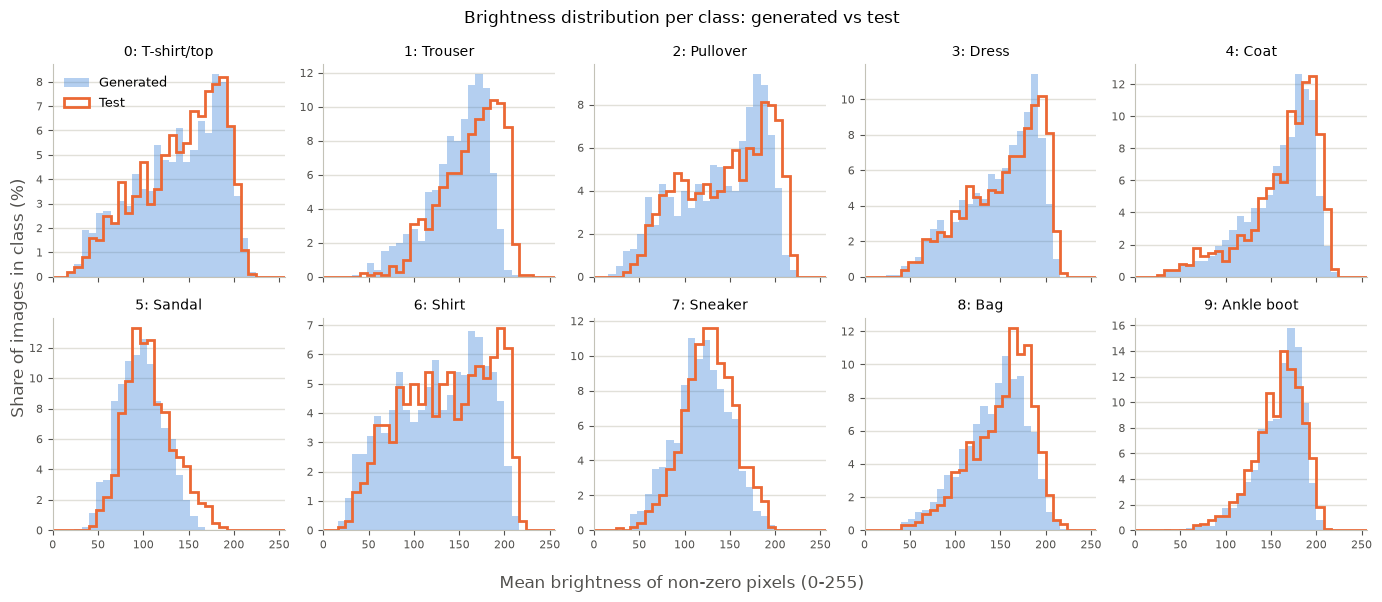

In [243]:
# 23-1. 생성 이미지를 진짜 이미지와 같은 0~255 정수로 바꾸기
#  - denormalize : -1~1 → 0~1 ('13. 전처리: 되돌려서 눈으로 확인') → x 255 → 반올림 → 0~255 정수
#  - 반올림해서 0이 된 픽셀을 배경으로 봄 ('8. 학습/테스트 밝기 비교'와 같은 기준)
gen_u8 = (denormalize(gen_images) * 255).round().clamp(0, 255).to(torch.uint8).squeeze(1).numpy()   # (10000, 28, 28)
gen_labels_np = gen_labels.numpy()

#  테스트 쪽은 앞 섹션에서 원본 0~255 이미지로 계산한 값을 그대로 사용 (모두 numpy)
#  - test_labels     : '4. 클래스(옷 종류)별 이미지 개수 확인'의 테스트 라벨
#  - test_nonzero    : '6. 이상치 확인'의 이미지마다 0이 아닌 픽셀 수
#  - test_brightness : '8. 학습/테스트 밝기 비교'의 이미지마다 물건 부분의 평균 밝기


# 23-2. 확인 1: 물건 크기 (0이 아닌 픽셀 수) 비교
gen_nonzero = (gen_u8 > 0).sum(axis=(1, 2))
has_object = gen_nonzero > 0   # 0이 아닌 픽셀이 하나라도 있는 생성 이미지
print(f"0이 아닌 픽셀이 하나도 없는 생성 이미지 : {(~has_object).sum()}장 (밝기 계산에서 제외)")

print("\n[확인 1] 0이 아닌 픽셀 수의 중앙값 (물건 크기)")
print(f"{'No':>2}  {'Class':<12} {'Test':>7} {'Gen':>7} {'Diff':>7}")
print("-" * 40)
for i, name in enumerate(class_names):
    test_median = round(float(np.median(test_nonzero[test_labels == i])), 1)
    gen_median = round(float(np.median(gen_nonzero[gen_labels_np == i])), 1)
    print(f"{i:>2}  {name:<12} {test_median:>7.1f} {gen_median:>7.1f} {gen_median - test_median:>+7.1f}")
print("-" * 40)
test_all = round(float(np.median(test_nonzero)), 1)
gen_all = round(float(np.median(gen_nonzero)), 1)
print(f"{'':>2}  {'All':<12} {test_all:>7.1f} {gen_all:>7.1f} {gen_all - test_all:>+7.1f}")


# 23-3. 확인 2: 물건 부분의 평균 밝기 (중앙값, IQR)
#  - 생성 이미지 밝기 = 픽셀 값의 합 ÷ 0이 아닌 픽셀 수 (배경은 0이라 합에 영향 없음)
#  - IQR = 75% 지점 - 25% 지점 (가운데 50%가 들어가는 범위의 폭)
gen_brightness = np.full(len(gen_u8), np.nan)   # 물건이 없는 이미지는 빈 값(nan)으로 남김
gen_brightness[has_object] = gen_u8[has_object].sum(axis=(1, 2)) / gen_nonzero[has_object]


def iqr(values):
    """값들의 IQR(75% 지점 - 25% 지점)을 돌려줍니다."""
    return float(np.percentile(values, 75) - np.percentile(values, 25))


print("\n[확인 2] 물건 부분의 평균 밝기 - 중앙값과 IQR (Diff = Gen - Test)")
print(f"{'No':>2}  {'Class':<12} {'Test':>7} {'Gen':>7} {'Diff':>7} {'TestIQR':>8} {'GenIQR':>8}")
print("-" * 58)
for i, name in enumerate(class_names):
    test_vals = test_brightness[test_labels == i]
    gen_vals = gen_brightness[(gen_labels_np == i) & has_object]
    test_median, gen_median = round(float(np.median(test_vals)), 1), round(float(np.median(gen_vals)), 1)
    print(f"{i:>2}  {name:<12} {test_median:>7.1f} {gen_median:>7.1f} {gen_median - test_median:>+7.1f} "
          f"{iqr(test_vals):>8.1f} {iqr(gen_vals):>8.1f}")
print("-" * 58)
test_vals, gen_vals = test_brightness, gen_brightness[has_object]
test_all, gen_all = round(float(np.median(test_vals)), 1), round(float(np.median(gen_vals)), 1)
print(f"{'':>2}  {'All':<12} {test_all:>7.1f} {gen_all:>7.1f} {gen_all - test_all:>+7.1f} "
      f"{iqr(test_vals):>8.1f} {iqr(gen_vals):>8.1f}")


# 23-4. 그림: 클래스마다 밝기 분포를 생성/테스트 겹쳐 그리기 (2줄 x 5칸)
#  - '8. 학습/테스트 밝기 비교'와 같은 구간과 모양, 세로축은 비율(%)
#  - 생성: 색칠한 면(#2a78d6), 테스트: 선(#eb6834)
BINS = np.arange(0, 256 + 8, 8)   # 구간 경계: 0, 8, ..., 256

fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True)
for class_idx, ax in enumerate(axes.flat):
    gen_vals = gen_brightness[(gen_labels_np == class_idx) & has_object]
    test_vals = test_brightness[test_labels == class_idx]

    ax.hist(gen_vals, bins=BINS, weights=np.full(len(gen_vals), 100 / len(gen_vals)),
            histtype="stepfilled", color="#2a78d6", alpha=0.35, label="Generated")   # 생성: 색칠한 면
    ax.hist(test_vals, bins=BINS, weights=np.full(len(test_vals), 100 / len(test_vals)),
            histtype="step", color="#eb6834", linewidth=2, label="Test")             # 테스트: 선

    ax.set_title(f"{class_idx}: {class_names[class_idx]}", fontsize=10)
    ax.set_xlim(0, 256)
    ax.grid(axis="y", color="#e1e0d9", linewidth=1)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8)

axes.flat[0].legend(frameon=False, fontsize=9)
fig.supxlabel("Mean brightness of non-zero pixels (0-255)", color="#52514e")
fig.supylabel("Share of images in class (%)", color="#52514e")
fig.suptitle("Brightness distribution per class: generated vs test", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
- 생성 이미지의 0이 아닌 픽셀 수가 테스트와 비슷한가?
  - 물건 픽셀이 하나도 없는 생성 이미지는 0장이라, 모든 생성 이미지의 밝기를 계산했습니다.
  - 전체 중앙값은 테스트 403.0, 생성 407.5로 4.5개(약 1.1%) 차이입니다.
  - 클래스별로는 생성 쪽이 더 많은 클래스가 대부분입니다. 테스트 대비 가장 많이 늘어난 것은 Sandal(+30.5개, 약 12.3%), Sneaker(+20.0개, 약 7.8%), Trouser(+16.0개, 약 6.1%)입니다. 나머지 클래스는 −1.9% ~ +5.2% 사이입니다.
- 클래스별 밝기 중앙값이 테스트와 비슷한가? Pullover는 어떤가?
  - 전체 중앙값은 테스트 149.7, 생성 143.0으로, 생성이 6.7 어둡습니다.
  - Ankle boot(+2.8)를 빼면 9개 클래스에서 생성이 더 어둡고, 차이는 −5.1(Coat) ~ −14.1(Trouser)입니다. 차이가 큰 클래스는 Trouser(−14.1)와 Bag(−10.8)입니다.
  - Pullover는 −5.6으로, 다른 클래스의 차이와 비슷한 크기입니다.
  - 그림에서 10개 클래스 모두 생성(면)과 테스트(선)의 전체적인 모양은 비슷하고, 생성 쪽이 조금 왼쪽(어두운 쪽)에 있습니다.
  - Trouser, Pullover, Dress, Coat, Shirt, Bag은 테스트 선이 약 200~215까지 이어지는데, 생성 면은 그보다 조금 앞에서 줄어듭니다. 가장 밝은 이미지의 비율이 생성 쪽에서 적습니다.
- Shirt, T-shirt/top, Pullover에서 생성 이미지의 IQR이 테스트보다 크게 작지 않은가?

| 클래스 | 테스트 IQR | 생성 IQR |
| --- | --- | --- |
| Shirt | 83.0 | 81.7 |
| Pullover | 81.0 | 79.6 |
| T-shirt/top | 69.4 | 76.5 |

  - 세 클래스 모두 생성 IQR이 테스트와 비슷하거나 더 큽니다. 테스트와 생성 모두에서 이 세 클래스의 IQR이 10개 클래스 중 가장 큽니다.
  - 다른 클래스도 생성 IQR과 테스트 IQR의 차이는 −4.1(Dress) ~ +3.4(Coat)입니다.
- Ankle boot의 밝기가 테스트보다 한쪽(밝은 쪽)으로 몰려 있는가?
  - Ankle boot는 생성이 테스트보다 밝은 유일한 클래스이지만, 중앙값 차이는 +2.8입니다.
  - IQR은 테스트 35.0, 생성 34.3으로 거의 같고, 그림에서도 두 모양이 대부분 겹칩니다.

### 해석
- '9. EDA 정리'에서 볼 점으로 정한 "밝기가 한쪽으로 몰리지 않는지"에 대해서는, 몰리지 않았다고 볼 수 있습니다. 밝기가 다양한 Shirt, T-shirt/top, Pullover에서도 생성 이미지의 밝기는 테스트와 비슷한 폭으로 퍼져 있습니다.
- Pullover의 학습/테스트 중앙값 차이(−5.5, '8. 학습/테스트 밝기 비교')는 이번 비교에서 Pullover만 특별히 어긋나게 만들지 않았습니다. 생성과 테스트의 차이(−5.6)가 다른 클래스와 비슷한 크기입니다.
- Ankle boot는 밝기가 테스트와 거의 같게 퍼져 있습니다. '18. 학습 결과 확인'에서 10장이 모두 밝아 보였던 것은, 진짜 Ankle boot도 원래 밝은 편(테스트 중앙값 162.4)이기 때문으로 볼 수 있습니다. 따라서 '22. 정량 평가: FID'에서 Ankle boot의 FID 배수가 컸던 이유를 밝기로 설명하기는 어렵습니다.
- 생성 이미지는 전체적으로 테스트보다 조금 어둡고(중앙값 −6.7), 가장 밝은 쪽 이미지가 적습니다. 다만 이 중 일부는 측정 방식의 영향일 수 있습니다.
  - 확인 1에서 생성 이미지의 0이 아닌 픽셀 수가 대부분의 클래스에서 조금 더 많았습니다.
  - 늘어난 픽셀이 배경의 흐린 점이라면, 흐린 픽셀이 물건으로 세어져 평균 밝기가 낮게 계산됩니다.
  - 픽셀 수가 가장 많이 늘어난 Sandal, Sneaker, Trouser 중 Trouser는 밝기 차이도 가장 큽니다(−14.1). 하지만 Sandal(−7.1), Sneaker(−7.8)는 다른 클래스와 비슷해서, 픽셀 수 증가만으로 밝기 차이를 모두 설명할 수는 없습니다.
  - 늘어난 픽셀이 배경의 흐린 점인지, 물건이 조금 더 크게 만들어진 것인지는 이 출력만으로 구별할 수 없습니다.

### 한계
- A 방법(0이 아닌 픽셀을 물건으로 봄)을 썼기 때문에, 생성 이미지 배경의 흐린 점이 밝기 계산에 섞였는지 분리하지 못했습니다.
- 밝기라는 한 가지 성질만 비교했고, 이미지 안에서 밝기가 어떻게 배치되는지(무늬 등)는 반영되지 않습니다.
- 통계 검정 없이 숫자와 그림으로 비교했습니다.

## 24. 정성 평가

정량 평가('21. 정량 평가: 분류기 정확도' ~ '23. 정량 평가: 밝기 분포')에서 문제가 보인 곳을 골라, 생성 이미지를 진짜 테스트 이미지와 함께 눈으로 확인합니다.

### 목적
- 숫자로 드러난 특징이 실제 이미지에서 어떻게 보이는지 확인합니다. 숫자로 문제가 보인 곳만 골라서 보므로, 모든 이미지를 보지 않아도 됩니다.
- '18. 학습 결과 확인'에서는 생성 이미지만 봤습니다. 이번에는 진짜 테스트 이미지와 나란히 놓고 비교합니다.

### 방법
| 그림 | 보여줄 이미지 | 확인할 것 |
| --- | --- | --- |
| 1. 테스트 vs 생성 | 클래스마다 테스트 5장과 생성 5장 (무작위) | 전체적으로 진짜와 비슷해 보이는지 |
| 2. Pullover로 잘못 분류된 생성 이미지 | 생성한 Shirt, Coat 중 분류기가 Pullover로 예측한 이미지 8장씩 (Pullover 확률이 높은 순)과, 비교용 진짜 Pullover 테스트 8장 (무작위) | '21. 정량 평가: 분류기 정확도'에서 Shirt, Coat의 정확도가 가장 많이 떨어진 원인 |
| 3. FID 배수가 큰 클래스 | Bag, Ankle boot, Sandal의 테스트 10장과 생성 10장 (무작위) | '22. 정량 평가: FID'에서 분류는 잘 되는데 FID가 컸던 이유가 모양 차이인지, 다양성 차이인지 |

- 생성 이미지는 '20. 평가 준비: 평가용 생성 이미지'의 10,000장에서, 테스트 이미지는 '19. 평가 준비: 평가용 분류기'의 `test_images_gan`에서 고릅니다.
- 무작위로 고를 때는 시드 42로 정한 별도의 난수 생성기를 써서, 다시 실행해도 같은 이미지가 나오게 합니다.
- 그림 2의 생성 이미지는 Pullover 확률이 가장 높은 이미지, 즉 분류기가 가장 Pullover 같다고 본 이미지들입니다.
  - 잘못 분류된 이미지 중 가장 뚜렷한 경우라서, 잘못 분류된 이미지 전체의 평균적인 모습은 아닙니다.
  - 각 이미지 위의 P는 분류기가 준 Pullover 확률(0~1)입니다.
  - 잘못 분류된 이미지가 모두 몇 장인지도 출력합니다. '21. 정량 평가: 분류기 정확도'의 혼동 행렬 비율(Shirt → Pullover 9.4%, Coat → Pullover 7.4%)과 맞는지 확인할 수 있습니다.
- 모든 판단은 눈으로 합니다.

### 확인할 점
- 그림 1: 클래스마다 생성 이미지가 테스트 이미지와 비슷해 보이는가? '23. 정량 평가: 밝기 분포'에서 본 것처럼 생성 이미지가 조금 어두워 보이는가?
- 그림 2: Pullover로 잘못 분류된 Shirt, Coat 생성 이미지는 진짜 Pullover와 어떤 점이 닮았는가? 원래 클래스의 특징(단추, 여밈, 깃, 무늬 등)이 보이는가?
- 그림 3: Bag, Ankle boot, Sandal에서 생성 이미지와 테스트 이미지는 모양, 다양성, 선명함 중 어디가 다른가?

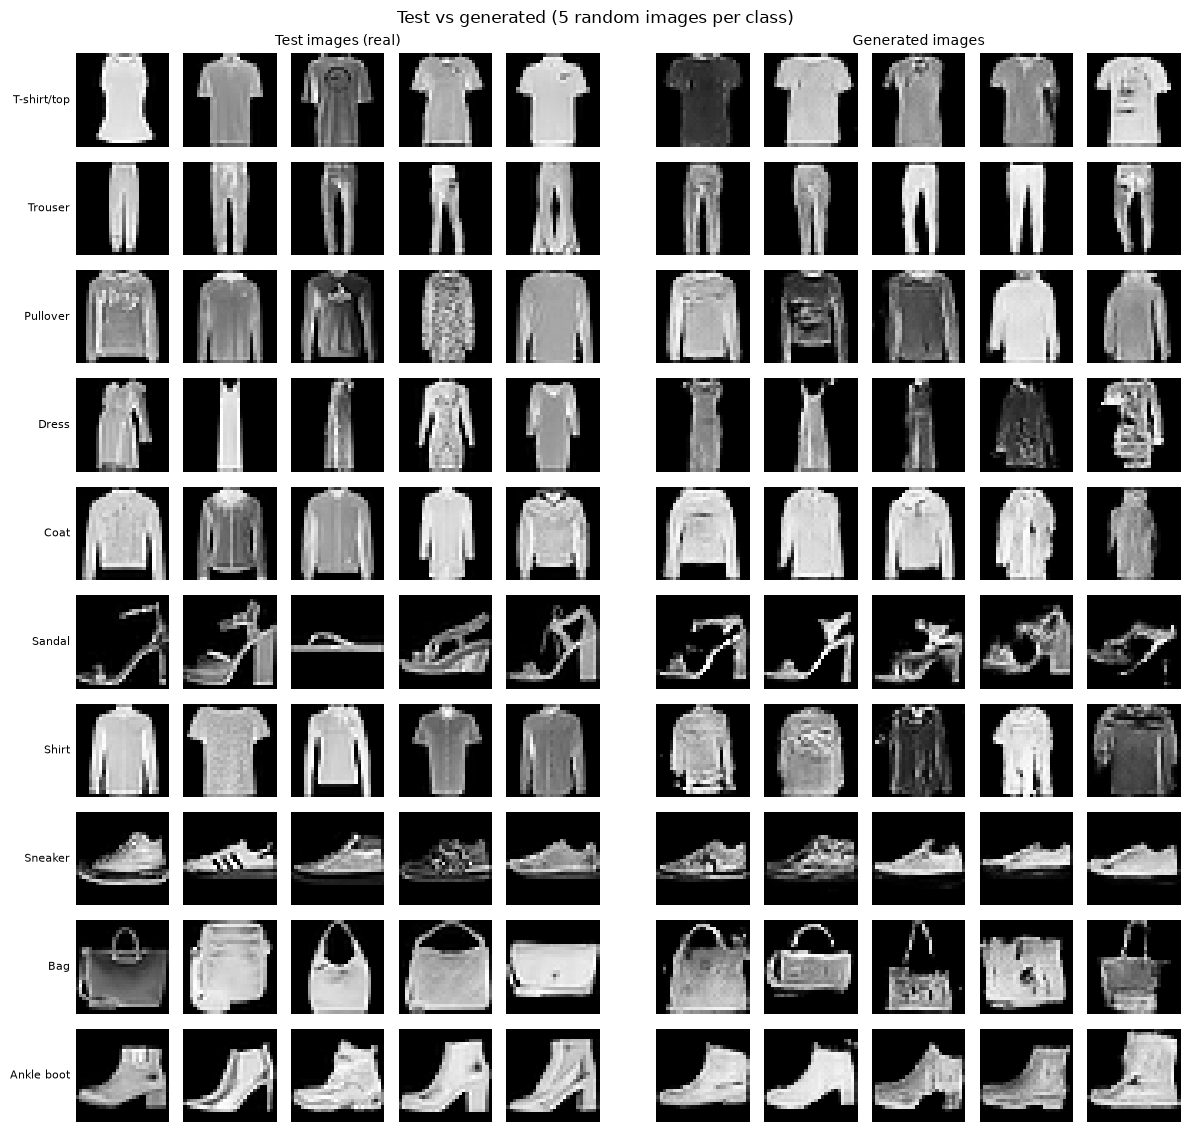

생성한 Shirt 1,000장 중 Pullover로 예측된 이미지 : 94장 (9.4%) → Pullover 확률이 높은 8장 표시
생성한 Coat 1,000장 중 Pullover로 예측된 이미지 : 74장 (7.4%) → Pullover 확률이 높은 8장 표시


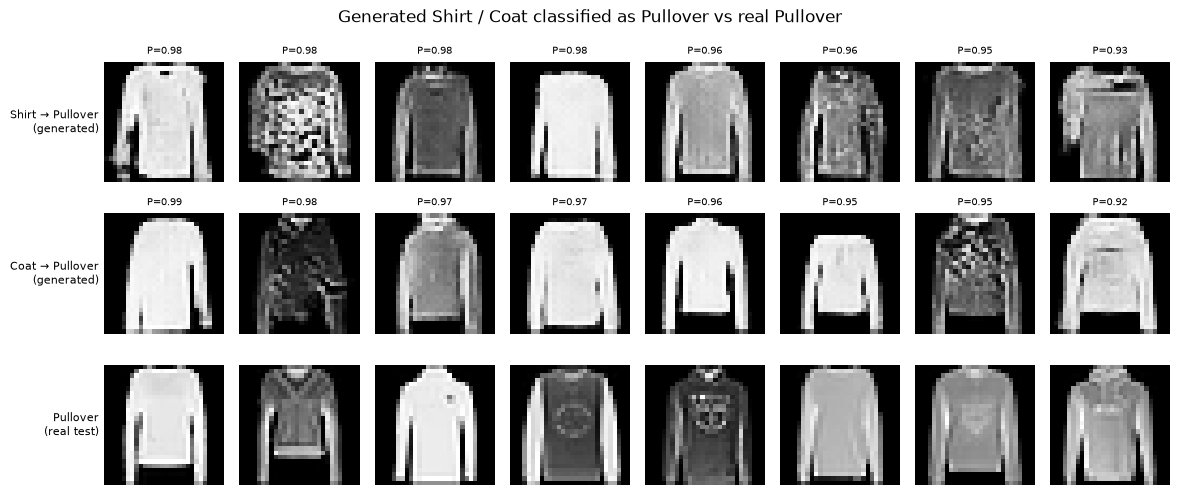

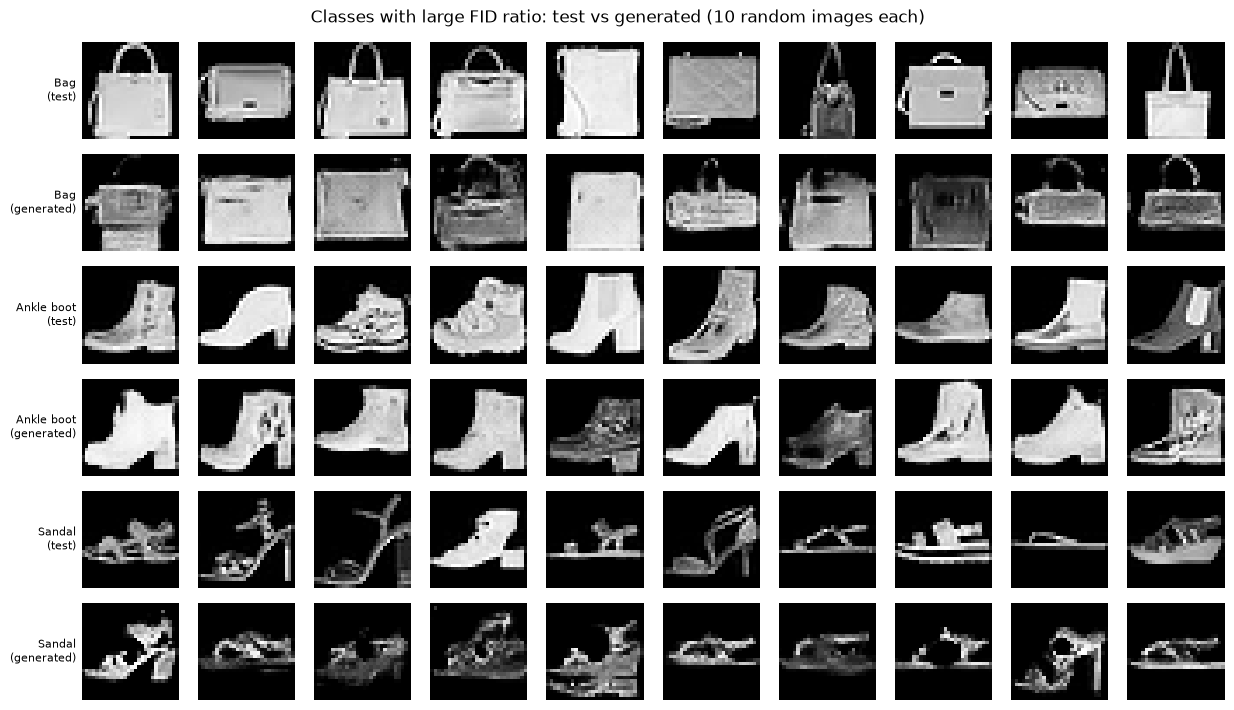

In [244]:
# 24-1. 준비
#  - gen_images, gen_labels           : '20. 평가 준비: 평가용 생성 이미지'의 10,000장 (-1~1)과 요청한 클래스
#  - test_images_gan, test_labels_gan : '19. 평가 준비: 평가용 분류기'의 테스트 이미지 (-1~1)와 클래스
#  - gen_pred                         : '21. 정량 평가: 분류기 정확도'에서 분류기가 예측한 클래스
QUAL_SEED = 42
qual_rng = torch.Generator().manual_seed(QUAL_SEED)   # 무작위로 고를 때 쓰는 별도의 난수 생성기
gen_probs = predict_probs(gen_images)                  # (10000, 10) 클래스별 확률 (그림 2의 Pullover 확률용)


def pick_random(labels, class_idx, k):
    """labels에서 class_idx인 이미지 위치 중 k개를 무작위로 골라 돌려줍니다."""
    idx = torch.nonzero(labels == class_idx).squeeze(1)
    return idx[torch.randperm(len(idx), generator=qual_rng)[:k]]


def show_image(ax, image):
    """(1, 28, 28), -1~1 이미지 한 장을 0~1로 되돌려 흑백으로 그립니다."""
    ax.imshow(denormalize(image[0]).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


# 24-2. 그림 1: 클래스마다 테스트 5장 | 생성 5장
#  - 가운데에 좁은 빈 칸을 두어 테스트와 생성을 나눔
N_SHOW = 5
fig, axes = plt.subplots(num_classes, 2 * N_SHOW + 1, figsize=(12, num_classes * 1.15),
                         gridspec_kw={"width_ratios": [1] * N_SHOW + [0.3] + [1] * N_SHOW})
for c in range(num_classes):
    test_idx = pick_random(test_labels_gan, c, N_SHOW)
    gen_idx = pick_random(gen_labels, c, N_SHOW)
    for k in range(N_SHOW):
        show_image(axes[c, k], test_images_gan[test_idx[k]])               # 왼쪽: 테스트
        show_image(axes[c, N_SHOW + 1 + k], gen_images[gen_idx[k]])        # 오른쪽: 생성
    axes[c, N_SHOW].axis("off")                                            # 가운데 빈 칸
    axes[c, 0].set_ylabel(class_names[c], fontsize=8, rotation=0, ha="right", va="center")
axes[0, N_SHOW // 2].set_title("Test images (real)", fontsize=10)
axes[0, N_SHOW + 1 + N_SHOW // 2].set_title("Generated images", fontsize=10)
fig.suptitle("Test vs generated (5 random images per class)", fontsize=12)
plt.tight_layout()
plt.show()


# 24-3. 그림 2: Pullover로 잘못 분류된 생성 Shirt, Coat (Pullover 확률이 높은 순) + 진짜 Pullover
N_WRONG = 8
pullover = class_names.index("Pullover")
rows = []   # (줄 이름, 이미지 묶음, 보여줄 위치, Pullover 확률)
for name in ["Shirt", "Coat"]:
    c = class_names.index(name)
    wrong_idx = torch.nonzero((gen_labels == c) & (gen_pred == pullover)).squeeze(1)    # 요청 c인데 Pullover로 예측
    order = gen_probs[wrong_idx, pullover].argsort(descending=True)                      # Pullover 확률이 높은 순서
    chosen = wrong_idx[order[:N_WRONG]]
    print(f"생성한 {name} {EVAL_PER_CLASS:,}장 중 Pullover로 예측된 이미지 : {len(wrong_idx)}장 "
          f"({len(wrong_idx) / EVAL_PER_CLASS:.1%}) → Pullover 확률이 높은 {len(chosen)}장 표시")
    rows.append((f"{name} → Pullover\n(generated)", gen_images, chosen, gen_probs[chosen, pullover]))
rows.append(("Pullover\n(real test)", test_images_gan, pick_random(test_labels_gan, pullover, N_WRONG), None))

fig, axes = plt.subplots(len(rows), N_WRONG, figsize=(N_WRONG * 1.3 + 1.5, len(rows) * 1.7))
for r, (label, images, idx, probs) in enumerate(rows):
    for k in range(N_WRONG):
        if k < len(idx):
            show_image(axes[r, k], images[idx[k]])
            if probs is not None:
                axes[r, k].set_title(f"P={probs[k]:.2f}", fontsize=7)   # 분류기가 준 Pullover 확률
        else:
            axes[r, k].axis("off")                                     # 보여줄 이미지가 8장보다 적을 때
    axes[r, 0].set_ylabel(label, fontsize=8, rotation=0, ha="right", va="center")
fig.suptitle("Generated Shirt / Coat classified as Pullover vs real Pullover", fontsize=12)
plt.tight_layout()
plt.show()


# 24-4. 그림 3: FID 배수가 큰 Bag, Ankle boot, Sandal (클래스마다 테스트 10장, 생성 10장)
N_FID = 10
fid_classes = ["Bag", "Ankle boot", "Sandal"]
fig, axes = plt.subplots(len(fid_classes) * 2, N_FID, figsize=(N_FID * 1.1 + 1.5, len(fid_classes) * 2 * 1.2))
for i, name in enumerate(fid_classes):
    c = class_names.index(name)
    for j, (kind, images, labels) in enumerate([("test", test_images_gan, test_labels_gan),
                                                ("generated", gen_images, gen_labels)]):
        row = 2 * i + j   # 클래스마다 위 줄 = 테스트, 아래 줄 = 생성
        idx = pick_random(labels, c, N_FID)
        for k in range(N_FID):
            show_image(axes[row, k], images[idx[k]])
        axes[row, 0].set_ylabel(f"{name}\n({kind})", fontsize=8, rotation=0, ha="right", va="center")
fig.suptitle("Classes with large FID ratio: test vs generated (10 random images each)", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
아래에서 'n번째'는 각 줄에서 왼쪽부터 센 순서입니다.

- 그림 1: 클래스마다 생성 이미지가 테스트 이미지와 비슷해 보이는가?
  - 10개 클래스 모두 생성 5장이 그 클래스로 보이고, 물건의 크기, 위치, 방향 같은 전체 윤곽은 테스트와 비슷합니다. 신발은 테스트와 같이 앞코가 왼쪽을 향합니다.
  - 테스트는 경계가 또렷하고 세부가 보입니다. T-shirt/top 3번째의 프린트, Pullover 1번째와 3번째의 글자·로고 무늬, Coat 2번째와 3번째의 가운데 지퍼 선, Shirt 4번째와 5번째의 깃과 단추 선이 그 예입니다.
  - 생성은 경계가 덜 또렷하고, 세부 대신 얼룩진 무늬가 보이는 이미지가 섞여 있습니다(Dress 4·5번째, Shirt 2·3·5번째, Bag 4번째). 생성한 Shirt 5장에서는 깃이나 단추 선이 뚜렷하게 보이지 않습니다.
  - 5장씩으로는 '23. 정량 평가: 밝기 분포'에서 본 정도(중앙값 −6.7)의 밝기 차이를 눈으로 구별하기 어렵습니다.
- 그림 2: Pullover로 잘못 분류된 Shirt, Coat 생성 이미지는 진짜 Pullover와 어떤 점이 닮았는가?
  - 잘못 분류된 이미지는 Shirt 94장(9.4%), Coat 74장(7.4%)으로, '21. 정량 평가: 분류기 정확도'의 혼동 행렬 비율과 같습니다.
  - 표시한 16장의 Pullover 확률은 0.92~0.99로, 분류기가 모두 강하게 Pullover로 봤습니다.
  - 16장 모두 긴팔이고, 앞쪽에 지퍼 선이나 단추 선 같은 여밈이 보이지 않으며, 깃도 뚜렷하지 않습니다. 비교용 진짜 Pullover 8장도 긴팔에 앞 여밈이 없는 모양이라, 전체 윤곽이 서로 닮았습니다.
  - Shirt → Pullover 2번째처럼 체크처럼 보이는 무늬가 있어도, 긴팔에 여밈이 없는 모양이면 Pullover로 예측되었습니다.
- 그림 3: Bag, Ankle boot, Sandal에서 생성 이미지와 테스트 이미지는 모양, 다양성, 선명함 중 어디가 다른가?
  - Bag
    - 테스트는 손잡이 달린 가방, 납작한 클러치, 어깨끈 가방, 주머니 모양 가방 등 종류가 다양하고 경계가 또렷합니다.
    - 생성은 대부분 네모난 몸통입니다. 손잡이가 있는 이미지(1, 4, 6, 9, 10번째)도 손잡이가 흐리거나 끊겨 있고, 경계가 울퉁불퉁하며 안쪽에 얼룩이 있습니다.
  - Ankle boot
    - 테스트는 굽 있는 부츠, 끈 달린 운동화형 부츠(3, 4번째), 낮고 굽이 거의 없는 부츠(7, 8번째) 등 여러 모양입니다.
    - 생성 10장은 거의 모두 굽 있는 부츠의 비슷한 윤곽이고, 끈 달린 운동화형 부츠는 보이지 않습니다. 끈이나 버클 같은 세부는 흐립니다.
  - Sandal
    - 테스트는 가는 끈의 하이힐(2, 3, 6번째), 굽 없는 납작한 샌들(7, 9번째), 두꺼운 밑창(8, 10번째) 등 다양하고, 끈이 가늘고 또렷합니다.
    - 생성도 굽 있는 샌들(1, 9번째)과 납작한 샌들(6, 7, 10번째)이 있어 종류는 여러 가지입니다. 하지만 끈이 굵고 흐리거나 끊겨 있고, 어둡고 뭉개진 이미지(2, 3, 4번째)가 많습니다.

### 해석
- 그림 1: 생성 이미지는 클래스별 전체 윤곽은 진짜와 비슷하지만, 경계와 작은 세부(프린트, 지퍼, 깃, 단추)를 진짜만큼 또렷하게 만들지 못합니다. '21. 정량 평가: 분류기 정확도'에서 정확도는 진짜와 거의 같았는데 '22. 정량 평가: FID'에서는 모든 클래스의 FID가 기준값보다 컸던 결과와 맞습니다. 클래스는 윤곽만으로도 구별되지만, 세부의 차이는 FID에 반영된 것으로 볼 수 있습니다.
- 그림 2: Pullover로 잘못 분류된 Shirt, Coat는, 그림 1의 진짜 Shirt와 Coat에서 보인 깃, 단추 선, 지퍼 선 같은 특징이 없는 이미지였습니다. '21. 정량 평가: 분류기 정확도'에서 본 Pullover 쪽 쏠림은, 모델이 Shirt와 Coat를 만들 때 이런 세부를 빠뜨리고 긴팔 상의의 공통 윤곽만 만든 경우로 볼 수 있습니다. 그림 1의 생성 Shirt 5장에서도 깃이나 단추 선이 뚜렷하지 않았습니다.
- 그림 3: '22. 정량 평가: FID'에서 남긴 질문(FID가 큰 이유가 모양 차이인지 다양성 차이인지)에 대해, 클래스마다 주된 이유가 달라 보입니다.
  - Ankle boot: 생성 이미지가 굽 있는 부츠 한 가지 윤곽에 몰려 있어, 다양성 부족의 영향이 커 보입니다. '21. 정량 평가: 분류기 정확도'에서 정확도가 진짜보다 높았던 것(+2.30%p)도, 전형적인 모양에 몰렸다는 설명과 맞습니다.
  - Sandal: 종류는 여러 가지이지만 가는 끈을 또렷하게 그리지 못해, 선명함(모양) 차이의 영향이 커 보입니다. '18. 학습 결과 확인'에서 본 흐트러진 모습과 같습니다.
  - Bag: 손잡이와 경계가 흐리고 얼룩이 있으면서 네모난 몸통 위주라, 선명함과 다양성 둘 다 영향을 준 것으로 보입니다.
- 정리하면, 이 모델은 클래스에 맞는 전체 윤곽은 잘 만들지만, 가는 선과 작은 세부(끈, 손잡이, 깃, 지퍼)를 또렷하게 만드는 데 약합니다. 일부 클래스(Ankle boot)에서는 모양이 한쪽으로 몰립니다.

### 한계
- 그림마다 무작위로 고른 5장 또는 10장만 봤기 때문에, 다른 이미지에서는 다르게 보일 수 있습니다. 특히 다양성은 10장으로 판단하기 어렵습니다.
- 그림 2는 잘못 분류된 이미지 중 가장 뚜렷한 경우(Pullover 확률이 높은 순)만 봤습니다.
- 모든 판단은 눈으로 본 것이라 사람마다 다르게 볼 수 있습니다.

## 25. 평가 정리 및 개선 방향

'14. 모델 설계: Generator'부터 '24. 정성 평가'까지의 결과를 모아, 이번 cGAN 모델의 성능과 한계를 정리하고 개선 방향을 제안합니다.

### 모델 요약
| 항목 | 내용 |
| --- | --- |
| Generator | 노이즈 100개 + 라벨 임베딩 50개 → 완전연결층(128×7×7) → 전치 합성곱 2번(7 → 14 → 28) → Tanh, 파라미터 1,086,069개 |
| Discriminator | 이미지 + 라벨 판(2장) → 합성곱 2번(28 → 14 → 7) → 완전연결층 → 점수 1개, 파라미터 147,553개 |
| 학습 설정 | DCGAN 설정(가중치 초기화 표준편차 0.02, Adam 학습률 0.0002·β1 0.5, LeakyReLU 0.2), BCEWithLogitsLoss, 배치 128, 30 에폭, 데이터 증강 없음 |
| 평가 방법 | 평가용 분류기(테스트 정확도 92.29%)로 분류기 정확도와 FID 계산, 밝기 분포 비교, 정성 평가. 생성 이미지는 클래스당 1,000장(시드 123) |

### 성능 정리
전체 지표

| 평가 | 테스트(진짜) 기준값 | 생성 이미지 |
| --- | --- | --- |
| 분류기 정확도 ('21. 정량 평가: 분류기 정확도') | 92.29% | 92.08% (−0.21%p) |
| FID, 10,000장 vs 10,000장 ('22. 정량 평가: FID') | 0.50 (학습 vs 테스트) | 6.91 (기준값의 13.7배) |
| 밝기 중앙값 ('23. 정량 평가: 밝기 분포') | 149.7 | 143.0 (−6.7) |
| 밝기 IQR ('23. 정량 평가: 밝기 분포') | 65.0 | 66.1 |

클래스별 지표와 눈으로 본 특징

| 클래스 | 정확도 차이 (생성 − 테스트) | FID 배수 (생성 / 기준값) | 밝기 중앙값 차이 (생성 − 테스트) | 눈으로 본 특징 ('18. 학습 결과 확인', '24. 정성 평가') |
| --- | --- | --- | --- | --- |
| T-shirt/top | −1.10%p | 4.9배 | −6.0 | 대부분 티셔츠 모양, 일부는 어둡고 길쭉함 |
| Trouser | +0.90%p | 4.0배 | −14.1 | 10장 모두 바지로 또렷하게 보임 |
| Pullover | +4.30%p | 3.5배 | −5.6 | 긴팔 상의 윤곽을 잘 만듦 |
| Dress | +3.60%p | 3.0배 | −5.4 | 대부분 원피스, 일부는 어둡고 얼룩짐 |
| Coat | −4.90%p | 4.9배 | −5.1 | 지퍼 선이 없는 이미지는 Pullover로 분류됨 |
| Sandal | +0.50%p | 6.9배 | −7.1 | 종류는 다양하지만 가는 끈이 흐리고 뭉개짐 |
| Shirt | −6.90%p | 4.9배 | −7.7 | 깃·단추 선이 흐림, Pullover나 T-shirt/top처럼 보이는 이미지가 섞임 |
| Sneaker | −0.70%p | 6.2배 | −7.8 | 진짜와 비슷해 보임(FID 배수는 기준값이 1.54로 작아서 크게 나옴) |
| Bag | −0.10%p | 11.2배 | −10.8 | 손잡이와 경계가 흐림, 네모난 몸통 위주 |
| Ankle boot | +2.30%p | 11.0배 | +2.8 | 굽 있는 부츠 한 가지 윤곽에 몰림 |

### 결론
잘하는 점
- 조건부 생성이 동작합니다. 클래스 번호를 지정하면 그 클래스의 이미지가 나오고, 분류기가 요청한 클래스로 맞히는 비율(92.08%)이 진짜 테스트 이미지(92.29%)와 거의 같습니다.
- 클래스별 전체 윤곽(크기, 위치, 방향)이 진짜와 비슷합니다. 신발의 앞코 방향도 진짜와 같습니다.
- 같은 클래스 안에서 밝기가 진짜와 비슷한 폭으로 퍼져 있습니다. 밝기가 한쪽으로 몰리지 않았습니다.
- 학습이 안정적이었습니다. 30 에폭 동안 손실이 `nan`이 되지 않았고, 9에폭 무렵부터 두 손실이 거의 일정하게 유지되어 한 모델이 일방적으로 이기지 않았습니다.

약한 점
- 가는 선과 작은 세부(끈, 손잡이, 깃, 단추, 지퍼, 프린트)를 또렷하게 만들지 못합니다. 그래서 정확도는 진짜와 비슷해도, FID는 10개 클래스 모두 진짜끼리의 기준값보다 3.0~11.2배 큽니다.
- Shirt와 Coat가 진짜보다 Pullover 쪽으로 더 많이 분류됩니다(정확도 −6.90%p, −4.90%p). Shirt와 Coat를 Pullover와 구별하는 세부(깃, 단추 선, 지퍼 선)를 빠뜨린 이미지가 Pullover로 분류되었습니다.
- Ankle boot는 굽 있는 부츠 한 가지 윤곽에 몰리는 모습이 보입니다(FID 11.0배, 정확도 +2.30%p).
- 생성 이미지는 진짜보다 전체적으로 조금 어둡고(밝기 중앙값 −6.7), 가장 밝은 쪽 이미지가 적습니다. 다만 이 중 일부는 밝기를 재는 방식(0이 아닌 픽셀을 물건으로 봄)의 영향일 수 있습니다.

### '9. EDA 정리'에서 정한 볼 점에 대한 답
| 볼 점 | 답 |
| --- | --- |
| Pullover, Coat, Shirt처럼 비슷한 클래스가 구분되게 생성되는가? | 진짜 이미지도 이 클래스들끼리 가장 많이 헷갈립니다. 생성 이미지는 Shirt와 Coat가 진짜보다 Pullover 쪽으로 더 많이 쏠립니다. |
| Sandal, Bag에서 한 가지 모양만 반복하지 않는가? | 한 가지 모양만 반복하는 극단적인 경우는 아니었습니다. 다만 두 클래스 모두 FID가 커서 진짜와의 차이가 큽니다. Sandal은 주로 선명함, Bag은 선명함과 다양성 둘 다의 차이로 보입니다. |
| Shirt, T-shirt/top, Pullover에서 생성 이미지의 밝기가 한쪽으로 몰리지 않는가? | 몰리지 않았습니다. 세 클래스 모두 밝기 IQR이 테스트와 비슷하거나 더 큽니다. |
| Pullover의 학습/테스트 밝기 중앙값 차이(−5.5)를 고려하면? | 생성과 테스트의 차이(−5.6)가 다른 클래스와 비슷한 크기라, 이 차이가 평가 결과를 특별히 어긋나게 만들지는 않았습니다. |

### 한계
- 학습과 평가를 각각 한 가지 설정, 한 가지 시드로 한 번씩만 했습니다. 다시 학습하거나 다른 이미지를 생성하면 숫자가 얼마나 달라지는지는 확인하지 않았습니다.
- 정량 평가는 직접 학습한 분류기 하나(테스트 정확도 92.29%)에 기대고 있어, 분류기 자체의 오차와 판단 방식이 결과에 섞여 있습니다.
- FID는 이 분류기의 특징으로 계산했기 때문에, 논문이나 다른 팀의 FID(Inception-v3 특징)와 숫자를 비교할 수 없습니다. 분류기가 클래스 구별에 쓰지 않는 세부의 차이는 덜 반영될 수 있습니다.
- 통계 검정 없이 숫자와 그림으로 비교했습니다.
- 밝기 비교에서는 생성 이미지 배경의 흐린 점이 물건으로 세어졌는지 분리하지 못했습니다.
- 정성 평가는 클래스마다 5~10장만 눈으로 봤습니다.
- 에폭 수, 학습률, 모델 구조 등을 바꿔 비교하는 실험은 하지 않았습니다.

### 개선 방향
위의 약한 점마다, 시도해 볼 방법과 효과를 확인할 지표를 정리했습니다. 아래 방법들은 이번 노트북에서 실험하지 않은 제안입니다.

1. 세부와 가는 선이 흐린 문제
   - 모델 구조 키우기: 지금은 Generator의 전치 합성곱과 Discriminator의 합성곱이 각각 2번뿐입니다. 14×14, 28×28 크기에서 크기를 바꾸지 않는 합성곱 층을 추가하거나 채널 수를 늘려, 세부를 만들 여력을 늘려 볼 수 있습니다.
   - 더 오래 학습하기: '18. 학습 결과 확인'에서 손실은 9에폭 무렵부터 거의 일정했지만, Sandal, Bag, Ankle boot의 세부는 30에폭까지 계속 바뀌었습니다. 에폭을 늘리면서 FID가 줄어드는지 확인합니다.
   - 확인할 지표: 클래스별 FID, 정성 평가에서의 세부
2. Shirt와 Coat가 Pullover 쪽으로 쏠리는 문제
   - 클래스 조건을 더 강하게 반영하는 구조를 써 볼 수 있습니다. Discriminator가 진짜/가짜와 함께 클래스도 맞히게 하는 AC-GAN(Odena et al., 2017), 또는 라벨을 Discriminator의 마지막 층에서 반영하는 projection discriminator(Miyato & Koyama, 2018)가 있습니다.
   - 클래스 구분을 강하게 하면 같은 클래스 안의 다양성이 줄 수도 있으므로, 정확도와 FID를 함께 봐야 합니다.
   - 확인할 지표: Shirt, Coat의 정확도와 혼동 행렬(Pullover로 예측되는 비율)
3. Ankle boot처럼 모양이 한쪽으로 몰리는 문제
   - Discriminator에 묶음 안 이미지들이 얼마나 다양한지를 알려주는 미니배치 표준편차 층(Karras et al., 2018)을 추가해 볼 수 있습니다. 생성 이미지들이 서로 너무 비슷하면 Discriminator가 가짜로 알아채게 하는 방법입니다.
   - 확인할 지표: Ankle boot, Bag의 FID, 정성 평가에서의 모양 다양성
4. 하이퍼파라미터
   - Generator와 Discriminator의 학습률을 다르게 두는 방법(TTUR, Heusel et al., 2017), 배치 크기와 에폭 수를 바꿔 비교해 볼 수 있습니다.
   - 확인할 지표: 손실 곡선의 안정성, FID
5. 데이터 증강
   - '9. EDA 정리'에서 본 것처럼, 좌우 반전은 데이터에 거의 없는 방향의 신발을 만들고, 자르기나 이동은 물건의 일부를 잘라낼 수 있습니다. GAN은 증강된 모양까지 그대로 따라 만들 수 있으므로, 일반 분류 모델처럼 그대로 적용하기는 조심스럽습니다.
   - 증강을 쓴다면, 진짜와 가짜 이미지 모두에 같은 증강을 Discriminator 안에서 적용해 생성 이미지에는 증강이 섞이지 않게 하는 방법(DiffAugment, Zhao et al., 2020)이 있습니다. 다만 학습 데이터가 60,000장으로 적지 않아 효과가 있을지는 실험으로 확인해야 합니다.
6. 평가 보완
   - 시드를 바꿔 여러 번 학습·생성하여 지표의 변동 폭을 확인합니다.
   - 다른 연구와 비교하려면 Inception-v3 특징의 표준 FID를 추가로 계산합니다.
   - 밝기 비교에서 배경의 흐린 점을 따로 세어, 생성 이미지가 어두운 원인을 측정 방식과 실제 차이로 나누어 봅니다.